In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Anestesiología.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 9 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=94.9, y1=114.7
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 108
Page 1, Q1, A: Yellow percentage: 0.0%


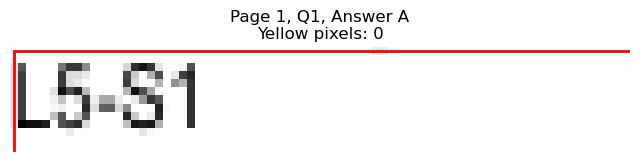

Page 1, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=93.9, y1=127.3
Page 1, Q1, B: Yellow pixels: 76
Page 1, Q1, B: Total non-white pixels: 175
Page 1, Q1, B: Yellow percentage: 43.4%


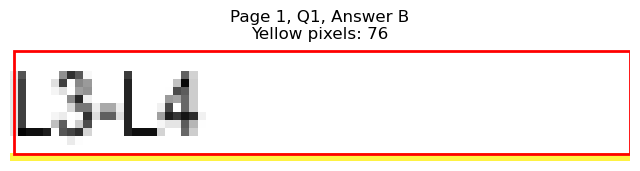

Page 1, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=94.3, y1=139.9
Page 1, Q1, C: Yellow pixels: 913
Page 1, Q1, C: Total non-white pixels: 1001
Page 1, Q1, C: Yellow percentage: 91.2%


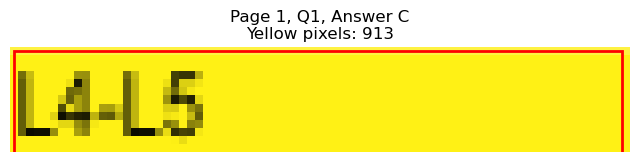

Page 1, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=353.1, y1=114.7
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 76
Page 1, Q1, D: Yellow percentage: 0.0%


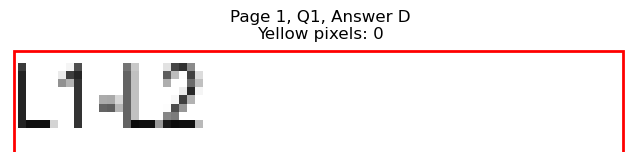

Page 1, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=354.7, y1=127.3
Page 1, Q1, E: Yellow pixels: 0
Page 1, Q1, E: Total non-white pixels: 122
Page 1, Q1, E: Yellow percentage: 0.0%


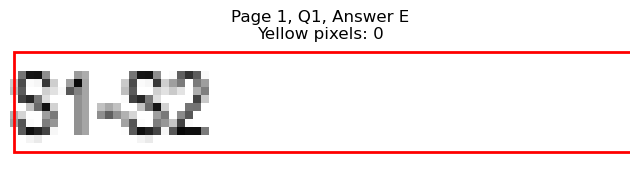


Page 1, Q1 - Selected Answer: C (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=176.2, y1=190.4
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 539
Page 1, Q2, A: Yellow percentage: 0.0%


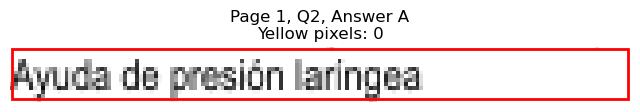

Page 1, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=242.9, y1=203.0
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 892
Page 1, Q2, B: Yellow percentage: 0.0%


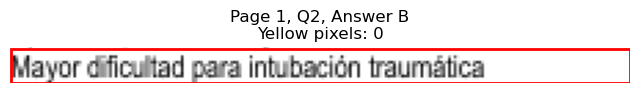

Page 1, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=136.9, y1=215.6
Page 1, Q2, C: Yellow pixels: 0
Page 1, Q2, C: Total non-white pixels: 368
Page 1, Q2, C: Yellow percentage: 0.0%


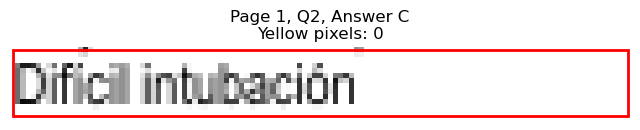

Page 1, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=411.3, y1=190.4
Page 1, Q2, D: Yellow pixels: 135
Page 1, Q2, D: Total non-white pixels: 566
Page 1, Q2, D: Yellow percentage: 23.9%


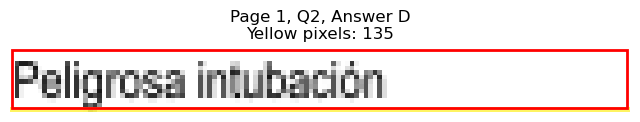

Page 1, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=427.9, y1=203.0
Page 1, Q2, E: Yellow pixels: 1576
Page 1, Q2, E: Total non-white pixels: 1963
Page 1, Q2, E: Yellow percentage: 80.3%


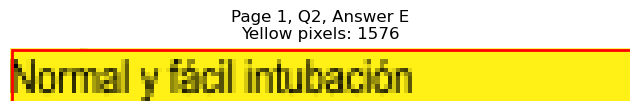


Page 1, Q2 - Selected Answer: E (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=132.1, y1=253.5
Page 1, Q3, A: Yellow pixels: 115
Page 1, Q3, A: Total non-white pixels: 445
Page 1, Q3, A: Yellow percentage: 25.8%


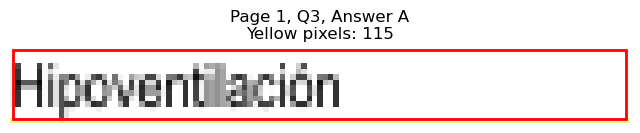

Page 1, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=166.6, y1=266.1
Page 1, Q3, B: Yellow pixels: 1533
Page 1, Q3, B: Total non-white pixels: 2086
Page 1, Q3, B: Yellow percentage: 73.5%


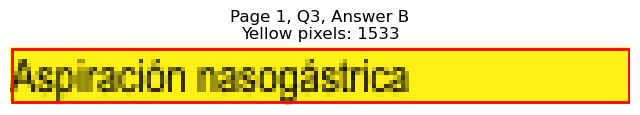

Page 1, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=106.3, y1=278.7
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 276
Page 1, Q3, C: Yellow percentage: 0.0%


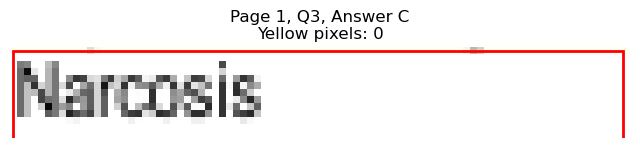

Page 1, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=528.2, y1=253.5
Page 1, Q3, D: Yellow pixels: 0
Page 1, Q3, D: Total non-white pixels: 1004
Page 1, Q3, D: Yellow percentage: 0.0%


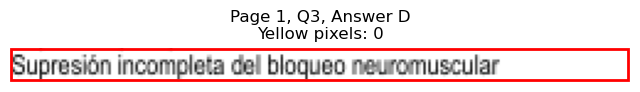

Page 1, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=398.3, y1=266.1
Page 1, Q3, E: Yellow pixels: 0
Page 1, Q3, E: Total non-white pixels: 387
Page 1, Q3, E: Yellow percentage: 0.0%


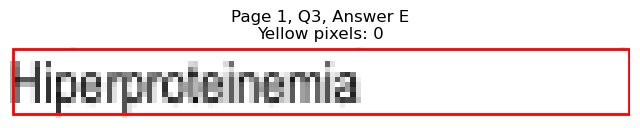


Page 1, Q3 - Selected Answer: B (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=119.4, y1=316.7
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 283
Page 1, Q4, A: Yellow percentage: 0.0%


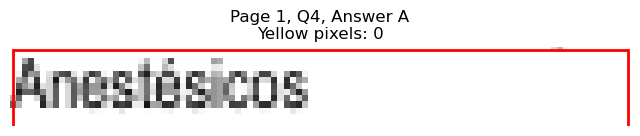

Page 1, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=92.9, y1=329.3
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 145
Page 1, Q4, B: Yellow percentage: 0.0%


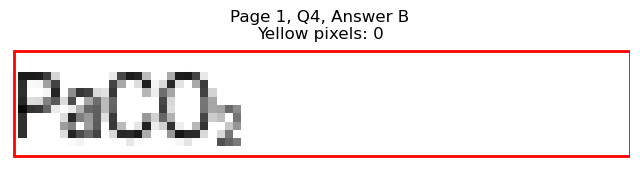

Page 1, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=123.0, y1=341.9
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 256
Page 1, Q4, C: Yellow percentage: 0.0%


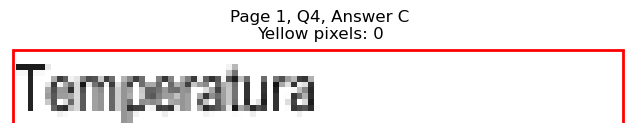

Page 1, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=418.4, y1=316.7
Page 1, Q4, D: Yellow pixels: 3
Page 1, Q4, D: Total non-white pixels: 605
Page 1, Q4, D: Yellow percentage: 0.5%


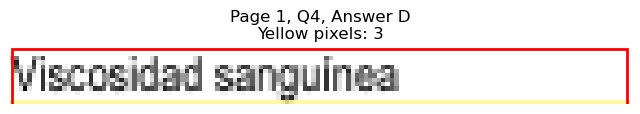

Page 1, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=435.9, y1=329.3
Page 1, Q4, E: Yellow pixels: 1497
Page 1, Q4, E: Total non-white pixels: 2226
Page 1, Q4, E: Yellow percentage: 67.3%


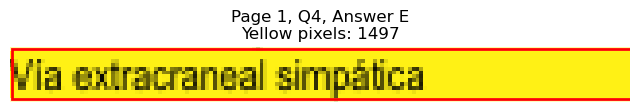


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=80.9, y1=405.0
Page 1, Q5, A: Yellow pixels: 771
Page 1, Q5, A: Total non-white pixels: 819
Page 1, Q5, A: Yellow percentage: 94.1%


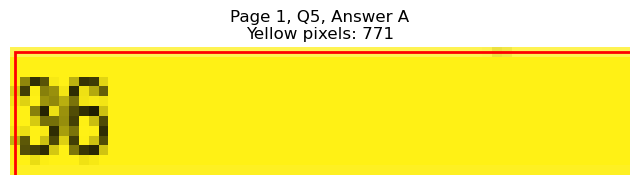

Page 1, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=80.9, y1=417.6
Page 1, Q5, B: Yellow pixels: 63
Page 1, Q5, B: Total non-white pixels: 121
Page 1, Q5, B: Yellow percentage: 52.1%


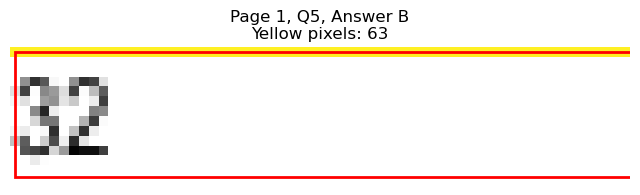

Page 1, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=81.4, y1=430.3
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 60
Page 1, Q5, C: Yellow percentage: 0.0%


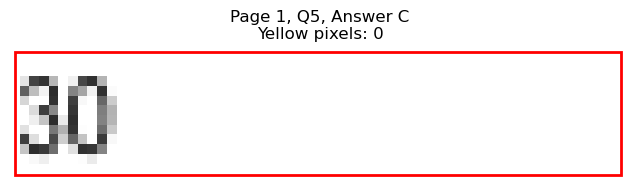

Page 1, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=340.1, y1=405.0
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 60
Page 1, Q5, D: Yellow percentage: 0.0%


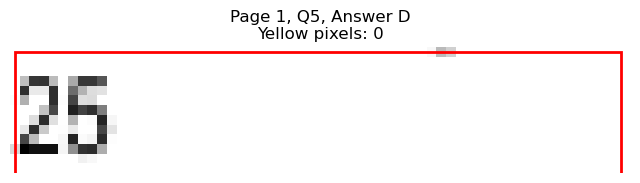

Page 1, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=339.7, y1=417.6
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 63
Page 1, Q5, E: Yellow percentage: 0.0%


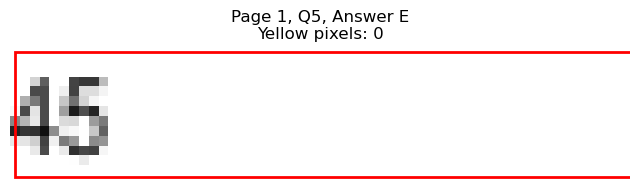


Page 1, Q5 - Selected Answer: A (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=146.1, y1=468.1
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 401
Page 1, Q6, A: Yellow percentage: 0.0%


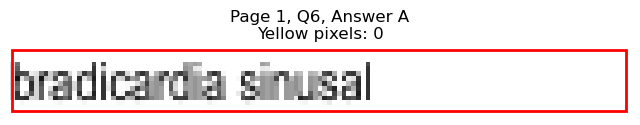

Page 1, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=145.6, y1=480.7
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 368
Page 1, Q6, B: Yellow percentage: 0.0%


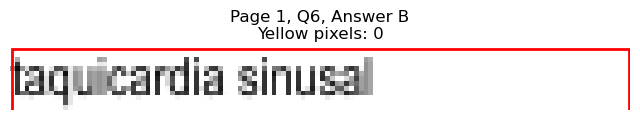

Page 1, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=153.5, y1=493.4
Page 1, Q6, C: Yellow pixels: 1262
Page 1, Q6, C: Total non-white pixels: 1904
Page 1, Q6, C: Yellow percentage: 66.3%


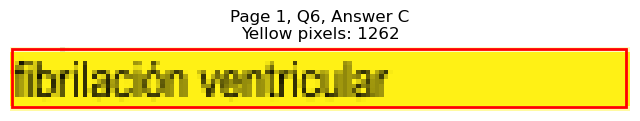

Page 1, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=430.9, y1=468.1
Page 1, Q6, D: Yellow pixels: 0
Page 1, Q6, D: Total non-white pixels: 551
Page 1, Q6, D: Yellow percentage: 0.0%


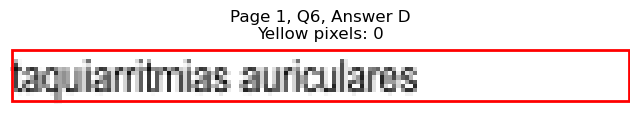

Page 1, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=398.5, y1=480.7
Page 1, Q6, E: Yellow pixels: 0
Page 1, Q6, E: Total non-white pixels: 367
Page 1, Q6, E: Yellow percentage: 0.0%


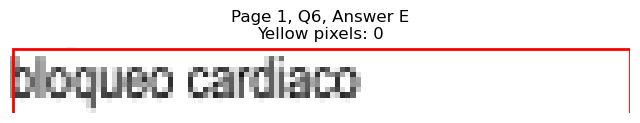


Page 1, Q6 - Selected Answer: C (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=169.9, y0=518.6, x1=244.8, y1=531.2
Page 1, Q7, A: Yellow pixels: 1227
Page 1, Q7, A: Total non-white pixels: 1582
Page 1, Q7, A: Yellow percentage: 77.6%


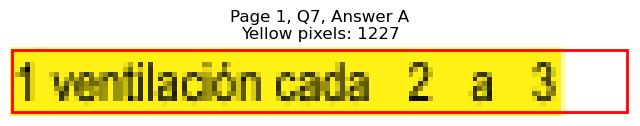

Page 1, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=208.8, y1=556.4
Page 1, Q7, B: Yellow pixels: 187
Page 1, Q7, B: Total non-white pixels: 884
Page 1, Q7, B: Yellow percentage: 21.2%


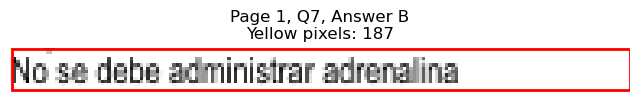

Page 1, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=246.9, y1=569.2
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 881
Page 1, Q7, C: Yellow percentage: 0.0%


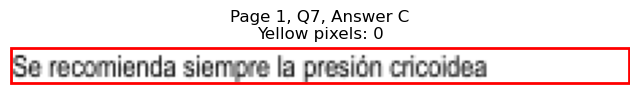

Page 1, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=518.1, y1=531.2
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 913
Page 1, Q7, D: Yellow percentage: 0.0%


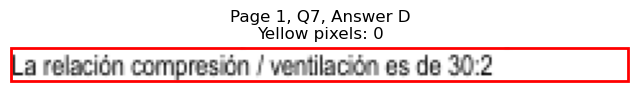

Page 1, Q7 - E: Detected box: x0=327.0, y0=531.2, x1=418.9, y1=543.8
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 499
Page 1, Q7, E: Yellow percentage: 0.0%


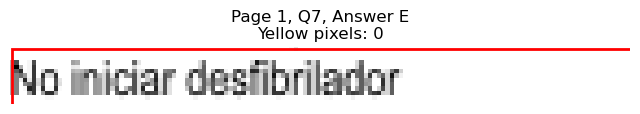


Page 1, Q7 - Selected Answer: A (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=282.2, y1=619.6
Page 1, Q8, A: Yellow pixels: 2005
Page 1, Q8, A: Total non-white pixels: 3065
Page 1, Q8, A: Yellow percentage: 65.4%


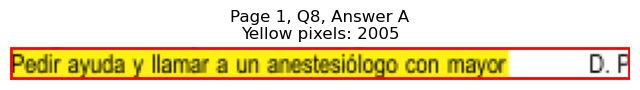

Page 1, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=235.4, y1=644.9
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 1073
Page 1, Q8, B: Yellow percentage: 0.0%


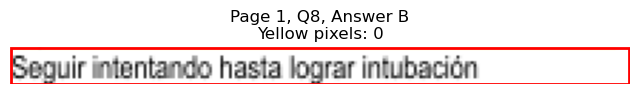

Page 1, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=194.7, y1=657.5
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 670
Page 1, Q8, C: Yellow percentage: 0.0%


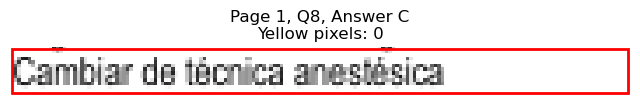

Page 1, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=436.9, y1=619.6
Page 1, Q8, D: Yellow pixels: 0
Page 1, Q8, D: Total non-white pixels: 564
Page 1, Q8, D: Yellow percentage: 0.0%


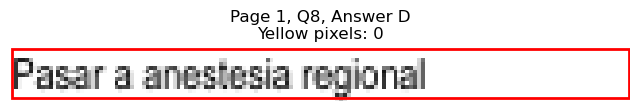

Page 1, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=407.9, y1=632.3
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 409
Page 1, Q8, E: Yellow percentage: 0.0%


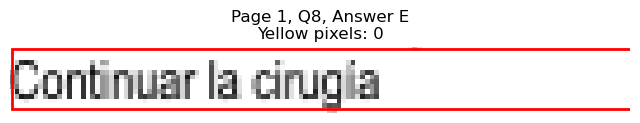


Page 1, Q8 - Selected Answer: A (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=102.9, y1=695.3
Page 1, Q9, A: Yellow pixels: 879
Page 1, Q9, A: Total non-white pixels: 1190
Page 1, Q9, A: Yellow percentage: 73.9%


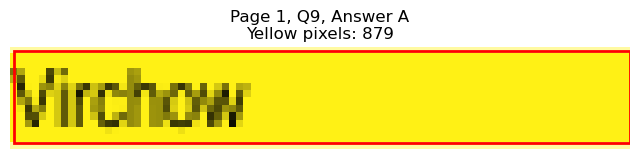

Page 1, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=91.8, y1=708.0
Page 1, Q9, B: Yellow pixels: 0
Page 1, Q9, B: Total non-white pixels: 212
Page 1, Q9, B: Yellow percentage: 0.0%


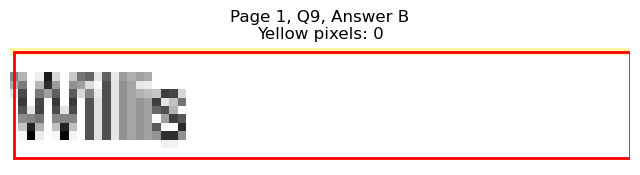

Page 1, Q9 - C: Detected box: x0=68.8, y0=708.0, x1=98.9, y1=720.6
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 139
Page 1, Q9, C: Yellow percentage: 0.0%


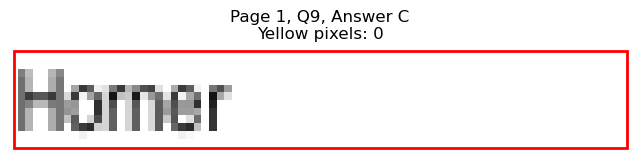

Page 1, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=366.2, y1=695.3
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 193
Page 1, Q9, D: Yellow percentage: 0.0%


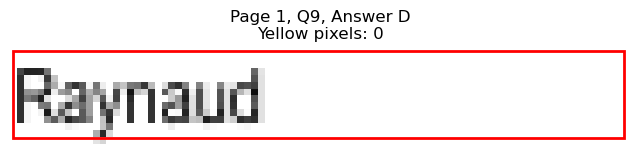

Page 1, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=346.1, y1=708.0
Page 1, Q9, E: Yellow pixels: 0
Page 1, Q9, E: Total non-white pixels: 91
Page 1, Q9, E: Yellow percentage: 0.0%


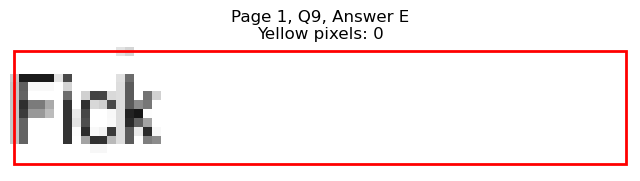


Page 1, Q9 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 9 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=107.9, y1=114.7
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 178
Page 2, Q1, A: Yellow percentage: 0.0%


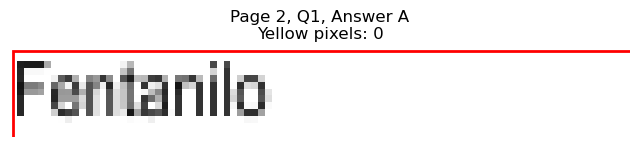

Page 2, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=126.0, y1=127.3
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 291
Page 2, Q1, B: Yellow percentage: 0.0%


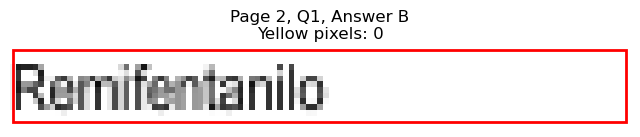

Page 2, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=116.4, y1=139.9
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 265
Page 2, Q1, C: Yellow percentage: 0.0%


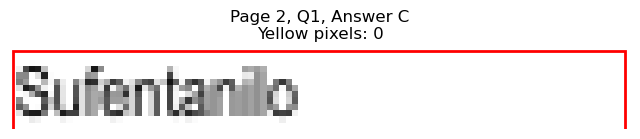

Page 2, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=360.2, y1=114.7
Page 2, Q1, D: Yellow pixels: 959
Page 2, Q1, D: Total non-white pixels: 1092
Page 2, Q1, D: Yellow percentage: 87.8%


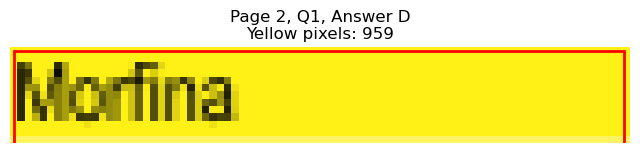

Page 2, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=367.7, y1=127.3
Page 2, Q1, E: Yellow pixels: 91
Page 2, Q1, E: Total non-white pixels: 282
Page 2, Q1, E: Yellow percentage: 32.3%


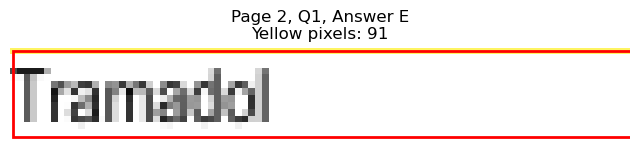


Page 2, Q1 - Selected Answer: D (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=187.3, y1=190.4
Page 2, Q2, A: Yellow pixels: 1353
Page 2, Q2, A: Total non-white pixels: 2380
Page 2, Q2, A: Yellow percentage: 56.8%


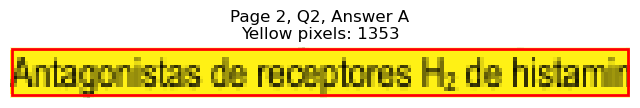

Page 2, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=187.2, y1=203.0
Page 2, Q2, B: Yellow pixels: 2
Page 2, Q2, B: Total non-white pixels: 1019
Page 2, Q2, B: Yellow percentage: 0.2%


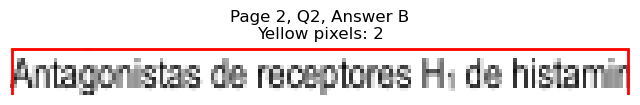

Page 2, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=233.3, y1=215.6
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 823
Page 2, Q2, C: Yellow percentage: 0.0%


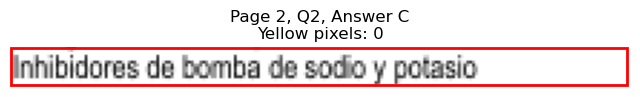

Page 2, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=476.6, y1=190.4
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 739
Page 2, Q2, D: Yellow percentage: 0.0%


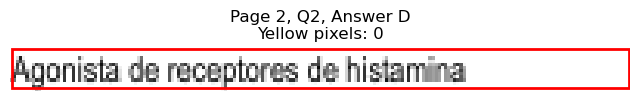

Page 2, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=452.9, y1=203.0
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 607
Page 2, Q2, E: Yellow percentage: 0.0%


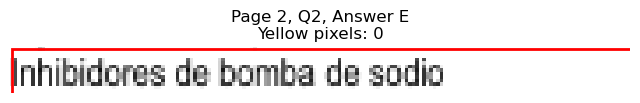


Page 2, Q2 - Selected Answer: A (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=109.5, y1=253.5
Page 2, Q3, A: Yellow pixels: 1013
Page 2, Q3, A: Total non-white pixels: 1288
Page 2, Q3, A: Yellow percentage: 78.6%


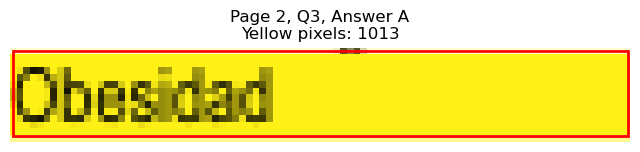

Page 2, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=118.0, y1=266.1
Page 2, Q3, B: Yellow pixels: 100
Page 2, Q3, B: Total non-white pixels: 366
Page 2, Q3, B: Yellow percentage: 27.3%


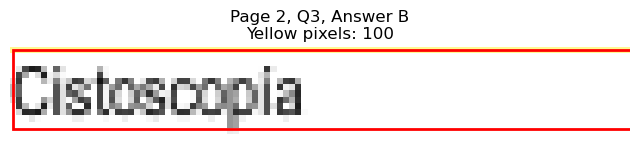

Page 2, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=134.5, y1=278.7
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 336
Page 2, Q3, C: Yellow percentage: 0.0%


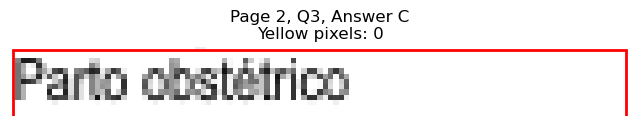

Page 2, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=483.1, y1=253.5
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 737
Page 2, Q3, D: Yellow percentage: 0.0%


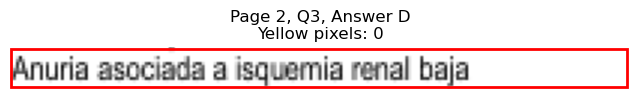

Page 2, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=383.2, y1=266.1
Page 2, Q3, E: Yellow pixels: 0
Page 2, Q3, E: Total non-white pixels: 266
Page 2, Q3, E: Yellow percentage: 0.0%


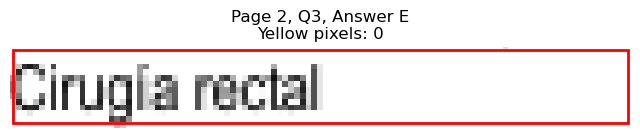


Page 2, Q3 - Selected Answer: A (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=166.6, y1=316.7
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 473
Page 2, Q4, A: Yellow percentage: 0.0%


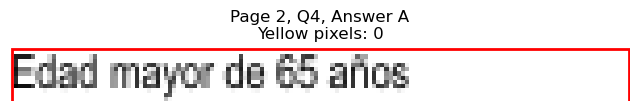

Page 2, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=178.6, y1=329.3
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 543
Page 2, Q4, B: Yellow percentage: 0.0%


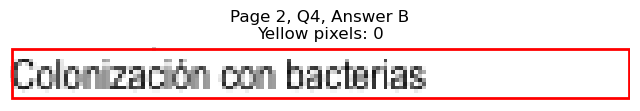

Page 2, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=227.8, y1=341.9
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 798
Page 2, Q4, C: Yellow percentage: 0.0%


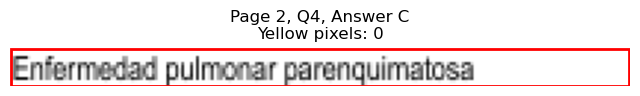

Page 2, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=497.0, y1=316.7
Page 2, Q4, D: Yellow pixels: 2089
Page 2, Q4, D: Total non-white pixels: 2782
Page 2, Q4, D: Yellow percentage: 75.1%


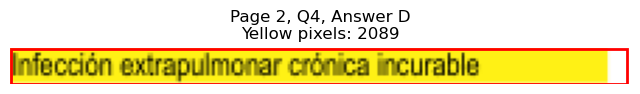

Page 2, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=471.5, y1=329.3
Page 2, Q4, E: Yellow pixels: 195
Page 2, Q4, E: Total non-white pixels: 892
Page 2, Q4, E: Yellow percentage: 21.9%


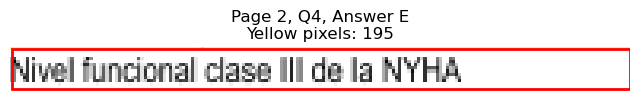


Page 2, Q4 - Selected Answer: D (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=264.4, y1=379.8
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 961
Page 2, Q5, A: Yellow percentage: 0.0%


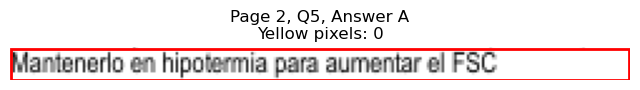

Page 2, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=431.0, y1=392.4
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 1780
Page 2, Q5, B: Yellow percentage: 0.0%


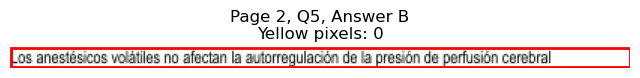

Page 2, Q5 - C: Detected box: x0=68.8, y0=392.3, x1=355.1, y1=405.0
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 1385
Page 2, Q5, C: Yellow percentage: 0.0%


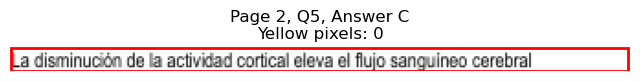

Page 2, Q5 - D: Detected box: x0=68.8, y0=404.9, x1=284.6, y1=417.6
Page 2, Q5, D: Yellow pixels: 0
Page 2, Q5, D: Total non-white pixels: 1053
Page 2, Q5, D: Yellow percentage: 0.0%


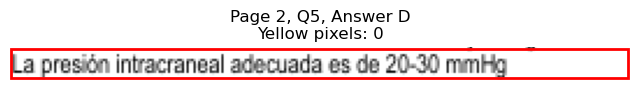

Page 2, Q5 - E: Detected box: x0=68.3, y0=417.6, x1=354.4, y1=430.3
Page 2, Q5, E: Yellow pixels: 2949
Page 2, Q5, E: Total non-white pixels: 4718
Page 2, Q5, E: Yellow percentage: 62.5%


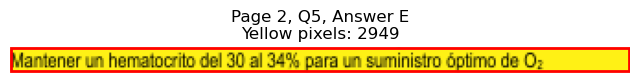


Page 2, Q5 - Selected Answer: E (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=92.4, y1=468.1
Page 2, Q6, A: Yellow pixels: 75
Page 2, Q6, A: Total non-white pixels: 175
Page 2, Q6, A: Yellow percentage: 42.9%


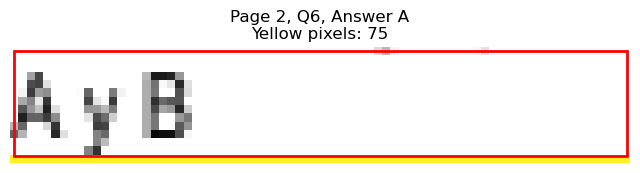

Page 2, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=93.4, y1=480.7
Page 2, Q6, B: Yellow pixels: 905
Page 2, Q6, B: Total non-white pixels: 988
Page 2, Q6, B: Yellow percentage: 91.6%


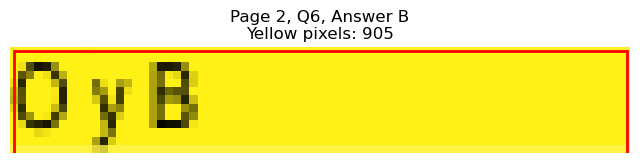

Page 2, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=98.9, y1=493.4
Page 2, Q6, C: Yellow pixels: 81
Page 2, Q6, C: Total non-white pixels: 207
Page 2, Q6, C: Yellow percentage: 39.1%


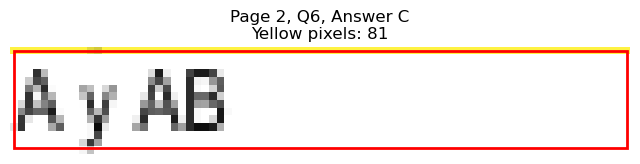

Page 2, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=357.7, y1=468.1
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 139
Page 2, Q6, D: Yellow percentage: 0.0%


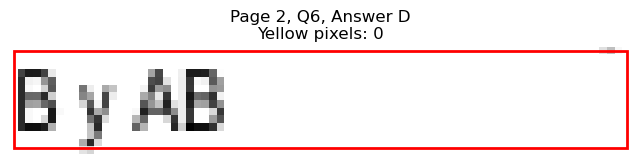

Page 2, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=358.1, y1=480.7
Page 2, Q6, E: Yellow pixels: 0
Page 2, Q6, E: Total non-white pixels: 134
Page 2, Q6, E: Yellow percentage: 0.0%


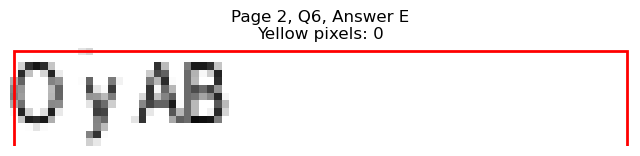


Page 2, Q6 - Selected Answer: B (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=259.0, y1=556.4
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 968
Page 2, Q7, A: Yellow percentage: 0.0%


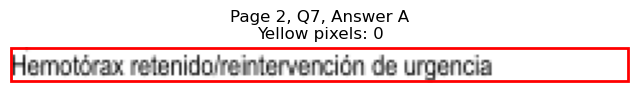

Page 2, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=208.8, y1=569.2
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 751
Page 2, Q7, B: Yellow percentage: 0.0%


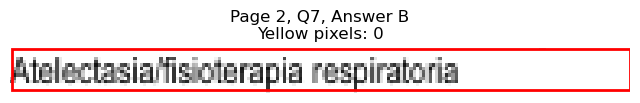

Page 2, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=150.5, y1=581.8
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 408
Page 2, Q7, C: Yellow percentage: 0.0%


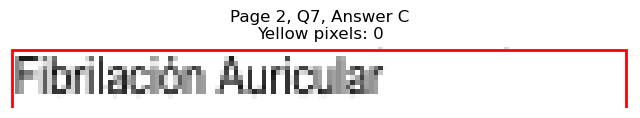

Page 2, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=449.3, y1=556.4
Page 2, Q7, D: Yellow pixels: 1752
Page 2, Q7, D: Total non-white pixels: 2422
Page 2, Q7, D: Yellow percentage: 72.3%


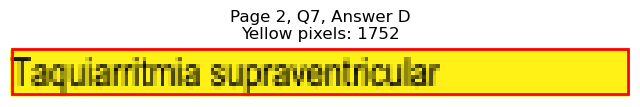

Page 2, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=444.4, y1=569.2
Page 2, Q7, E: Yellow pixels: 168
Page 2, Q7, E: Total non-white pixels: 754
Page 2, Q7, E: Yellow percentage: 22.3%


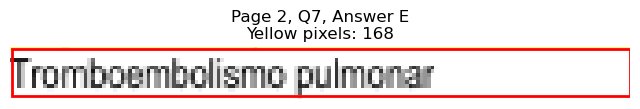


Page 2, Q7 - Selected Answer: D (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=140.5, y1=632.3
Page 2, Q8, A: Yellow pixels: 123
Page 2, Q8, A: Total non-white pixels: 507
Page 2, Q8, A: Yellow percentage: 24.3%


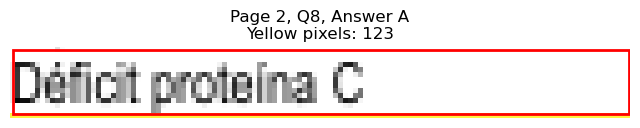

Page 2, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=143.1, y1=644.9
Page 2, Q8, B: Yellow pixels: 1305
Page 2, Q8, B: Total non-white pixels: 1638
Page 2, Q8, B: Yellow percentage: 79.7%


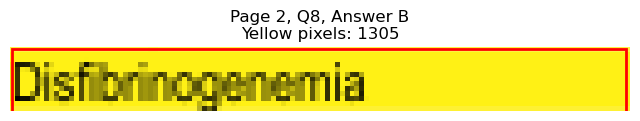

Page 2, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=140.5, y1=657.5
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 355
Page 2, Q8, C: Yellow percentage: 0.0%


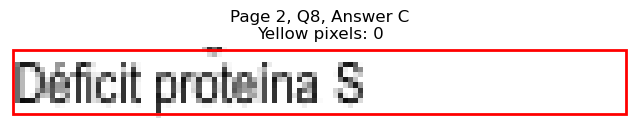

Page 2, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=500.1, y1=632.3
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 910
Page 2, Q8, D: Yellow percentage: 0.0%


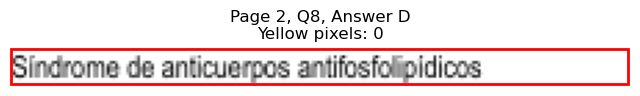

Page 2, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=486.1, y1=644.9
Page 2, Q8, E: Yellow pixels: 0
Page 2, Q8, E: Total non-white pixels: 790
Page 2, Q8, E: Yellow percentage: 0.0%


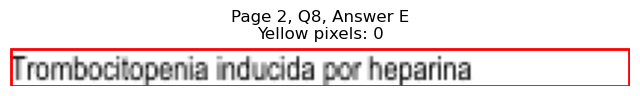


Page 2, Q8 - Selected Answer: B (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=87.4, y1=695.3
Page 2, Q9, A: Yellow pixels: 0
Page 2, Q9, A: Total non-white pixels: 89
Page 2, Q9, A: Yellow percentage: 0.0%


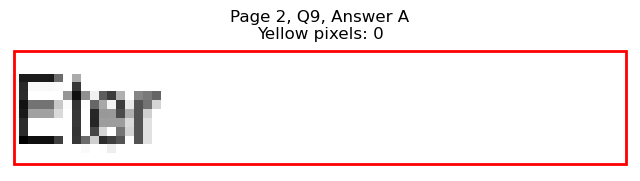

Page 2, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=118.9, y1=708.0
Page 2, Q9, B: Yellow pixels: 1129
Page 2, Q9, B: Total non-white pixels: 1313
Page 2, Q9, B: Yellow percentage: 86.0%


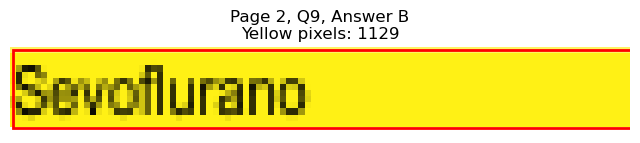

Page 2, Q9 - C: Detected box: x0=68.8, y0=708.0, x1=107.4, y1=720.6
Page 2, Q9, C: Yellow pixels: 90
Page 2, Q9, C: Total non-white pixels: 285
Page 2, Q9, C: Yellow percentage: 31.6%


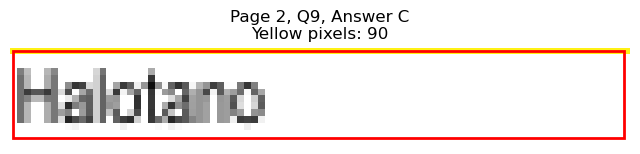

Page 2, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=368.7, y1=695.3
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 201
Page 2, Q9, D: Yellow percentage: 0.0%


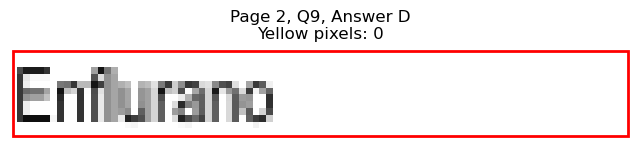

Page 2, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=371.8, y1=708.0
Page 2, Q9, E: Yellow pixels: 0
Page 2, Q9, E: Total non-white pixels: 227
Page 2, Q9, E: Yellow percentage: 0.0%


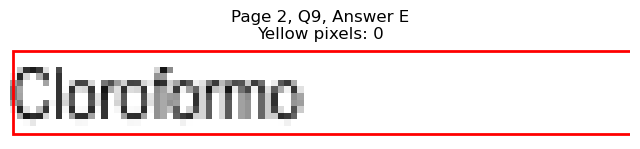


Page 2, Q9 - Selected Answer: B (based on yellow pixel count)





Page 3: Found 10 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=136.6, y1=102.1
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 331
Page 3, Q1, A: Yellow percentage: 0.0%


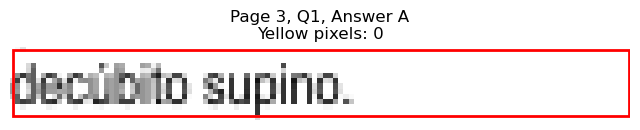

Page 3, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=133.0, y1=114.7
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 332
Page 3, Q1, B: Yellow percentage: 0.0%


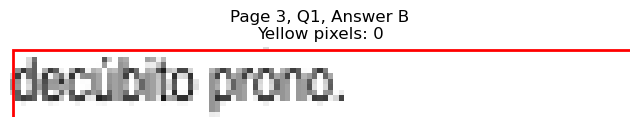

Page 3, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=98.4, y1=127.3
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 143
Page 3, Q1, C: Yellow percentage: 0.0%


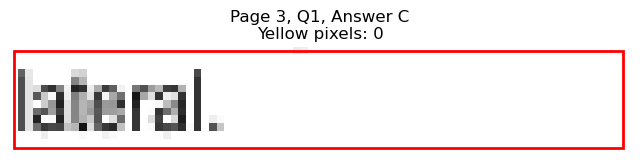

Page 3, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=364.6, y1=102.1
Page 3, Q1, D: Yellow pixels: 88
Page 3, Q1, D: Total non-white pixels: 268
Page 3, Q1, D: Yellow percentage: 32.8%


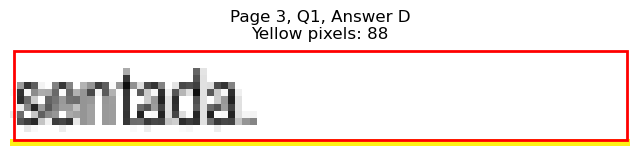

Page 3, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=376.3, y1=114.7
Page 3, Q1, E: Yellow pixels: 1091
Page 3, Q1, E: Total non-white pixels: 1300
Page 3, Q1, E: Yellow percentage: 83.9%


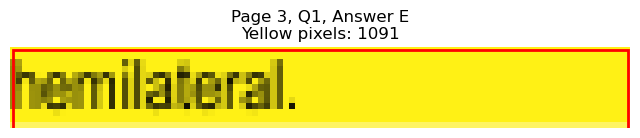


Page 3, Q1 - Selected Answer: E (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=56.6, y0=165.1, x1=65.2, y1=177.8
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 61
Page 3, Q2, A: Yellow percentage: 0.0%


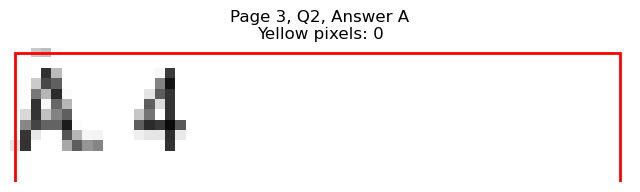

Page 3, Q2 - B: Detected box: x0=56.6, y0=177.7, x1=65.2, y1=190.4
Page 3, Q2, B: Yellow pixels: 0
Page 3, Q2, B: Total non-white pixels: 69
Page 3, Q2, B: Yellow percentage: 0.0%


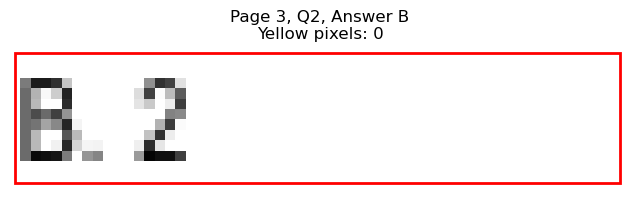

Page 3, Q2 - C: Detected box: x0=56.6, y0=190.3, x1=65.6, y1=203.0
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 70
Page 3, Q2, C: Yellow percentage: 0.0%


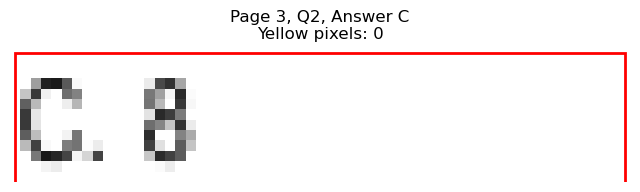

Page 3, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=342.7, y1=177.8
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 128
Page 3, Q2, D: Yellow percentage: 0.0%


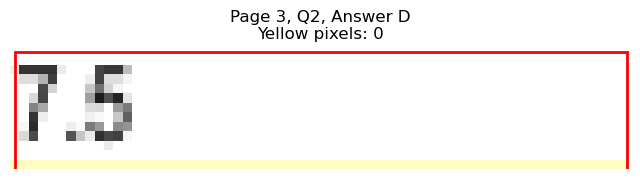

Page 3, Q2 - E: Detected box: x0=315.4, y0=177.7, x1=323.9, y1=190.4
Page 3, Q2, E: Yellow pixels: 654
Page 3, Q2, E: Total non-white pixels: 826
Page 3, Q2, E: Yellow percentage: 79.2%


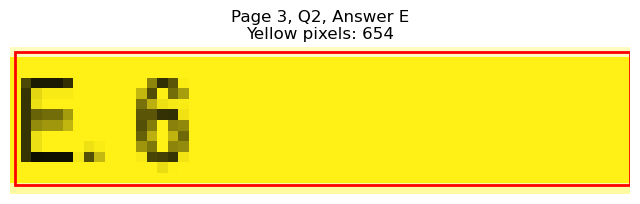


Page 3, Q2 - Selected Answer: E (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=169.1, y1=240.9
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 519
Page 3, Q3, A: Yellow percentage: 0.0%


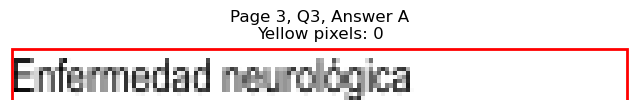

Page 3, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=190.3, y1=253.5
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 618
Page 3, Q3, B: Yellow percentage: 0.0%


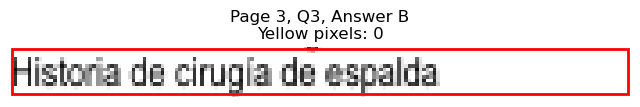

Page 3, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=183.6, y1=266.1
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 575
Page 3, Q3, C: Yellow percentage: 0.0%


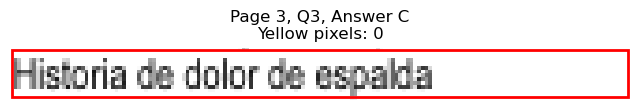

Page 3, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=406.4, y1=240.9
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 540
Page 3, Q3, D: Yellow percentage: 0.0%


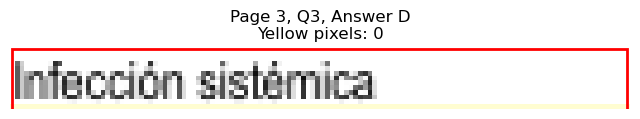

Page 3, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=443.9, y1=253.5
Page 3, Q3, E: Yellow pixels: 1712
Page 3, Q3, E: Total non-white pixels: 2338
Page 3, Q3, E: Yellow percentage: 73.2%


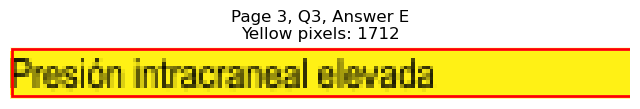


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=106.5, y1=304.1
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 222
Page 3, Q4, A: Yellow percentage: 0.0%


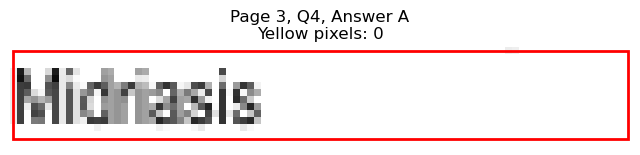

Page 3, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=115.5, y1=316.7
Page 3, Q4, B: Yellow pixels: 0
Page 3, Q4, B: Total non-white pixels: 245
Page 3, Q4, B: Yellow percentage: 0.0%


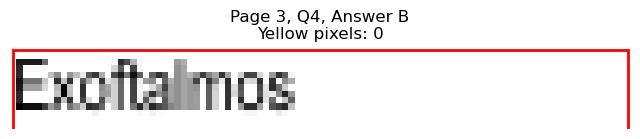

Page 3, Q4 - C: Detected box: x0=68.8, y0=316.6, x1=206.2, y1=329.3
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 659
Page 3, Q4, C: Yellow percentage: 0.0%


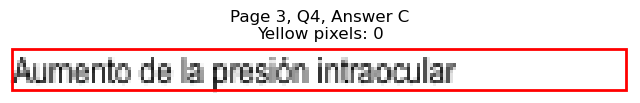

Page 3, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=376.1, y1=304.1
Page 3, Q4, D: Yellow pixels: 100
Page 3, Q4, D: Total non-white pixels: 347
Page 3, Q4, D: Yellow percentage: 28.8%


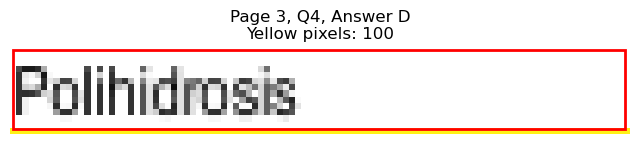

Page 3, Q4 - E: Detected box: x0=327.0, y0=304.0, x1=411.3, y1=316.7
Page 3, Q4, E: Yellow pixels: 1457
Page 3, Q4, E: Total non-white pixels: 1755
Page 3, Q4, E: Yellow percentage: 83.0%


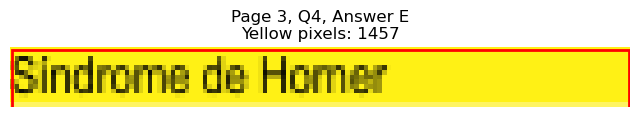


Page 3, Q4 - Selected Answer: E (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=160.6, y1=379.8
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 464
Page 3, Q5, A: Yellow percentage: 0.0%


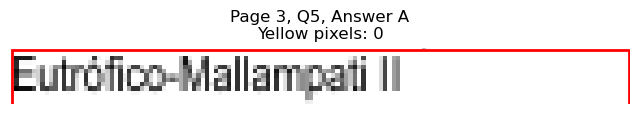

Page 3, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=149.1, y1=392.4
Page 3, Q5, B: Yellow pixels: 132
Page 3, Q5, B: Total non-white pixels: 538
Page 3, Q5, B: Yellow percentage: 24.5%


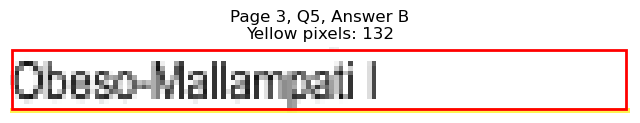

Page 3, Q5 - C: Detected box: x0=68.8, y0=392.3, x1=191.2, y1=405.0
Page 3, Q5, C: Yellow pixels: 1773
Page 3, Q5, C: Total non-white pixels: 2262
Page 3, Q5, C: Yellow percentage: 78.4%


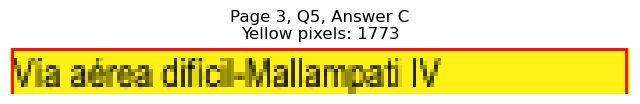

Page 3, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=438.9, y1=379.8
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 544
Page 3, Q5, D: Yellow percentage: 0.0%


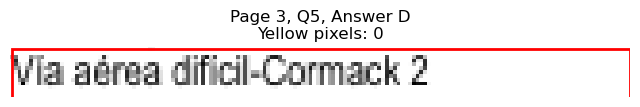

Page 3, Q5 - E: Detected box: x0=327.0, y0=379.7, x1=410.9, y1=392.4
Page 3, Q5, E: Yellow pixels: 0
Page 3, Q5, E: Total non-white pixels: 415
Page 3, Q5, E: Yellow percentage: 0.0%


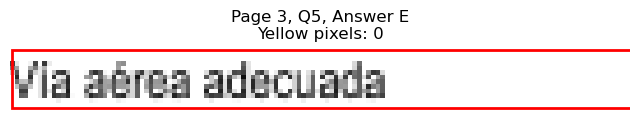


Page 3, Q5 - Selected Answer: C (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=109.0, y1=455.5
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 195
Page 3, Q6, A: Yellow percentage: 0.0%


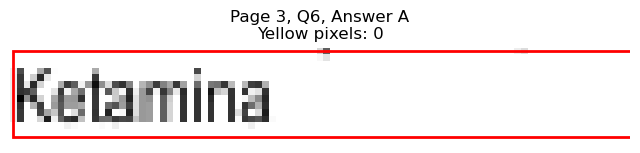

Page 3, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=121.5, y1=468.1
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 276
Page 3, Q6, B: Yellow percentage: 0.0%


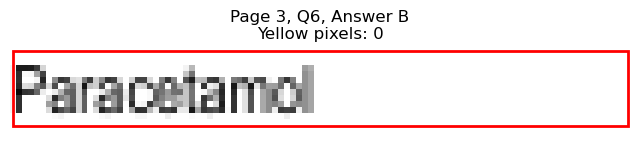

Page 3, Q6 - C: Detected box: x0=68.8, y0=468.1, x1=109.5, y1=480.7
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 202
Page 3, Q6, C: Yellow percentage: 0.0%


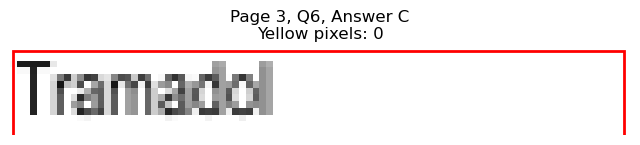

Page 3, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=377.2, y1=455.5
Page 3, Q6, D: Yellow pixels: 101
Page 3, Q6, D: Total non-white pixels: 368
Page 3, Q6, D: Yellow percentage: 27.4%


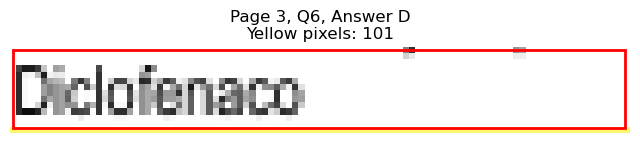

Page 3, Q6 - E: Detected box: x0=327.0, y0=455.5, x1=377.7, y1=468.1
Page 3, Q6, E: Yellow pixels: 1083
Page 3, Q6, E: Total non-white pixels: 1414
Page 3, Q6, E: Yellow percentage: 76.6%


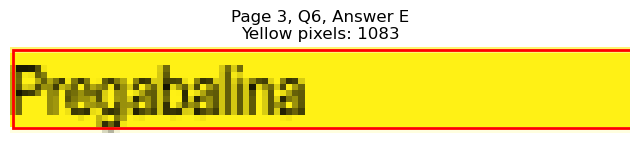


Page 3, Q6 - Selected Answer: E (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=116.9, y1=531.2
Page 3, Q7, A: Yellow pixels: 99
Page 3, Q7, A: Total non-white pixels: 370
Page 3, Q7, A: Yellow percentage: 26.8%


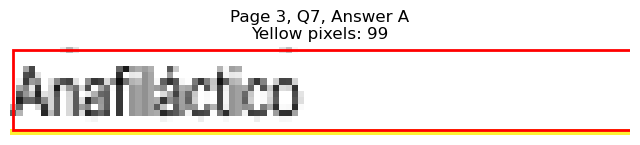

Page 3, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=124.9, y1=543.8
Page 3, Q7, B: Yellow pixels: 1180
Page 3, Q7, B: Total non-white pixels: 1391
Page 3, Q7, B: Yellow percentage: 84.8%


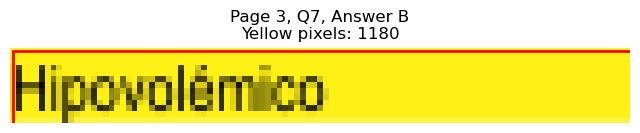

Page 3, Q7 - C: Detected box: x0=68.8, y0=543.8, x1=124.5, y1=556.4
Page 3, Q7, C: Yellow pixels: 106
Page 3, Q7, C: Total non-white pixels: 396
Page 3, Q7, C: Yellow percentage: 26.8%


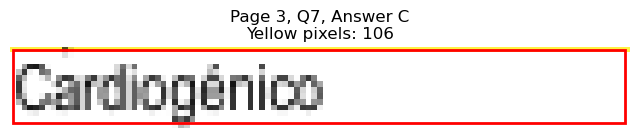

Page 3, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=381.2, y1=531.2
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 288
Page 3, Q7, D: Yellow percentage: 0.0%


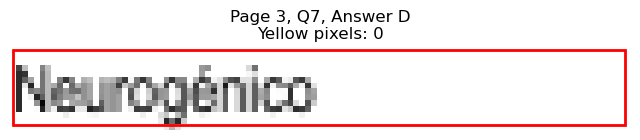

Page 3, Q7 - E: Detected box: x0=327.0, y0=531.2, x1=374.2, y1=543.8
Page 3, Q7, E: Yellow pixels: 0
Page 3, Q7, E: Total non-white pixels: 254
Page 3, Q7, E: Yellow percentage: 0.0%


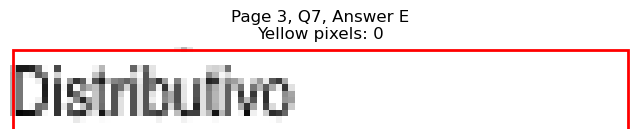


Page 3, Q7 - Selected Answer: B (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=581.7, x1=178.7, y1=594.4
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 569
Page 3, Q8, A: Yellow percentage: 0.0%


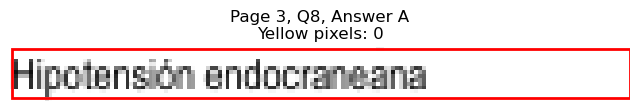

Page 3, Q8 - B: Detected box: x0=68.3, y0=594.3, x1=151.6, y1=607.0
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 441
Page 3, Q8, B: Yellow percentage: 0.0%


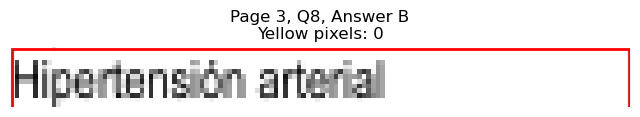

Page 3, Q8 - C: Detected box: x0=68.8, y0=606.9, x1=149.2, y1=619.6
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 399
Page 3, Q8, C: Yellow percentage: 0.0%


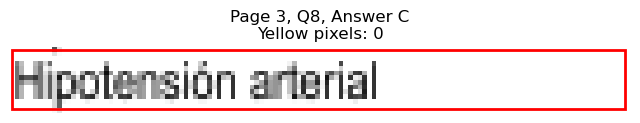

Page 3, Q8 - D: Detected box: x0=327.5, y0=581.7, x1=375.7, y1=594.4
Page 3, Q8, D: Yellow pixels: 99
Page 3, Q8, D: Total non-white pixels: 346
Page 3, Q8, D: Yellow percentage: 28.6%


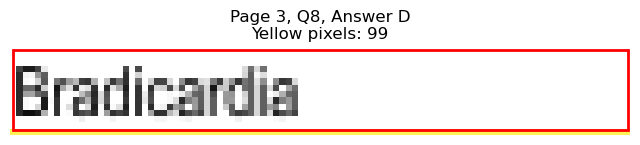

Page 3, Q8 - E: Detected box: x0=327.0, y0=594.3, x1=440.5, y1=607.0
Page 3, Q8, E: Yellow pixels: 1672
Page 3, Q8, E: Total non-white pixels: 2132
Page 3, Q8, E: Yellow percentage: 78.4%


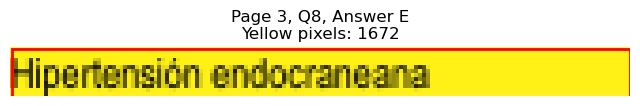


Page 3, Q8 - Selected Answer: E (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=68.3, y0=657.5, x1=112.1, y1=670.1
Page 3, Q9, A: Yellow pixels: 0
Page 3, Q9, A: Total non-white pixels: 196
Page 3, Q9, A: Yellow percentage: 0.0%


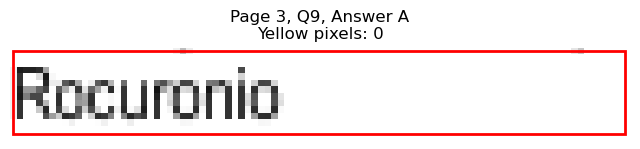

Page 3, Q9 - B: Detected box: x0=68.3, y0=670.1, x1=111.4, y1=682.7
Page 3, Q9, B: Yellow pixels: 0
Page 3, Q9, B: Total non-white pixels: 214
Page 3, Q9, B: Yellow percentage: 0.0%


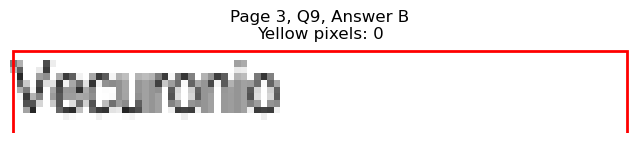

Page 3, Q9 - C: Detected box: x0=68.8, y0=682.7, x1=116.9, y1=695.3
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 213
Page 3, Q9, C: Yellow percentage: 0.0%


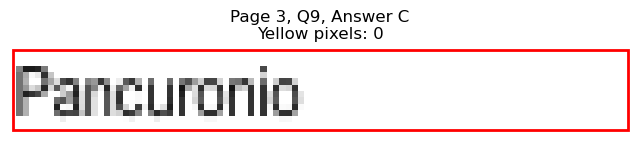

Page 3, Q9 - D: Detected box: x0=327.5, y0=657.5, x1=366.2, y1=670.1
Page 3, Q9, D: Yellow pixels: 1027
Page 3, Q9, D: Total non-white pixels: 1260
Page 3, Q9, D: Yellow percentage: 81.5%


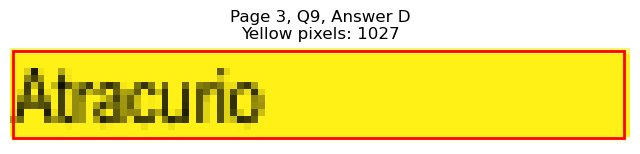

Page 3, Q9 - E: Detected box: x0=327.0, y0=670.1, x1=377.2, y1=682.7
Page 3, Q9, E: Yellow pixels: 0
Page 3, Q9, E: Total non-white pixels: 360
Page 3, Q9, E: Yellow percentage: 0.0%


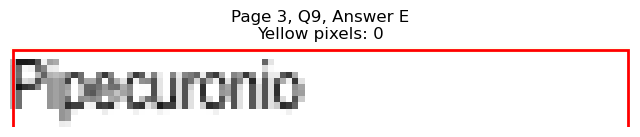


Page 3, Q9 - Selected Answer: D (based on yellow pixel count)




Page 3, Q10 - A: Detected box: x0=68.3, y0=720.6, x1=120.5, y1=733.2
Page 3, Q10, A: Yellow pixels: 103
Page 3, Q10, A: Total non-white pixels: 373
Page 3, Q10, A: Yellow percentage: 27.6%


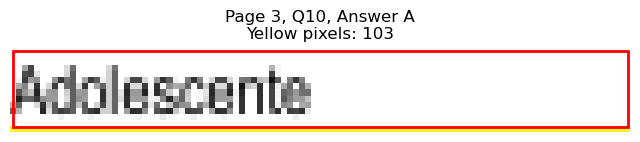

Page 3, Q10 - B: Detected box: x0=68.3, y0=733.2, x1=161.1, y1=745.8
Page 3, Q10, B: Yellow pixels: 1527
Page 3, Q10, B: Total non-white pixels: 1872
Page 3, Q10, B: Yellow percentage: 81.6%


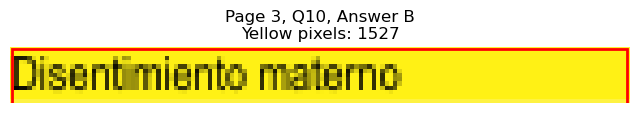

Page 3, Q10 - C: Detected box: x0=68.8, y0=745.8, x1=135.0, y1=758.4
Page 3, Q10, C: Yellow pixels: 118
Page 3, Q10, C: Total non-white pixels: 468
Page 3, Q10, C: Yellow percentage: 25.2%


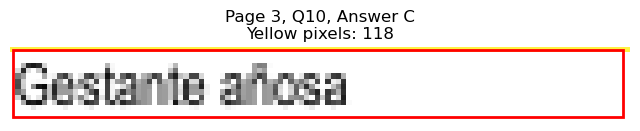

Page 3, Q10 - D: Detected box: x0=327.5, y0=720.6, x1=371.7, y1=733.2
Page 3, Q10, D: Yellow pixels: 0
Page 3, Q10, D: Total non-white pixels: 218
Page 3, Q10, D: Yellow percentage: 0.0%


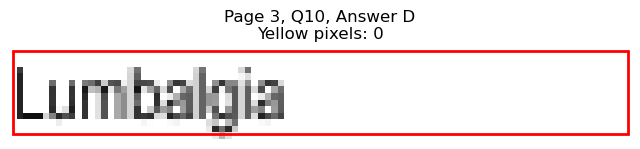

Page 3, Q10 - E: Detected box: x0=327.0, y0=733.2, x1=369.3, y1=745.8
Page 3, Q10, E: Yellow pixels: 0
Page 3, Q10, E: Total non-white pixels: 202
Page 3, Q10, E: Yellow percentage: 0.0%


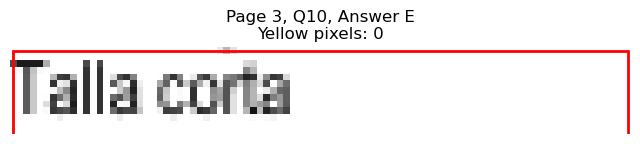


Page 3, Q10 - Selected Answer: B (based on yellow pixel count)





Page 4: Found 10 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=218.8, y1=114.7
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 729
Page 4, Q1, A: Yellow percentage: 0.0%


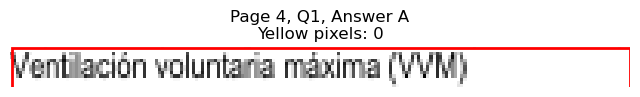

Page 4, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=165.3, y1=127.3
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 478
Page 4, Q1, B: Yellow percentage: 0.0%


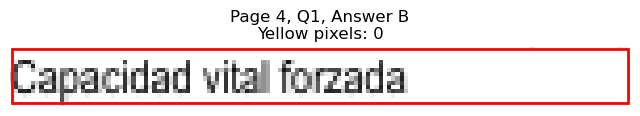

Page 4, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=153.1, y1=139.9
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 434
Page 4, Q1, C: Yellow percentage: 0.0%


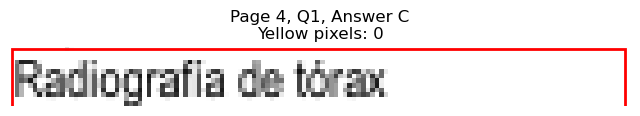

Page 4, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=541.0, y1=114.7
Page 4, Q1, D: Yellow pixels: 1974
Page 4, Q1, D: Total non-white pixels: 2782
Page 4, Q1, D: Yellow percentage: 71.0%


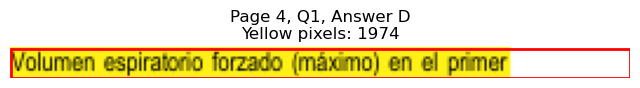

Page 4, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=463.0, y1=139.9
Page 4, Q1, E: Yellow pixels: 0
Page 4, Q1, E: Total non-white pixels: 852
Page 4, Q1, E: Yellow percentage: 0.0%


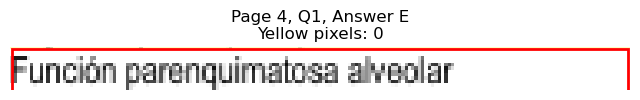


Page 4, Q1 - Selected Answer: D (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=141.0, y1=177.8
Page 4, Q2, A: Yellow pixels: 0
Page 4, Q2, A: Total non-white pixels: 380
Page 4, Q2, A: Yellow percentage: 0.0%


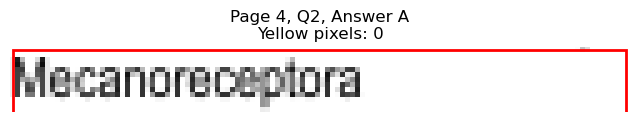

Page 4, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=135.0, y1=190.4
Page 4, Q2, B: Yellow pixels: 118
Page 4, Q2, B: Total non-white pixels: 448
Page 4, Q2, B: Yellow percentage: 26.3%


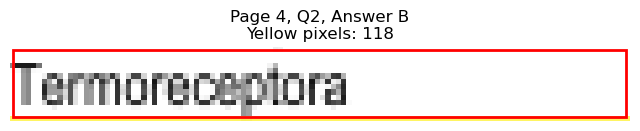

Page 4, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=99.4, y1=203.0
Page 4, Q2, C: Yellow pixels: 933
Page 4, Q2, C: Total non-white pixels: 1066
Page 4, Q2, C: Yellow percentage: 87.5%


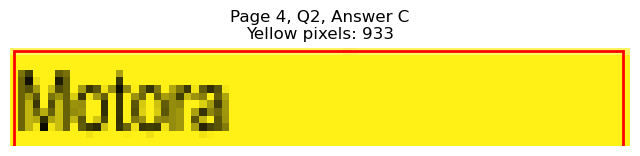

Page 4, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=369.7, y1=177.8
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 216
Page 4, Q2, D: Yellow percentage: 0.0%


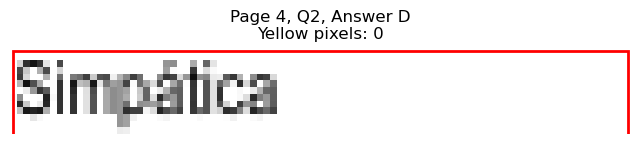

Page 4, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=417.3, y1=190.4
Page 4, Q2, E: Yellow pixels: 0
Page 4, Q2, E: Total non-white pixels: 481
Page 4, Q2, E: Yellow percentage: 0.0%


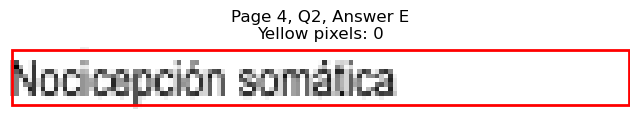


Page 4, Q2 - Selected Answer: C (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=232.8, y1=240.9
Page 4, Q3, A: Yellow pixels: 2092
Page 4, Q3, A: Total non-white pixels: 2782
Page 4, Q3, A: Yellow percentage: 75.2%


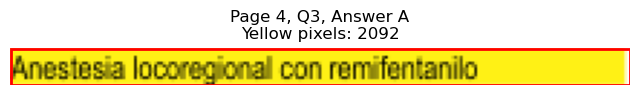

Page 4, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=187.2, y1=253.5
Page 4, Q3, B: Yellow pixels: 166
Page 4, Q3, B: Total non-white pixels: 747
Page 4, Q3, B: Yellow percentage: 22.2%


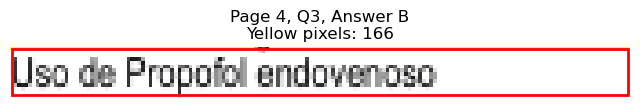

Page 4, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=143.5, y1=266.1
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 390
Page 4, Q3, C: Yellow percentage: 0.0%


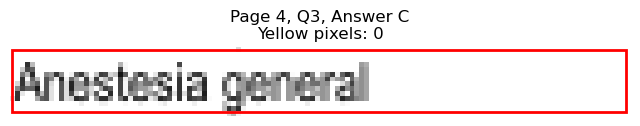

Page 4, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=467.3, y1=240.9
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 699
Page 4, Q3, D: Yellow percentage: 0.0%


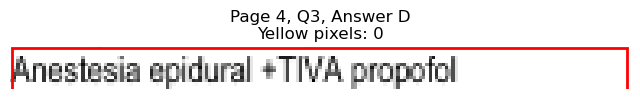

Page 4, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=412.4, y1=253.5
Page 4, Q3, E: Yellow pixels: 0
Page 4, Q3, E: Total non-white pixels: 456
Page 4, Q3, E: Yellow percentage: 0.0%


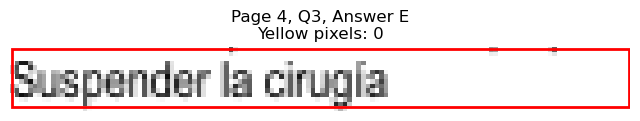


Page 4, Q3 - Selected Answer: A (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=270.4, y1=316.7
Page 4, Q4, A: Yellow pixels: 1977
Page 4, Q4, A: Total non-white pixels: 2813
Page 4, Q4, A: Yellow percentage: 70.3%


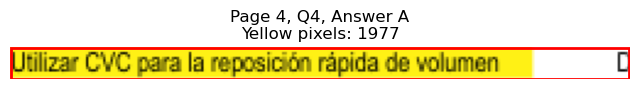

Page 4, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=192.1, y1=329.3
Page 4, Q4, B: Yellow pixels: 175
Page 4, Q4, B: Total non-white pixels: 796
Page 4, Q4, B: Yellow percentage: 22.0%


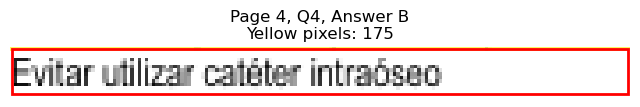

Page 4, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=247.8, y1=341.9
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 885
Page 4, Q4, C: Yellow percentage: 0.0%


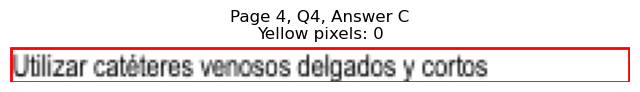

Page 4, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=540.9, y1=316.7
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 1066
Page 4, Q4, D: Yellow percentage: 0.0%


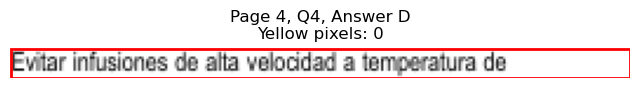

Page 4, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=541.2, y1=341.9
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 1010
Page 4, Q4, E: Yellow percentage: 0.0%


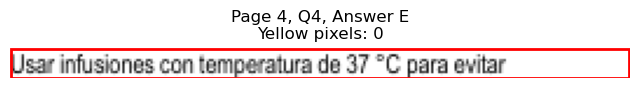


Page 4, Q4 - Selected Answer: A (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=143.5, y1=392.4
Page 4, Q5, A: Yellow pixels: 0
Page 4, Q5, A: Total non-white pixels: 369
Page 4, Q5, A: Yellow percentage: 0.0%


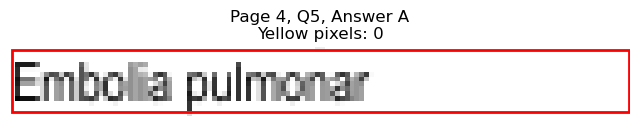

Page 4, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=144.5, y1=405.0
Page 4, Q5, B: Yellow pixels: 0
Page 4, Q5, B: Total non-white pixels: 360
Page 4, Q5, B: Yellow percentage: 0.0%


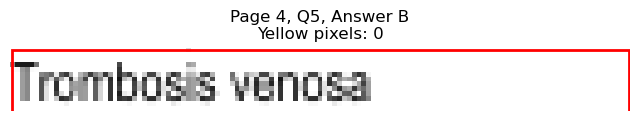

Page 4, Q5 - C: Detected box: x0=68.8, y0=404.9, x1=159.1, y1=417.6
Page 4, Q5, C: Yellow pixels: 0
Page 4, Q5, C: Total non-white pixels: 428
Page 4, Q5, C: Yellow percentage: 0.0%


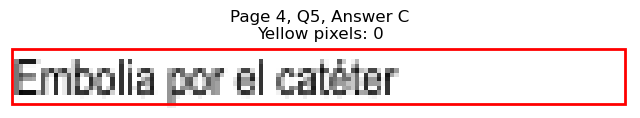

Page 4, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=380.2, y1=392.4
Page 4, Q5, D: Yellow pixels: 104
Page 4, Q5, D: Total non-white pixels: 369
Page 4, Q5, D: Yellow percentage: 28.2%


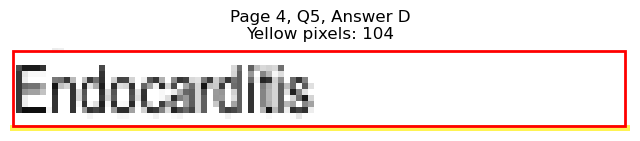

Page 4, Q5 - E: Detected box: x0=327.0, y0=392.3, x1=378.7, y1=405.0
Page 4, Q5, E: Yellow pixels: 1133
Page 4, Q5, E: Total non-white pixels: 1326
Page 4, Q5, E: Yellow percentage: 85.4%


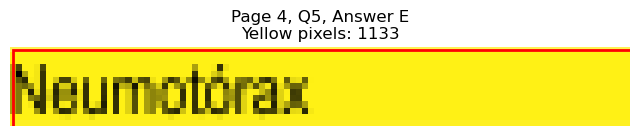


Page 4, Q5 - Selected Answer: E (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=225.3, y1=480.7
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 771
Page 4, Q6, A: Yellow percentage: 0.0%


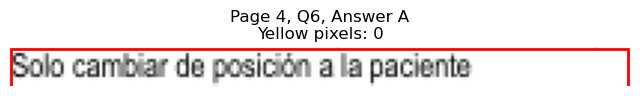

Page 4, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=282.2, y1=493.4
Page 4, Q6, B: Yellow pixels: 1977
Page 4, Q6, B: Total non-white pixels: 3068
Page 4, Q6, B: Yellow percentage: 64.4%


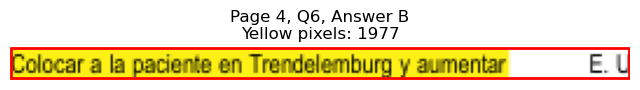

Page 4, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=258.4, y1=518.6
Page 4, Q6, C: Yellow pixels: 213
Page 4, Q6, C: Total non-white pixels: 1073
Page 4, Q6, C: Yellow percentage: 19.9%


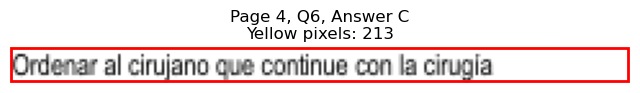

Page 4, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=519.7, y1=480.7
Page 4, Q6, D: Yellow pixels: 0
Page 4, Q6, D: Total non-white pixels: 973
Page 4, Q6, D: Yellow percentage: 0.0%


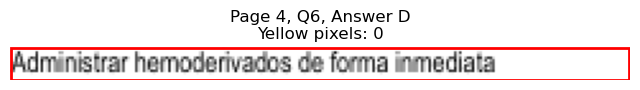

Page 4, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=422.3, y1=493.4
Page 4, Q6, E: Yellow pixels: 0
Page 4, Q6, E: Total non-white pixels: 483
Page 4, Q6, E: Yellow percentage: 0.0%


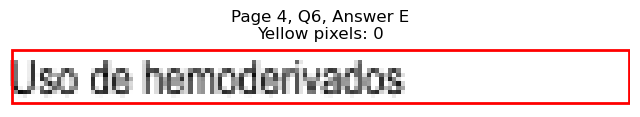


Page 4, Q6 - Selected Answer: B (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=104.9, y1=556.4
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 182
Page 4, Q7, A: Yellow percentage: 0.0%


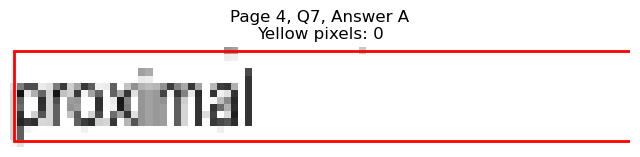

Page 4, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=97.9, y1=569.2
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 139
Page 4, Q7, B: Yellow percentage: 0.0%


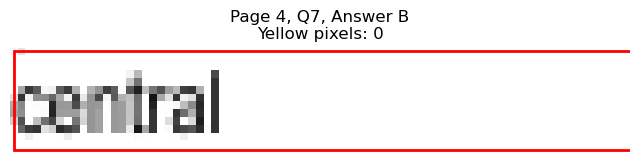

Page 4, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=97.8, y1=581.8
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 135
Page 4, Q7, C: Yellow percentage: 0.0%


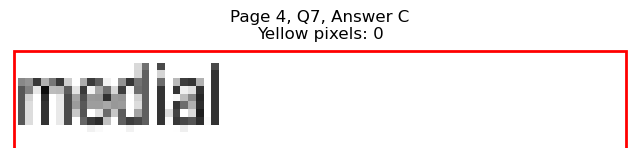

Page 4, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=360.8, y1=556.4
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 157
Page 4, Q7, D: Yellow percentage: 0.0%


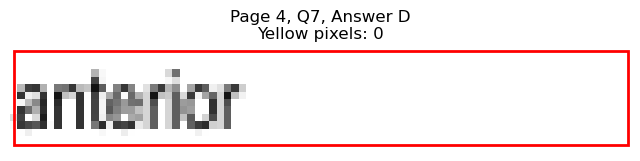

Page 4, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=350.7, y1=569.2
Page 4, Q7, E: Yellow pixels: 850
Page 4, Q7, E: Total non-white pixels: 1036
Page 4, Q7, E: Yellow percentage: 82.0%


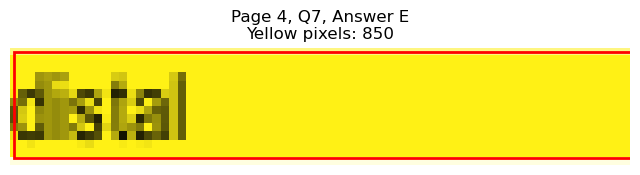


Page 4, Q7 - Selected Answer: E (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=100.5, y1=619.6
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 124
Page 4, Q8, A: Yellow percentage: 0.0%


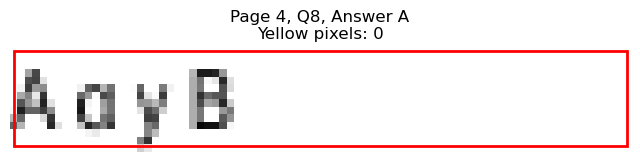

Page 4, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=100.5, y1=632.3
Page 4, Q8, B: Yellow pixels: 903
Page 4, Q8, B: Total non-white pixels: 1162
Page 4, Q8, B: Yellow percentage: 77.7%


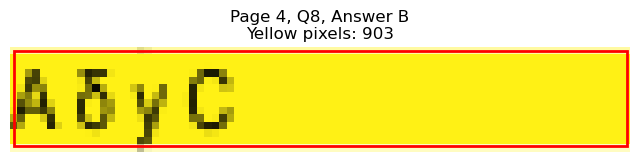

Page 4, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=100.9, y1=644.9
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 210
Page 4, Q8, C: Yellow percentage: 0.0%


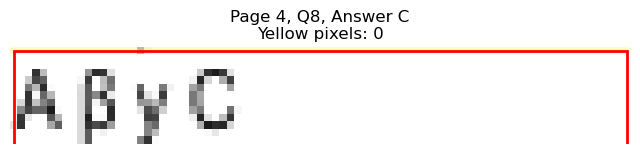

Page 4, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=352.1, y1=619.6
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 96
Page 4, Q8, D: Yellow percentage: 0.0%


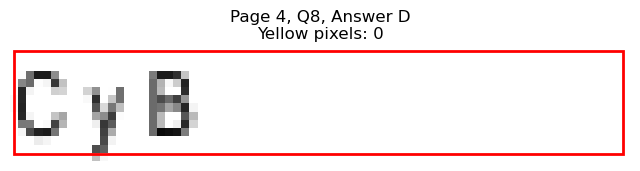

Page 4, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=358.6, y1=632.3
Page 4, Q8, E: Yellow pixels: 0
Page 4, Q8, E: Total non-white pixels: 117
Page 4, Q8, E: Yellow percentage: 0.0%


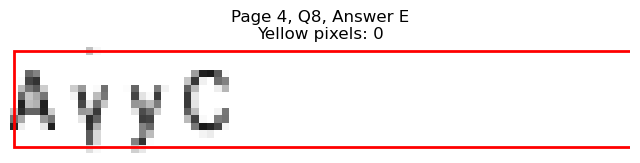


Page 4, Q8 - Selected Answer: B (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=670.1, x1=159.0, y1=682.7
Page 4, Q9, A: Yellow pixels: 0
Page 4, Q9, A: Total non-white pixels: 432
Page 4, Q9, A: Yellow percentage: 0.0%


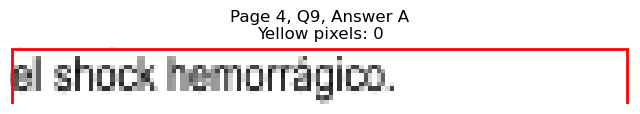

Page 4, Q9 - B: Detected box: x0=68.3, y0=682.7, x1=158.5, y1=695.3
Page 4, Q9, B: Yellow pixels: 0
Page 4, Q9, B: Total non-white pixels: 451
Page 4, Q9, B: Yellow percentage: 0.0%


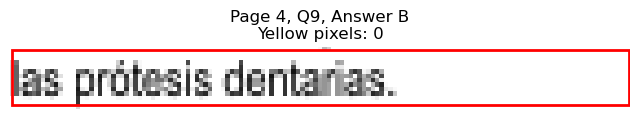

Page 4, Q9 - C: Detected box: x0=68.8, y0=695.4, x1=187.7, y1=708.0
Page 4, Q9, C: Yellow pixels: 0
Page 4, Q9, C: Total non-white pixels: 547
Page 4, Q9, C: Yellow percentage: 0.0%


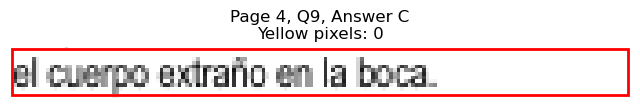

Page 4, Q9 - D: Detected box: x0=444.9, y0=670.1, x1=486.0, y1=682.7
Page 4, Q9, D: Yellow pixels: 854
Page 4, Q9, D: Total non-white pixels: 1209
Page 4, Q9, D: Yellow percentage: 70.6%


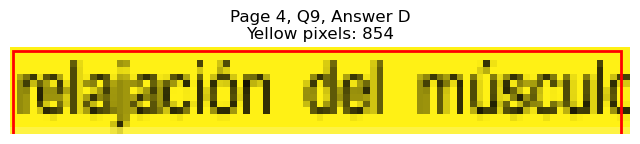

Page 4, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=444.9, y1=708.0
Page 4, Q9, E: Yellow pixels: 1
Page 4, Q9, E: Total non-white pixels: 753
Page 4, Q9, E: Yellow percentage: 0.1%


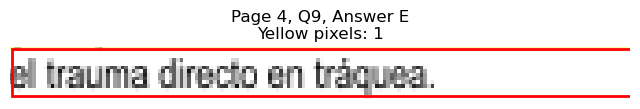


Page 4, Q9 - Selected Answer: D (based on yellow pixel count)




Page 4, Q10 - A: Detected box: x0=68.3, y0=733.2, x1=187.1, y1=745.8
Page 4, Q10, A: Yellow pixels: 0
Page 4, Q10, A: Total non-white pixels: 584
Page 4, Q10, A: Yellow percentage: 0.0%


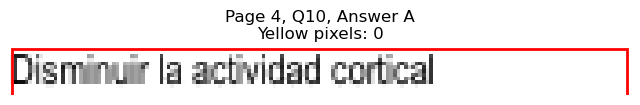

Page 4, Q10 - B: Detected box: x0=141.3, y0=745.8, x1=221.1, y1=758.4
Page 4, Q10, B: Yellow pixels: 0
Page 4, Q10, B: Total non-white pixels: 390
Page 4, Q10, B: Yellow percentage: 0.0%


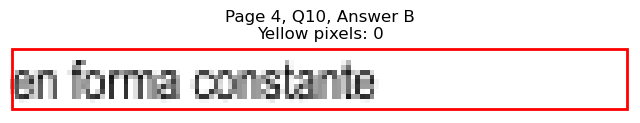

Page 4, Q10 - C: Detected box: x0=68.8, y0=758.5, x1=212.8, y1=771.2
Page 4, Q10, C: Yellow pixels: 0
Page 4, Q10, C: Total non-white pixels: 719
Page 4, Q10, C: Yellow percentage: 0.0%


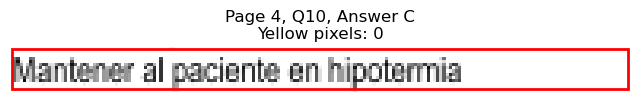

Page 4, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=498.1, y1=745.8
Page 4, Q10, D: Yellow pixels: 0
Page 4, Q10, D: Total non-white pixels: 1073
Page 4, Q10, D: Yellow percentage: 0.0%


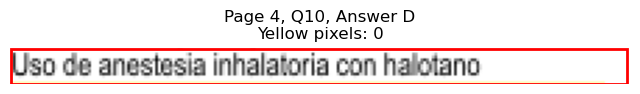

Page 4, Q10 - E: Detected box: x0=327.0, y0=745.8, x1=481.2, y1=758.4
Page 4, Q10, E: Yellow pixels: 2030
Page 4, Q10, E: Total non-white pixels: 2870
Page 4, Q10, E: Yellow percentage: 70.7%


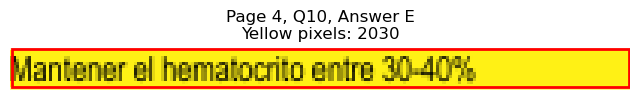


Page 4, Q10 - Selected Answer: E (based on yellow pixel count)





Page 5: Found 8 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=135.0, y1=102.1
Page 5, Q1, A: Yellow pixels: 118
Page 5, Q1, A: Total non-white pixels: 446
Page 5, Q1, A: Yellow percentage: 26.5%


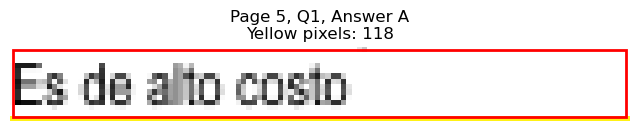

Page 5, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=278.4, y1=114.7
Page 5, Q1, B: Yellow pixels: 1899
Page 5, Q1, B: Total non-white pixels: 2798
Page 5, Q1, B: Yellow percentage: 67.9%


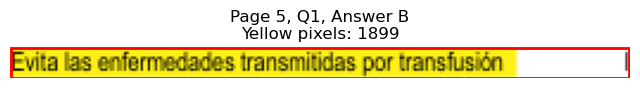

Page 5, Q1 - C: Detected box: x0=146.9, y0=114.6, x1=195.3, y1=127.3
Page 5, Q1, C: Yellow pixels: 100
Page 5, Q1, C: Total non-white pixels: 524
Page 5, Q1, C: Yellow percentage: 19.1%


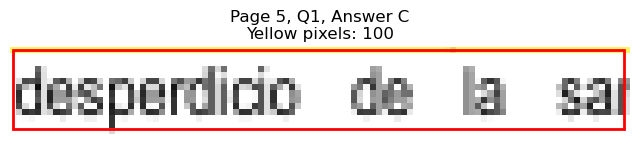

Page 5, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=541.0, y1=102.1
Page 5, Q1, D: Yellow pixels: 0
Page 5, Q1, D: Total non-white pixels: 1022
Page 5, Q1, D: Yellow percentage: 0.0%


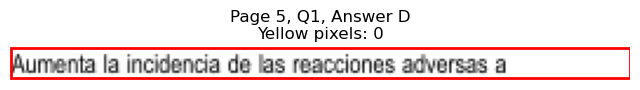

Page 5, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=521.3, y1=127.3
Page 5, Q1, E: Yellow pixels: 0
Page 5, Q1, E: Total non-white pixels: 956
Page 5, Q1, E: Yellow percentage: 0.0%


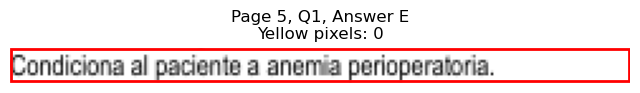


Page 5, Q1 - Selected Answer: B (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=190.5, x1=180.1, y1=203.1
Page 5, Q2, A: Yellow pixels: 163
Page 5, Q2, A: Total non-white pixels: 748
Page 5, Q2, A: Yellow percentage: 21.8%


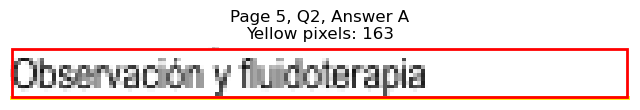

Page 5, Q2 - B: Detected box: x0=68.3, y0=203.1, x1=282.2, y1=215.7
Page 5, Q2, B: Yellow pixels: 2006
Page 5, Q2, B: Total non-white pixels: 2847
Page 5, Q2, B: Yellow percentage: 70.5%


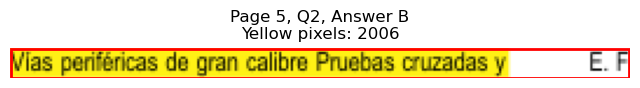

Page 5, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=176.1, y1=240.9
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 683
Page 5, Q2, C: Yellow percentage: 0.0%


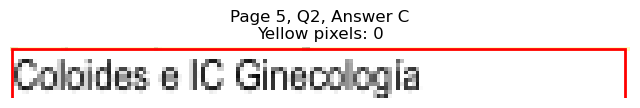

Page 5, Q2 - D: Detected box: x0=327.5, y0=190.5, x1=470.5, y1=203.1
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 724
Page 5, Q2, D: Yellow percentage: 0.0%


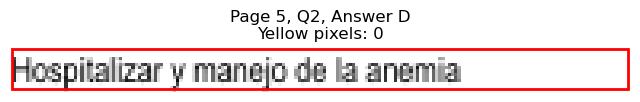

Page 5, Q2 - E: Detected box: x0=327.0, y0=203.1, x1=516.2, y1=215.7
Page 5, Q2, E: Yellow pixels: 0
Page 5, Q2, E: Total non-white pixels: 967
Page 5, Q2, E: Yellow percentage: 0.0%


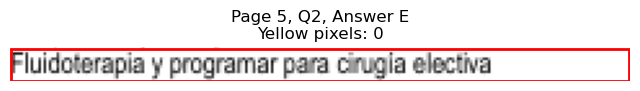


Page 5, Q2 - Selected Answer: B (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=266.2, x1=168.6, y1=278.8
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 649
Page 5, Q3, A: Yellow percentage: 0.0%


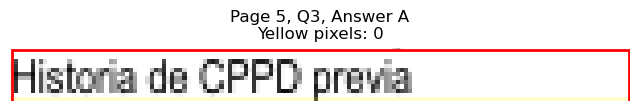

Page 5, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=106.6, y1=291.5
Page 5, Q3, B: Yellow pixels: 844
Page 5, Q3, B: Total non-white pixels: 1246
Page 5, Q3, B: Yellow percentage: 67.7%


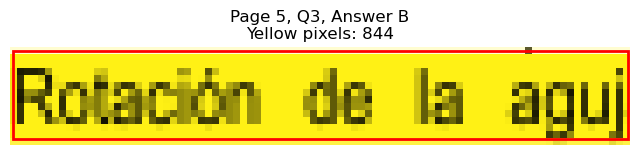

Page 5, Q3 - C: Detected box: x0=68.8, y0=304.0, x1=92.4, y1=316.7
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 196
Page 5, Q3, C: Yellow percentage: 0.0%


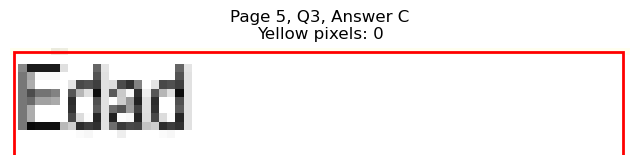

Page 5, Q3 - D: Detected box: x0=327.5, y0=266.2, x1=382.7, y1=278.8
Page 5, Q3, D: Yellow pixels: 0
Page 5, Q3, D: Total non-white pixels: 281
Page 5, Q3, D: Yellow percentage: 0.0%


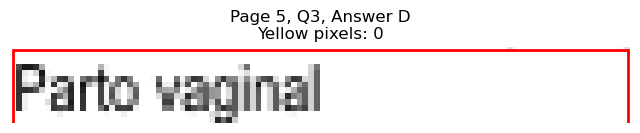

Page 5, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=370.7, y1=291.5
Page 5, Q3, E: Yellow pixels: 0
Page 5, Q3, E: Total non-white pixels: 214
Page 5, Q3, E: Yellow percentage: 0.0%


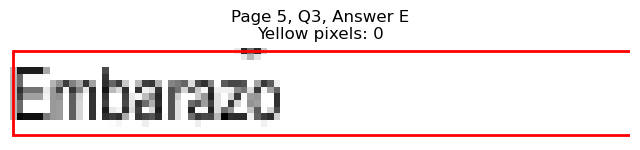


Page 5, Q3 - Selected Answer: B (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=367.1, x1=278.6, y1=379.8
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 1104
Page 5, Q4, A: Yellow percentage: 0.0%


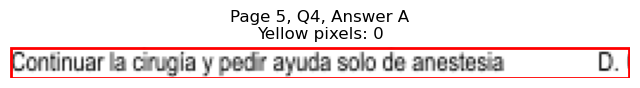

Page 5, Q4 - B: Detected box: x0=68.3, y0=379.7, x1=134.3, y1=392.4
Page 5, Q4, B: Yellow pixels: 0
Page 5, Q4, B: Total non-white pixels: 541
Page 5, Q4, B: Yellow percentage: 0.0%


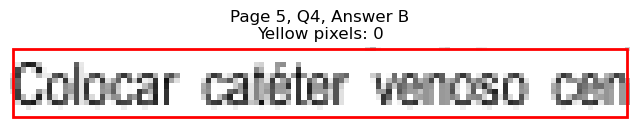

Page 5, Q4 - C: Detected box: x0=68.8, y0=405.0, x1=251.0, y1=417.7
Page 5, Q4, C: Yellow pixels: 0
Page 5, Q4, C: Total non-white pixels: 922
Page 5, Q4, C: Yellow percentage: 0.0%


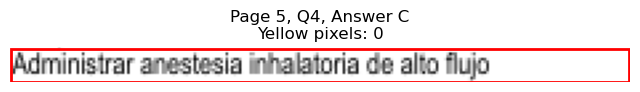

Page 5, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=541.2, y1=379.8
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 1002
Page 5, Q4, D: Yellow percentage: 0.0%


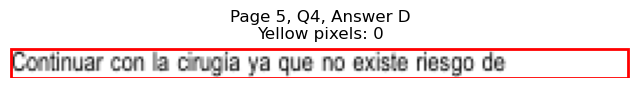

Page 5, Q4 - E: Detected box: x0=327.0, y0=392.3, x1=541.2, y1=405.0
Page 5, Q4, E: Yellow pixels: 1979
Page 5, Q4, E: Total non-white pixels: 2782
Page 5, Q4, E: Yellow percentage: 71.1%


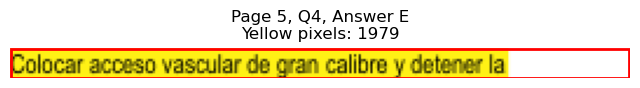


Page 5, Q4 - Selected Answer: E (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=455.5, x1=113.9, y1=468.1
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 208
Page 5, Q5, A: Yellow percentage: 0.0%


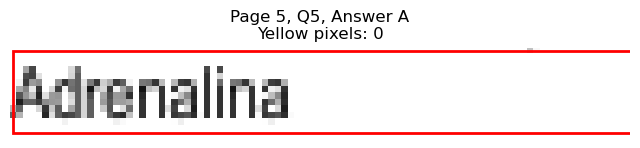

Page 5, Q5 - B: Detected box: x0=68.3, y0=468.2, x1=112.9, y1=480.8
Page 5, Q5, B: Yellow pixels: 1056
Page 5, Q5, B: Total non-white pixels: 1235
Page 5, Q5, B: Yellow percentage: 85.5%


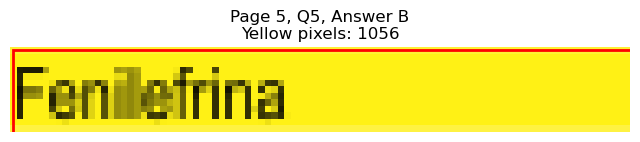

Page 5, Q5 - C: Detected box: x0=68.8, y0=480.8, x1=104.9, y1=493.4
Page 5, Q5, C: Yellow pixels: 87
Page 5, Q5, C: Total non-white pixels: 264
Page 5, Q5, C: Yellow percentage: 33.0%


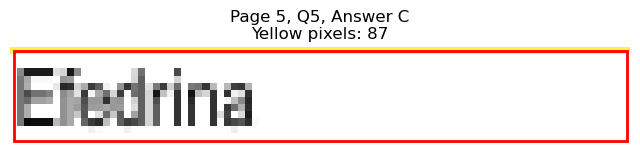

Page 5, Q5 - D: Detected box: x0=327.5, y0=455.5, x1=382.7, y1=468.1
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 296
Page 5, Q5, D: Yellow percentage: 0.0%


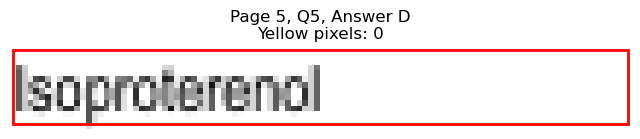

Page 5, Q5 - E: Detected box: x0=327.0, y0=468.2, x1=378.2, y1=480.8
Page 5, Q5, E: Yellow pixels: 0
Page 5, Q5, E: Total non-white pixels: 262
Page 5, Q5, E: Yellow percentage: 0.0%


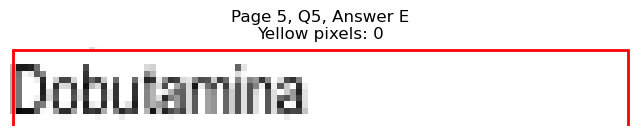


Page 5, Q5 - Selected Answer: B (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=282.4, y1=531.2
Page 5, Q6, A: Yellow pixels: 0
Page 5, Q6, A: Total non-white pixels: 1111
Page 5, Q6, A: Yellow percentage: 0.0%


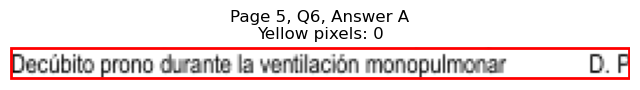

Page 5, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=184.5, y1=543.8
Page 5, Q6, B: Yellow pixels: 0
Page 5, Q6, B: Total non-white pixels: 689
Page 5, Q6, B: Yellow percentage: 0.0%


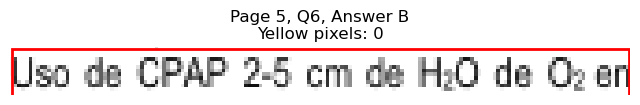

Page 5, Q6 - C: Detected box: x0=68.8, y0=556.5, x1=157.1, y1=569.2
Page 5, Q6, C: Yellow pixels: 1487
Page 5, Q6, C: Total non-white pixels: 1960
Page 5, Q6, C: Yellow percentage: 75.9%


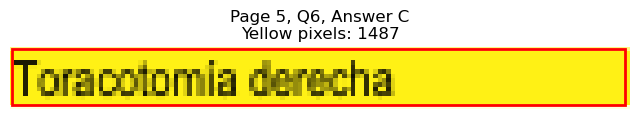

Page 5, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=458.5, y1=531.2
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 690
Page 5, Q6, D: Yellow percentage: 0.0%


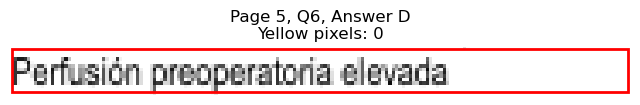

Page 5, Q6 - E: Detected box: x0=366.4, y0=531.2, x1=503.9, y1=543.8
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 690
Page 5, Q6, E: Yellow percentage: 0.0%


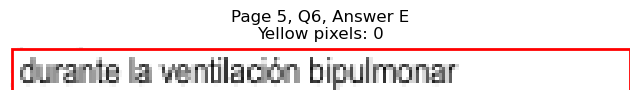


Page 5, Q6 - Selected Answer: C (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=594.3, x1=121.5, y1=607.0
Page 5, Q7, A: Yellow pixels: 1123
Page 5, Q7, A: Total non-white pixels: 1352
Page 5, Q7, A: Yellow percentage: 83.1%


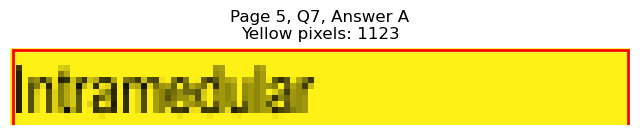

Page 5, Q7 - B: Detected box: x0=68.3, y0=607.0, x1=118.5, y1=619.7
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 366
Page 5, Q7, B: Yellow percentage: 0.0%


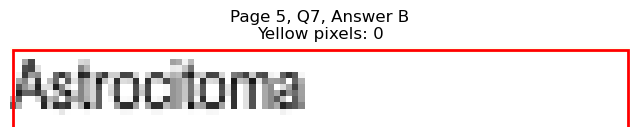

Page 5, Q7 - C: Detected box: x0=68.8, y0=619.6, x1=147.0, y1=632.3
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 449
Page 5, Q7, C: Yellow percentage: 0.0%


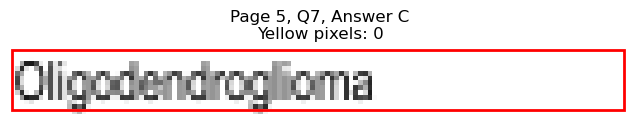

Page 5, Q7 - D: Detected box: x0=327.5, y0=594.3, x1=383.2, y1=607.0
Page 5, Q7, D: Yellow pixels: 0
Page 5, Q7, D: Total non-white pixels: 272
Page 5, Q7, D: Yellow percentage: 0.0%


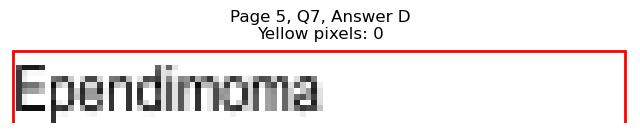

Page 5, Q7 - E: Detected box: x0=327.0, y0=607.0, x1=378.7, y1=619.7
Page 5, Q7, E: Yellow pixels: 0
Page 5, Q7, E: Total non-white pixels: 271
Page 5, Q7, E: Yellow percentage: 0.0%


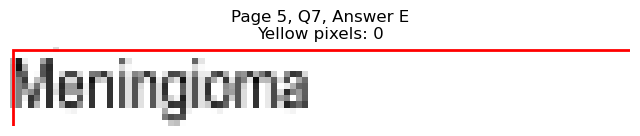


Page 5, Q7 - Selected Answer: A (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=682.8, x1=120.0, y1=695.4
Page 5, Q8, A: Yellow pixels: 0
Page 5, Q8, A: Total non-white pixels: 284
Page 5, Q8, A: Yellow percentage: 0.0%


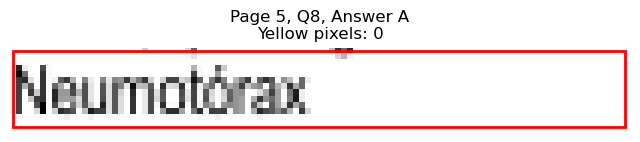

Page 5, Q8 - B: Detected box: x0=68.3, y0=695.4, x1=188.3, y1=708.0
Page 5, Q8, B: Yellow pixels: 0
Page 5, Q8, B: Total non-white pixels: 605
Page 5, Q8, B: Yellow percentage: 0.0%


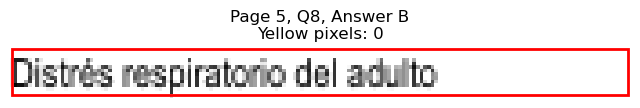

Page 5, Q8 - C: Detected box: x0=68.8, y0=708.0, x1=115.5, y1=720.6
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 239
Page 5, Q8, C: Yellow percentage: 0.0%


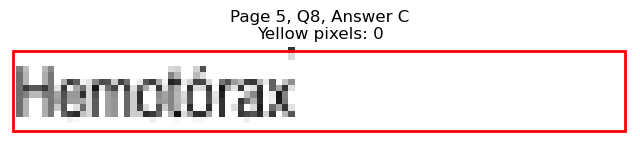

Page 5, Q8 - D: Detected box: x0=327.5, y0=682.8, x1=416.8, y1=695.4
Page 5, Q8, D: Yellow pixels: 1328
Page 5, Q8, D: Total non-white pixels: 1960
Page 5, Q8, D: Yellow percentage: 67.8%


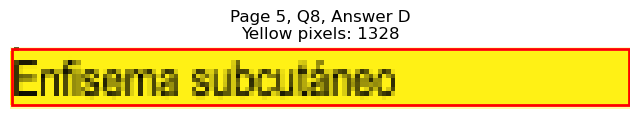

Page 5, Q8 - E: Detected box: x0=327.0, y0=695.4, x1=424.4, y1=708.0
Page 5, Q8, E: Yellow pixels: 0
Page 5, Q8, E: Total non-white pixels: 639
Page 5, Q8, E: Yellow percentage: 0.0%


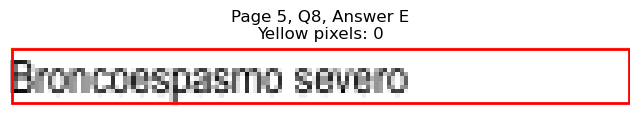


Page 5, Q8 - Selected Answer: D (based on yellow pixel count)





Page 6: Found 10 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=77.3, y1=102.1
Page 6, Q1, A: Yellow pixels: 60
Page 6, Q1, A: Total non-white pixels: 93
Page 6, Q1, A: Yellow percentage: 64.5%


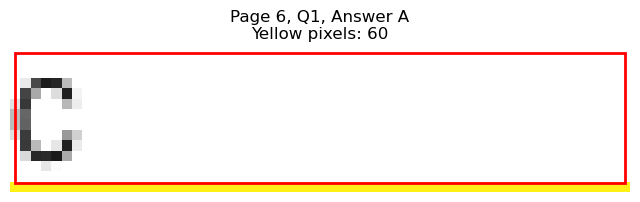

Page 6, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=98.9, y1=114.7
Page 6, Q1, B: Yellow pixels: 936
Page 6, Q1, B: Total non-white pixels: 1053
Page 6, Q1, B: Yellow percentage: 88.9%


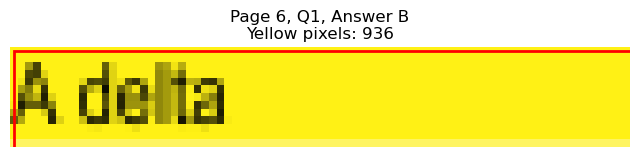

Page 6, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=97.3, y1=127.3
Page 6, Q1, C: Yellow pixels: 80
Page 6, Q1, C: Total non-white pixels: 210
Page 6, Q1, C: Yellow percentage: 38.1%


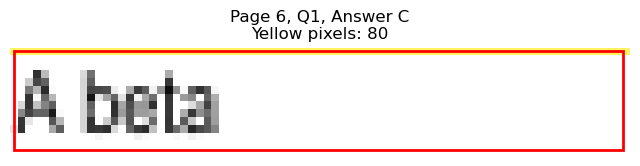

Page 6, Q1 - D: Detected box: x0=315.4, y0=89.4, x1=324.4, y1=102.1
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 77
Page 6, Q1, D: Yellow percentage: 0.0%


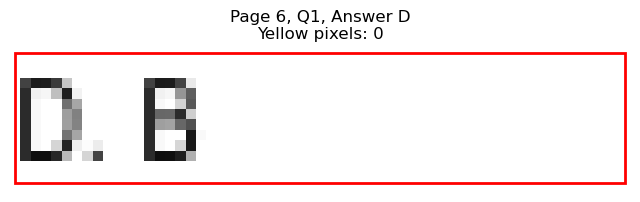

Page 6, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=368.2, y1=114.7
Page 6, Q1, E: Yellow pixels: 0
Page 6, Q1, E: Total non-white pixels: 190
Page 6, Q1, E: Yellow percentage: 0.0%


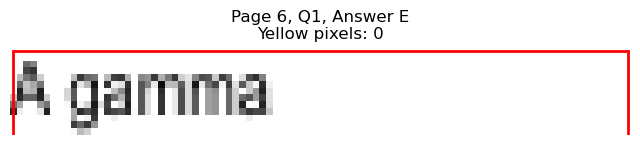


Page 6, Q1 - Selected Answer: B (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=83.4, y1=165.2
Page 6, Q2, A: Yellow pixels: 818
Page 6, Q2, A: Total non-white pixels: 924
Page 6, Q2, A: Yellow percentage: 88.5%


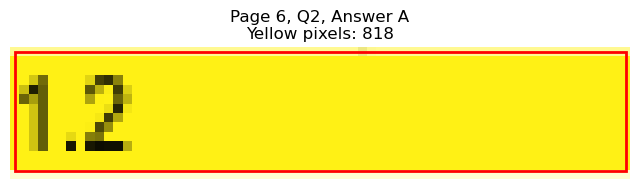

Page 6, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=83.4, y1=177.8
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 125
Page 6, Q2, B: Yellow percentage: 0.0%


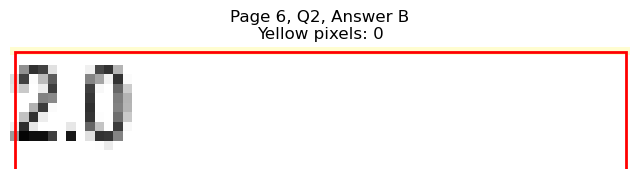

Page 6, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=88.8, y1=190.4
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 88
Page 6, Q2, C: Yellow percentage: 0.0%


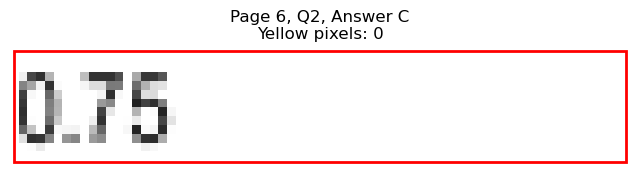

Page 6, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=347.6, y1=165.2
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 90
Page 6, Q2, D: Yellow percentage: 0.0%


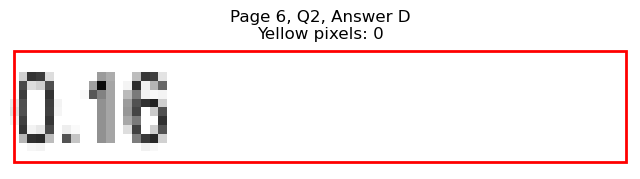

Page 6, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=342.2, y1=177.8
Page 6, Q2, E: Yellow pixels: 0
Page 6, Q2, E: Total non-white pixels: 44
Page 6, Q2, E: Yellow percentage: 0.0%


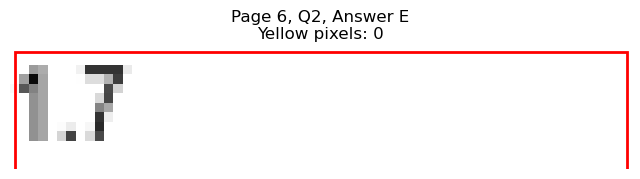


Page 6, Q2 - Selected Answer: A (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=56.6, y0=228.3, x1=65.2, y1=240.9
Page 6, Q3, A: Yellow pixels: 0
Page 6, Q3, A: Total non-white pixels: 133
Page 6, Q3, A: Yellow percentage: 0.0%


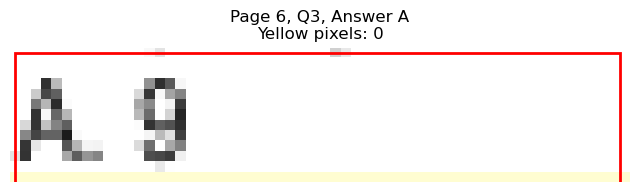

Page 6, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=80.9, y1=253.5
Page 6, Q3, B: Yellow pixels: 777
Page 6, Q3, B: Total non-white pixels: 882
Page 6, Q3, B: Yellow percentage: 88.1%


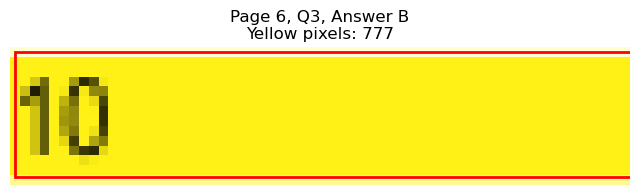

Page 6, Q3 - C: Detected box: x0=56.6, y0=253.5, x1=65.6, y1=266.1
Page 6, Q3, C: Yellow pixels: 60
Page 6, Q3, C: Total non-white pixels: 118
Page 6, Q3, C: Yellow percentage: 50.8%


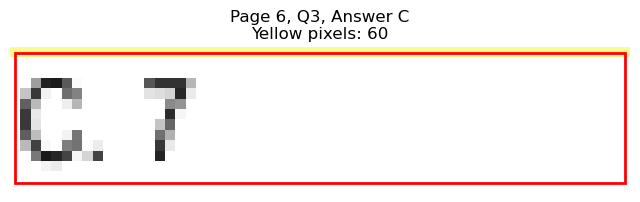

Page 6, Q3 - D: Detected box: x0=315.4, y0=228.3, x1=324.4, y1=240.9
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 81
Page 6, Q3, D: Yellow percentage: 0.0%


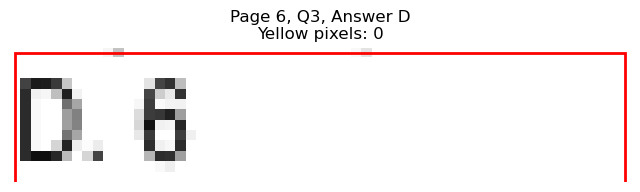

Page 6, Q3 - E: Detected box: x0=315.4, y0=240.9, x1=323.9, y1=253.5
Page 6, Q3, E: Yellow pixels: 0
Page 6, Q3, E: Total non-white pixels: 69
Page 6, Q3, E: Yellow percentage: 0.0%


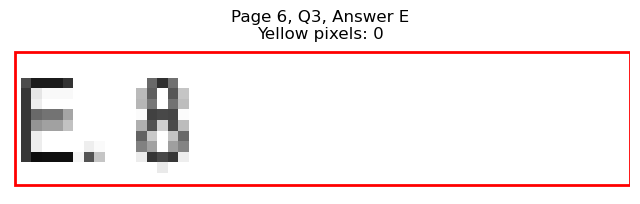


Page 6, Q3 - Selected Answer: B (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=105.9, y1=304.1
Page 6, Q4, A: Yellow pixels: 1015
Page 6, Q4, A: Total non-white pixels: 1232
Page 6, Q4, A: Yellow percentage: 82.4%


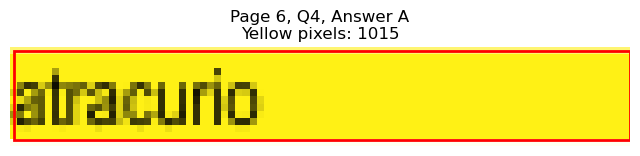

Page 6, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=124.0, y1=316.7
Page 6, Q4, B: Yellow pixels: 0
Page 6, Q4, B: Total non-white pixels: 384
Page 6, Q4, B: Yellow percentage: 0.0%


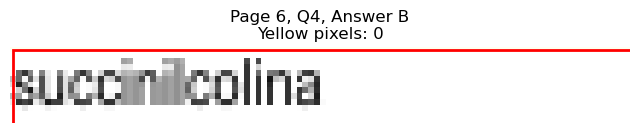

Page 6, Q4 - C: Detected box: x0=68.8, y0=316.6, x1=108.9, y1=329.3
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 173
Page 6, Q4, C: Yellow percentage: 0.0%


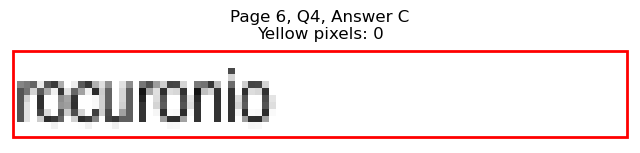

Page 6, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=374.7, y1=304.1
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 218
Page 6, Q4, D: Yellow percentage: 0.0%


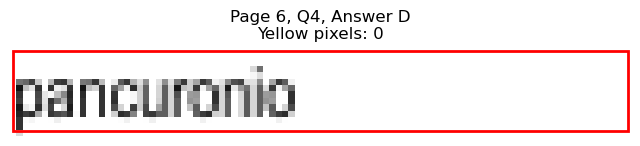

Page 6, Q4 - E: Detected box: x0=327.0, y0=304.0, x1=387.8, y1=316.7
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 309
Page 6, Q4, E: Yellow percentage: 0.0%


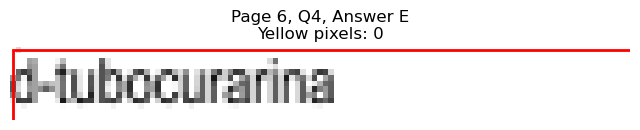


Page 6, Q4 - Selected Answer: A (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=143.1, y1=367.2
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 400
Page 6, Q5, A: Yellow percentage: 0.0%


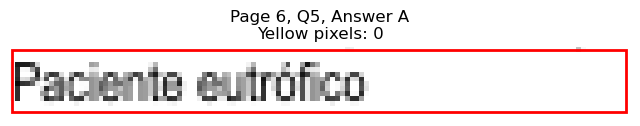

Page 6, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=169.2, y1=379.8
Page 6, Q5, B: Yellow pixels: 4
Page 6, Q5, B: Total non-white pixels: 656
Page 6, Q5, B: Yellow percentage: 0.6%


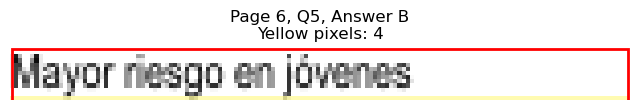

Page 6, Q5 - C: Detected box: x0=68.8, y0=379.7, x1=243.8, y1=392.4
Page 6, Q5, C: Yellow pixels: 1884
Page 6, Q5, C: Total non-white pixels: 2996
Page 6, Q5, C: Yellow percentage: 62.9%


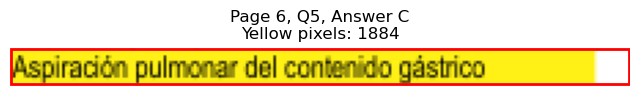

Page 6, Q5 - D: Detected box: x0=327.5, y0=354.5, x1=492.1, y1=367.2
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 793
Page 6, Q5, D: Yellow percentage: 0.0%


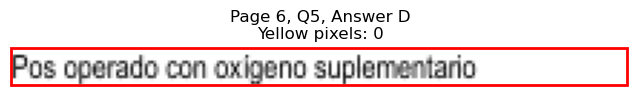

Page 6, Q5 - E: Detected box: x0=327.0, y0=367.1, x1=345.6, y1=379.8
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 296
Page 6, Q5, E: Yellow percentage: 0.0%


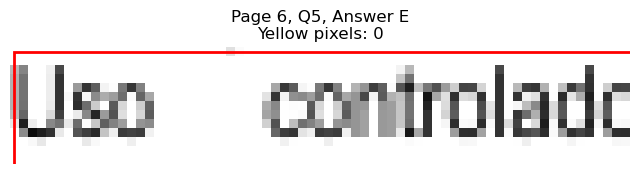


Page 6, Q5 - Selected Answer: C (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=109.5, y1=455.5
Page 6, Q6, A: Yellow pixels: 92
Page 6, Q6, A: Total non-white pixels: 316
Page 6, Q6, A: Yellow percentage: 29.1%


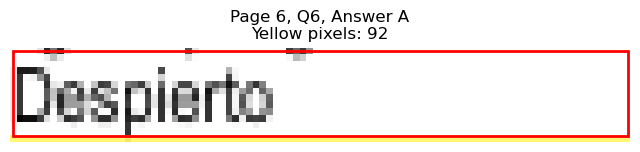

Page 6, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=146.5, y1=468.1
Page 6, Q6, B: Yellow pixels: 1353
Page 6, Q6, B: Total non-white pixels: 1806
Page 6, Q6, B: Yellow percentage: 74.9%


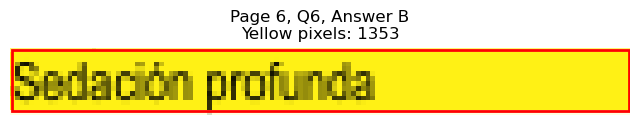

Page 6, Q6 - C: Detected box: x0=68.8, y0=468.1, x1=146.1, y1=480.7
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 499
Page 6, Q6, C: Yellow percentage: 0.0%


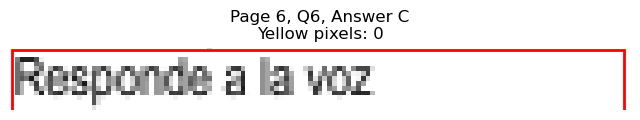

Page 6, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=404.8, y1=455.5
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 377
Page 6, Q6, D: Yellow percentage: 0.0%


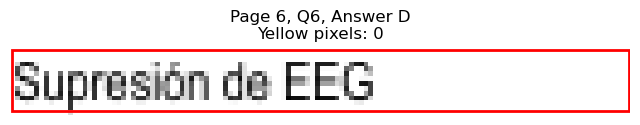

Page 6, Q6 - E: Detected box: x0=327.0, y0=455.5, x1=420.9, y1=468.1
Page 6, Q6, E: Yellow pixels: 0
Page 6, Q6, E: Total non-white pixels: 507
Page 6, Q6, E: Yellow percentage: 0.0%


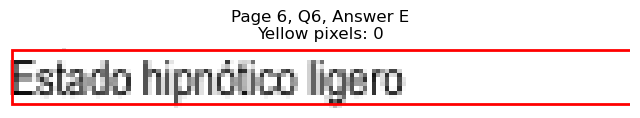


Page 6, Q6 - Selected Answer: B (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=506.0, x1=237.9, y1=518.6
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 874
Page 6, Q7, A: Yellow percentage: 0.0%


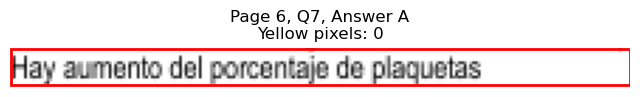

Page 6, Q7 - B: Detected box: x0=68.3, y0=518.6, x1=251.3, y1=531.2
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 911
Page 6, Q7, B: Yellow percentage: 0.0%


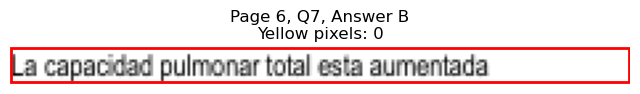

Page 6, Q7 - C: Detected box: x0=68.8, y0=531.2, x1=260.9, y1=543.8
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 969
Page 6, Q7, C: Yellow percentage: 0.0%


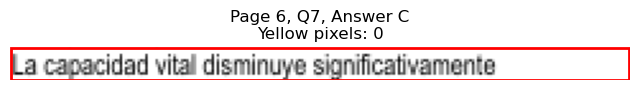

Page 6, Q7 - D: Detected box: x0=327.5, y0=506.0, x1=538.2, y1=518.6
Page 6, Q7, D: Yellow pixels: 1953
Page 6, Q7, D: Total non-white pixels: 2995
Page 6, Q7, D: Yellow percentage: 65.2%


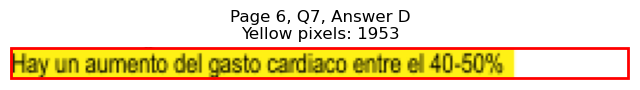

Page 6, Q7 - E: Detected box: x0=327.0, y0=518.6, x1=463.3, y1=531.2
Page 6, Q7, E: Yellow pixels: 186
Page 6, Q7, E: Total non-white pixels: 858
Page 6, Q7, E: Yellow percentage: 21.7%


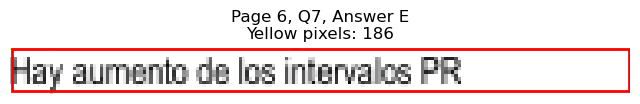


Page 6, Q7 - Selected Answer: D (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=581.7, x1=112.0, y1=594.4
Page 6, Q8, A: Yellow pixels: 94
Page 6, Q8, A: Total non-white pixels: 335
Page 6, Q8, A: Yellow percentage: 28.1%


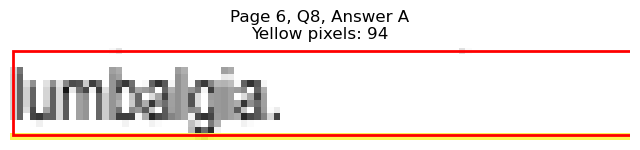

Page 6, Q8 - B: Detected box: x0=68.3, y0=594.3, x1=205.2, y1=607.0
Page 6, Q8, B: Yellow pixels: 1906
Page 6, Q8, B: Total non-white pixels: 2444
Page 6, Q8, B: Yellow percentage: 78.0%


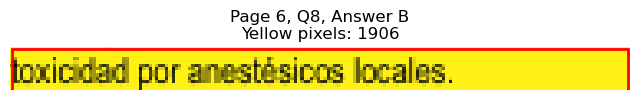

Page 6, Q8 - C: Detected box: x0=68.8, y0=606.9, x1=118.9, y1=619.6
Page 6, Q8, C: Yellow pixels: 100
Page 6, Q8, C: Total non-white pixels: 358
Page 6, Q8, C: Yellow percentage: 27.9%


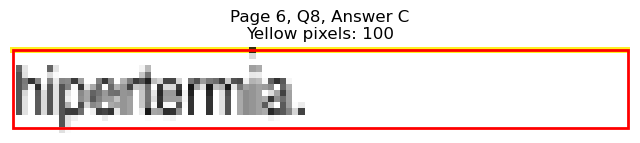

Page 6, Q8 - D: Detected box: x0=327.5, y0=581.7, x1=362.1, y1=594.4
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 184
Page 6, Q8, D: Yellow percentage: 0.0%


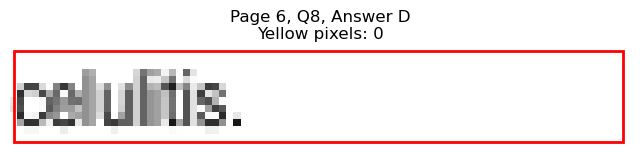

Page 6, Q8 - E: Detected box: x0=327.0, y0=594.3, x1=400.7, y1=607.0
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 363
Page 6, Q8, E: Yellow percentage: 0.0%


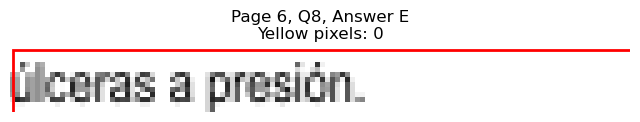


Page 6, Q8 - Selected Answer: B (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=644.9, x1=80.9, y1=657.5
Page 6, Q9, A: Yellow pixels: 0
Page 6, Q9, A: Total non-white pixels: 41
Page 6, Q9, A: Yellow percentage: 0.0%


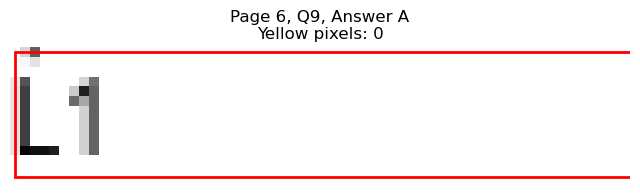

Page 6, Q9 - B: Detected box: x0=68.3, y0=657.5, x1=80.9, y1=670.1
Page 6, Q9, B: Yellow pixels: 63
Page 6, Q9, B: Total non-white pixels: 114
Page 6, Q9, B: Yellow percentage: 55.3%


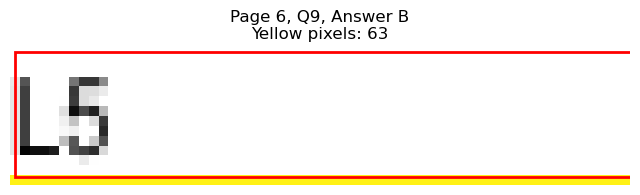

Page 6, Q9 - C: Detected box: x0=68.8, y0=670.1, x1=81.4, y1=682.7
Page 6, Q9, C: Yellow pixels: 791
Page 6, Q9, C: Total non-white pixels: 832
Page 6, Q9, C: Yellow percentage: 95.1%


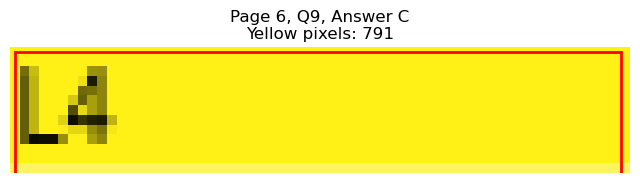

Page 6, Q9 - D: Detected box: x0=327.5, y0=644.9, x1=341.1, y1=657.5
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 48
Page 6, Q9, D: Yellow percentage: 0.0%


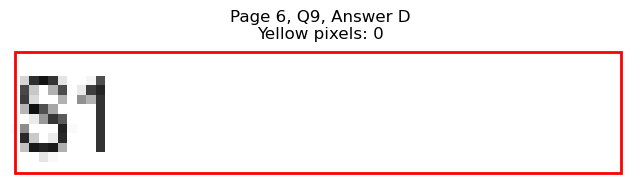

Page 6, Q9 - E: Detected box: x0=327.0, y0=657.5, x1=340.6, y1=670.1
Page 6, Q9, E: Yellow pixels: 0
Page 6, Q9, E: Total non-white pixels: 61
Page 6, Q9, E: Yellow percentage: 0.0%


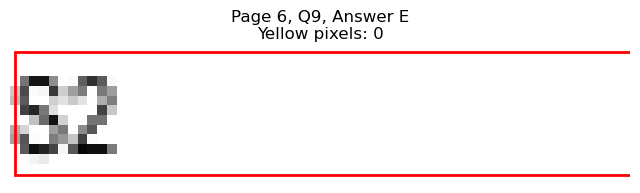


Page 6, Q9 - Selected Answer: C (based on yellow pixel count)




Page 6, Q10 - A: Detected box: x0=68.3, y0=708.0, x1=271.0, y1=720.6
Page 6, Q10, A: Yellow pixels: 76
Page 6, Q10, A: Total non-white pixels: 1114
Page 6, Q10, A: Yellow percentage: 6.8%


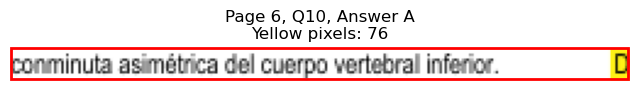

Page 6, Q10 - B: Detected box: x0=68.3, y0=720.6, x1=170.1, y1=733.2
Page 6, Q10, B: Yellow pixels: 0
Page 6, Q10, B: Total non-white pixels: 465
Page 6, Q10, B: Yellow percentage: 0.0%


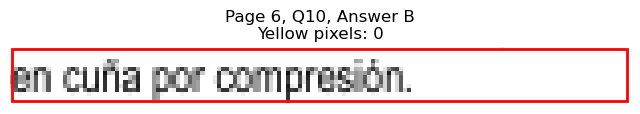

Page 6, Q10 - C: Detected box: x0=68.8, y0=733.2, x1=130.5, y1=745.8
Page 6, Q10, C: Yellow pixels: 0
Page 6, Q10, C: Total non-white pixels: 304
Page 6, Q10, C: Yellow percentage: 0.0%


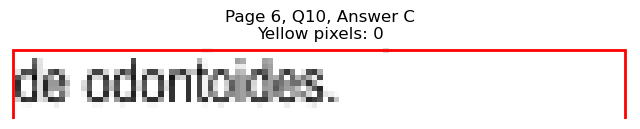

Page 6, Q10 - D: Detected box: x0=327.5, y0=708.0, x1=472.5, y1=720.6
Page 6, Q10, D: Yellow pixels: 1979
Page 6, Q10, D: Total non-white pixels: 2744
Page 6, Q10, D: Yellow percentage: 72.1%


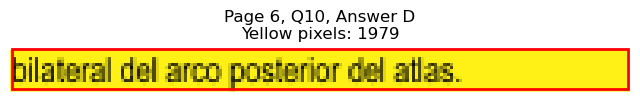

Page 6, Q10 - E: Detected box: x0=327.0, y0=720.6, x1=406.9, y1=733.2
Page 6, Q10, E: Yellow pixels: 130
Page 6, Q10, E: Total non-white pixels: 556
Page 6, Q10, E: Yellow percentage: 23.4%


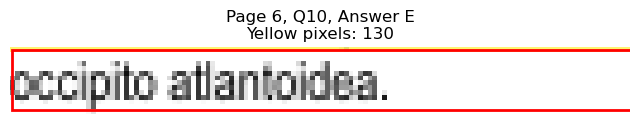


Page 6, Q10 - Selected Answer: D (based on yellow pixel count)





Page 7: Found 9 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=443.6, y1=114.7
Page 7, Q1, A: Yellow pixels: 4110
Page 7, Q1, A: Total non-white pixels: 5538
Page 7, Q1, A: Yellow percentage: 74.2%


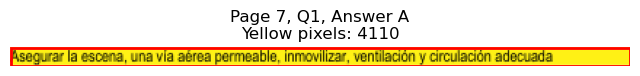

Page 7, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=289.6, y1=127.3
Page 7, Q1, B: Yellow pixels: 271
Page 7, Q1, B: Total non-white pixels: 1355
Page 7, Q1, B: Yellow percentage: 20.0%


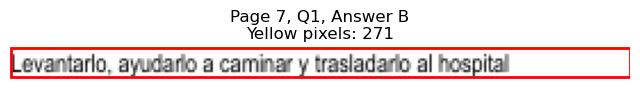

Page 7, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=352.6, y1=139.9
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 1362
Page 7, Q1, C: Yellow percentage: 0.0%


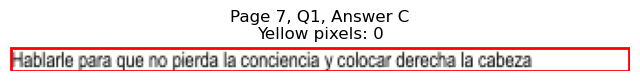

Page 7, Q1 - D: Detected box: x0=68.8, y0=139.9, x1=362.8, y1=152.6
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 1397
Page 7, Q1, D: Yellow percentage: 0.0%


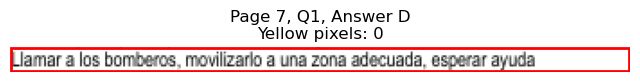

Page 7, Q1 - E: Detected box: x0=68.3, y0=152.5, x1=427.0, y1=165.2
Page 7, Q1, E: Yellow pixels: 0
Page 7, Q1, E: Total non-white pixels: 1725
Page 7, Q1, E: Yellow percentage: 0.0%


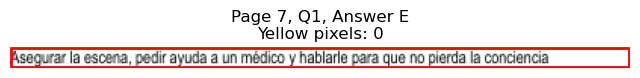


Page 7, Q1 - Selected Answer: A (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=96.4, y1=203.0
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 125
Page 7, Q2, A: Yellow percentage: 0.0%


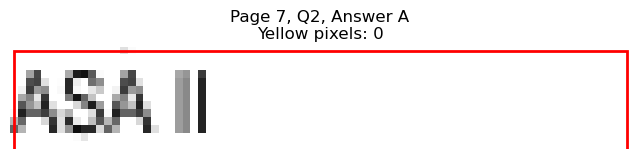

Page 7, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=105.1, y1=215.6
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 170
Page 7, Q2, B: Yellow percentage: 0.0%


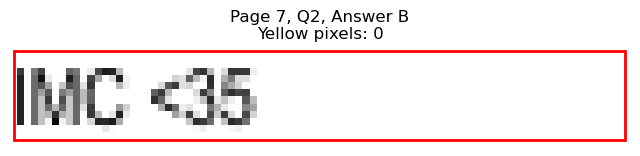

Page 7, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=114.1, y1=228.3
Page 7, Q2, C: Yellow pixels: 0
Page 7, Q2, C: Total non-white pixels: 225
Page 7, Q2, C: Yellow percentage: 0.0%


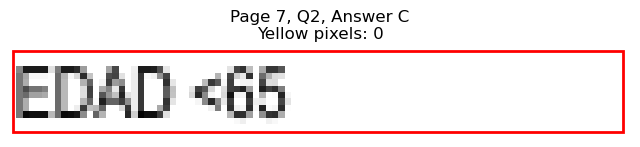

Page 7, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=422.8, y1=203.0
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 628
Page 7, Q2, D: Yellow percentage: 0.0%


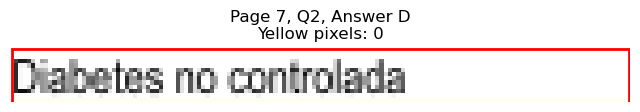

Page 7, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=357.7, y1=215.6
Page 7, Q2, E: Yellow pixels: 927
Page 7, Q2, E: Total non-white pixels: 1134
Page 7, Q2, E: Yellow percentage: 81.7%


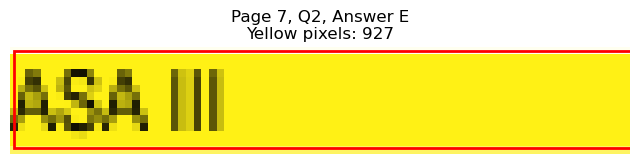


Page 7, Q2 - Selected Answer: E (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=106.9, y1=278.7
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 181
Page 7, Q3, A: Yellow percentage: 0.0%


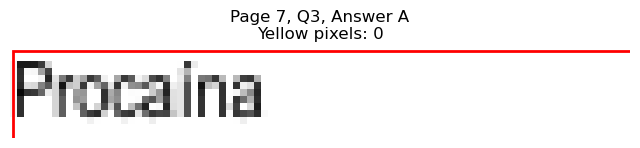

Page 7, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=120.5, y1=291.5
Page 7, Q3, B: Yellow pixels: 103
Page 7, Q3, B: Total non-white pixels: 380
Page 7, Q3, B: Yellow percentage: 27.1%


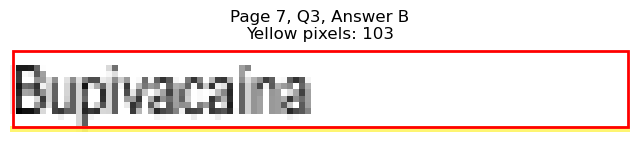

Page 7, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=110.4, y1=304.1
Page 7, Q3, C: Yellow pixels: 1047
Page 7, Q3, C: Total non-white pixels: 1302
Page 7, Q3, C: Yellow percentage: 80.4%


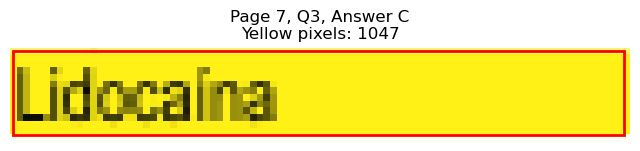

Page 7, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=386.7, y1=278.7
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 307
Page 7, Q3, D: Yellow percentage: 0.0%


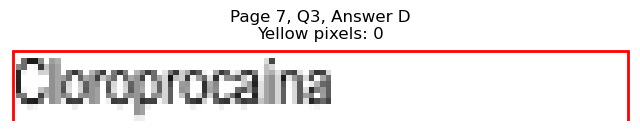

Page 7, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=379.7, y1=291.5
Page 7, Q3, E: Yellow pixels: 0
Page 7, Q3, E: Total non-white pixels: 271
Page 7, Q3, E: Yellow percentage: 0.0%


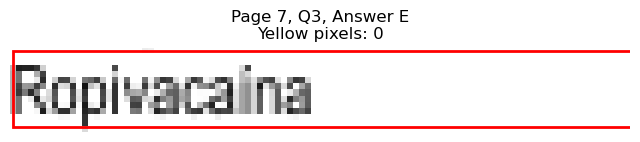


Page 7, Q3 - Selected Answer: C (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=153.0, y1=367.2
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 433
Page 7, Q4, A: Yellow percentage: 0.0%


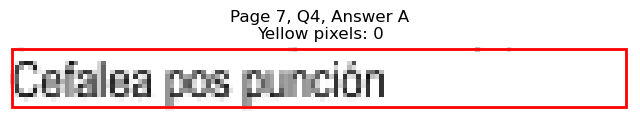

Page 7, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=123.5, y1=379.8
Page 7, Q4, B: Yellow pixels: 0
Page 7, Q4, B: Total non-white pixels: 379
Page 7, Q4, B: Yellow percentage: 0.0%


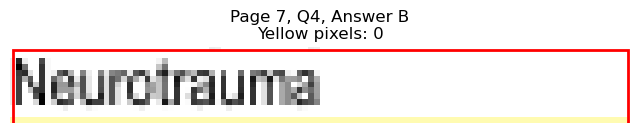

Page 7, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=118.0, y1=392.4
Page 7, Q4, C: Yellow pixels: 998
Page 7, Q4, C: Total non-white pixels: 1400
Page 7, Q4, C: Yellow percentage: 71.3%


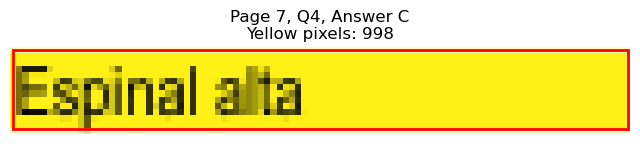

Page 7, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=452.0, y1=367.2
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 622
Page 7, Q4, D: Yellow percentage: 0.0%


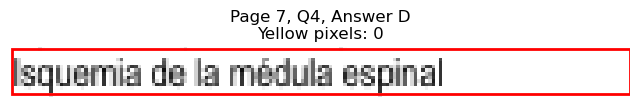

Page 7, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=376.7, y1=379.8
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 273
Page 7, Q4, E: Yellow percentage: 0.0%


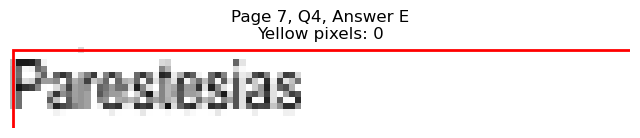


Page 7, Q4 - Selected Answer: C (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=109.6, y1=442.9
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 314
Page 7, Q5, A: Yellow percentage: 0.0%


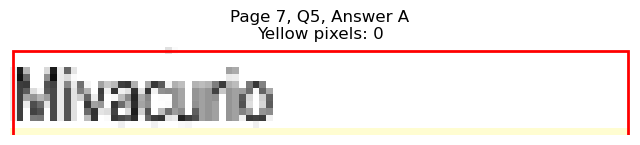

Page 7, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=112.0, y1=455.5
Page 7, Q5, B: Yellow pixels: 1080
Page 7, Q5, B: Total non-white pixels: 1316
Page 7, Q5, B: Yellow percentage: 82.1%


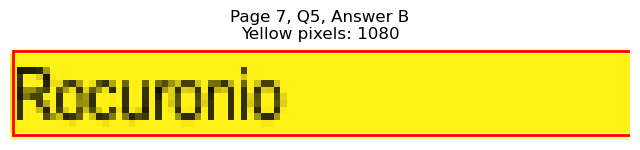

Page 7, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=116.9, y1=468.1
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 213
Page 7, Q5, C: Yellow percentage: 0.0%


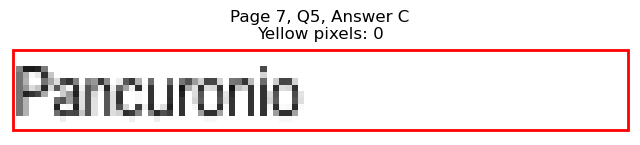

Page 7, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=390.3, y1=442.9
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 316
Page 7, Q5, D: Yellow percentage: 0.0%


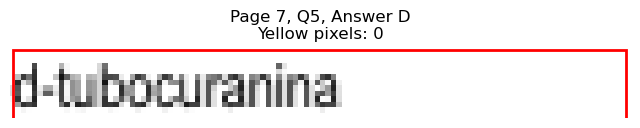

Page 7, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=373.7, y1=455.5
Page 7, Q5, E: Yellow pixels: 0
Page 7, Q5, E: Total non-white pixels: 235
Page 7, Q5, E: Yellow percentage: 0.0%


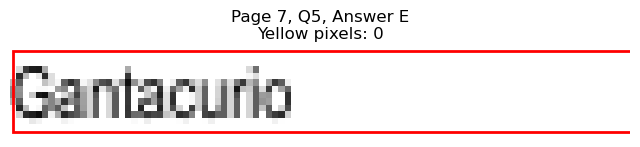


Page 7, Q5 - Selected Answer: B (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=131.1, y1=506.0
Page 7, Q6, A: Yellow pixels: 114
Page 7, Q6, A: Total non-white pixels: 543
Page 7, Q6, A: Yellow percentage: 21.0%


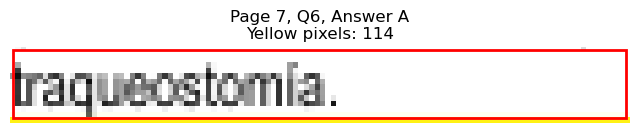

Page 7, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=156.0, y1=518.6
Page 7, Q6, B: Yellow pixels: 1448
Page 7, Q6, B: Total non-white pixels: 1946
Page 7, Q6, B: Yellow percentage: 74.4%


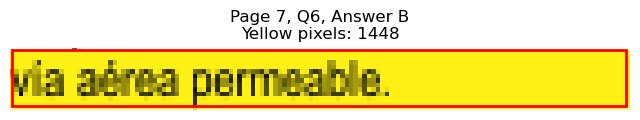

Page 7, Q6 - C: Detected box: x0=68.8, y0=518.6, x1=173.7, y1=531.2
Page 7, Q6, C: Yellow pixels: 156
Page 7, Q6, C: Total non-white pixels: 681
Page 7, Q6, C: Yellow percentage: 22.9%


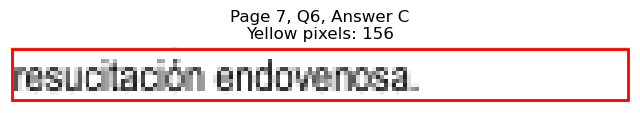

Page 7, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=472.1, y1=506.0
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 700
Page 7, Q6, D: Yellow percentage: 0.0%


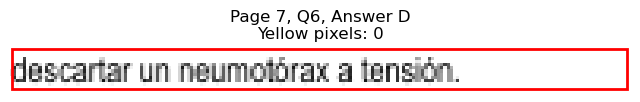

Page 7, Q6 - E: Detected box: x0=327.0, y0=506.0, x1=417.9, y1=518.6
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 464
Page 7, Q6, E: Yellow percentage: 0.0%


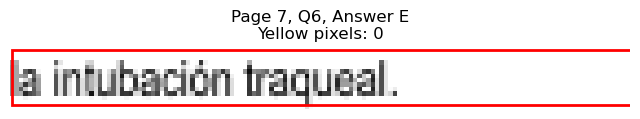


Page 7, Q6 - Selected Answer: B (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=112.0, y1=569.2
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 229
Page 7, Q7, A: Yellow percentage: 0.0%


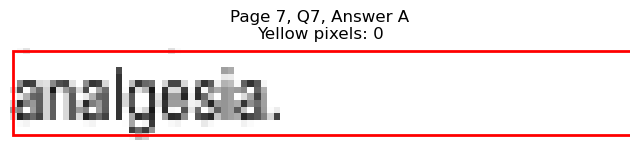

Page 7, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=113.4, y1=581.8
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 330
Page 7, Q7, B: Yellow percentage: 0.0%


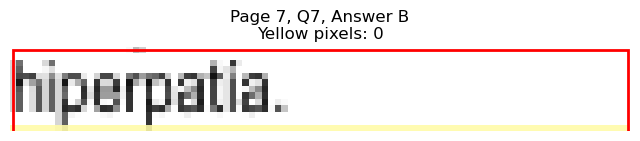

Page 7, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=104.9, y1=594.4
Page 7, Q7, C: Yellow pixels: 892
Page 7, Q7, C: Total non-white pixels: 1218
Page 7, Q7, C: Yellow percentage: 73.2%


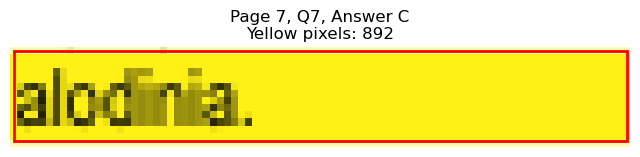

Page 7, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=378.2, y1=569.2
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 253
Page 7, Q7, D: Yellow percentage: 0.0%


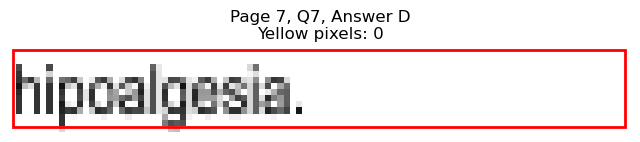

Page 7, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=369.2, y1=581.8
Page 7, Q7, E: Yellow pixels: 0
Page 7, Q7, E: Total non-white pixels: 224
Page 7, Q7, E: Yellow percentage: 0.0%


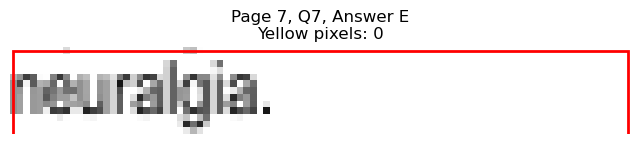


Page 7, Q7 - Selected Answer: C (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=336.2, y1=632.3
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 1315
Page 7, Q8, A: Yellow percentage: 0.0%


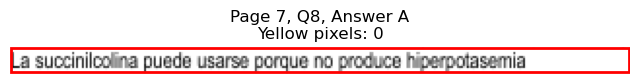

Page 7, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=466.2, y1=644.9
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 1941
Page 7, Q8, B: Yellow percentage: 0.0%


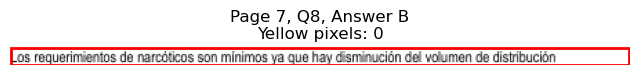

Page 7, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=341.6, y1=657.5
Page 7, Q8, C: Yellow pixels: 0
Page 7, Q8, C: Total non-white pixels: 1313
Page 7, Q8, C: Yellow percentage: 0.0%


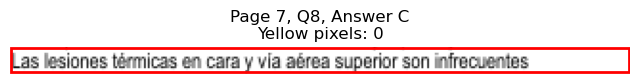

Page 7, Q8 - D: Detected box: x0=68.8, y0=657.5, x1=300.0, y1=670.1
Page 7, Q8, D: Yellow pixels: 283
Page 7, Q8, D: Total non-white pixels: 1407
Page 7, Q8, D: Yellow percentage: 20.1%


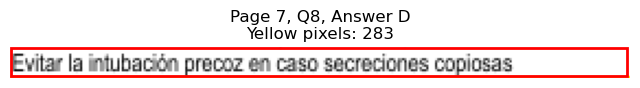

Page 7, Q8 - E: Detected box: x0=68.3, y0=670.1, x1=268.4, y1=682.7
Page 7, Q8, E: Yellow pixels: 2432
Page 7, Q8, E: Total non-white pixels: 3263
Page 7, Q8, E: Yellow percentage: 74.5%


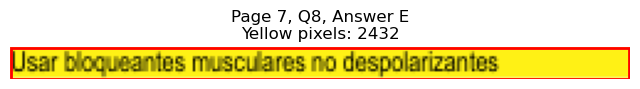


Page 7, Q8 - Selected Answer: E (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=76.8, y1=733.2
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 35
Page 7, Q9, A: Yellow percentage: 0.0%


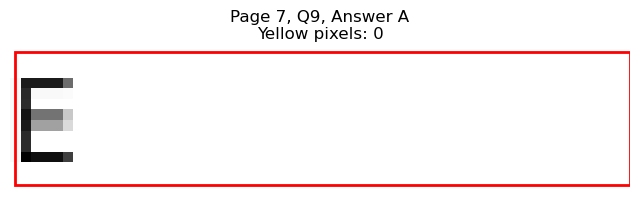

Page 7, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=77.3, y1=745.8
Page 7, Q9, B: Yellow pixels: 0
Page 7, Q9, B: Total non-white pixels: 33
Page 7, Q9, B: Yellow percentage: 0.0%


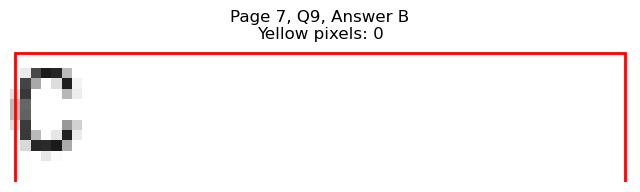

Page 7, Q9 - C: Detected box: x0=56.6, y0=745.8, x1=65.6, y1=758.4
Page 7, Q9, C: Yellow pixels: 0
Page 7, Q9, C: Total non-white pixels: 68
Page 7, Q9, C: Yellow percentage: 0.0%


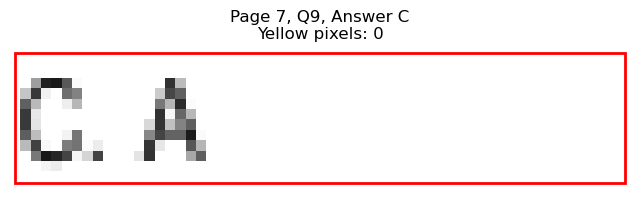

Page 7, Q9 - D: Detected box: x0=315.4, y0=720.6, x1=324.4, y1=733.2
Page 7, Q9, D: Yellow pixels: 60
Page 7, Q9, D: Total non-white pixels: 139
Page 7, Q9, D: Yellow percentage: 43.2%


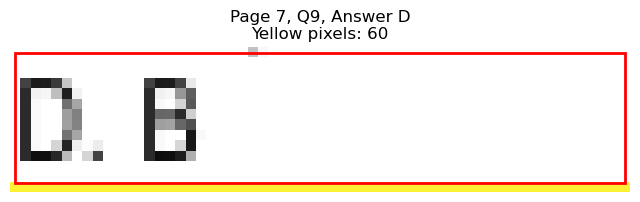

Page 7, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=336.1, y1=745.8
Page 7, Q9, E: Yellow pixels: 750
Page 7, Q9, E: Total non-white pixels: 780
Page 7, Q9, E: Yellow percentage: 96.2%


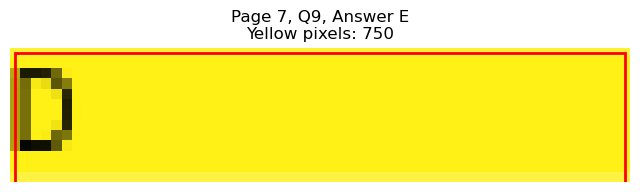


Page 7, Q9 - Selected Answer: E (based on yellow pixel count)





Page 8: Found 9 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=210.8, y1=114.7
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 710
Page 8, Q1, A: Yellow percentage: 0.0%


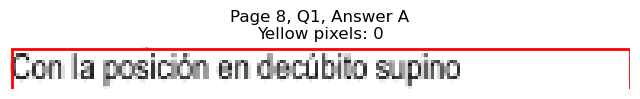

Page 8, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=234.0, y1=127.3
Page 8, Q1, B: Yellow pixels: 213
Page 8, Q1, B: Total non-white pixels: 1052
Page 8, Q1, B: Yellow percentage: 20.2%


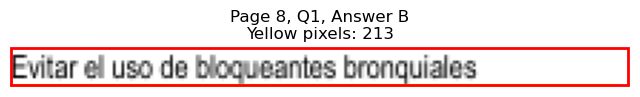

Page 8, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=212.3, y1=139.9
Page 8, Q1, C: Yellow pixels: 1985
Page 8, Q1, C: Total non-white pixels: 2535
Page 8, Q1, C: Yellow percentage: 78.3%


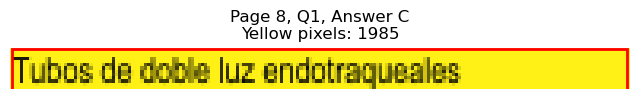

Page 8, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=541.2, y1=114.7
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 1048
Page 8, Q1, D: Yellow percentage: 0.0%


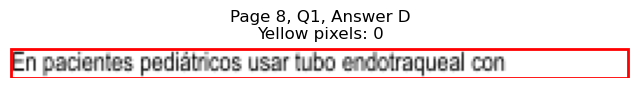

Page 8, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=499.1, y1=139.9
Page 8, Q1, E: Yellow pixels: 0
Page 8, Q1, E: Total non-white pixels: 823
Page 8, Q1, E: Yellow percentage: 0.0%


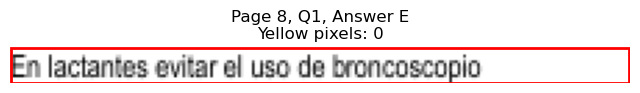


Page 8, Q1 - Selected Answer: C (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=106.9, y1=177.8
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 193
Page 8, Q2, A: Yellow percentage: 0.0%


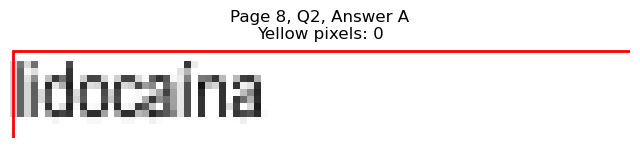

Page 8, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=112.5, y1=190.4
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 232
Page 8, Q2, B: Yellow percentage: 0.0%


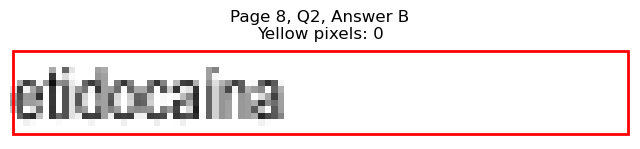

Page 8, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=120.0, y1=203.0
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 258
Page 8, Q2, C: Yellow percentage: 0.0%


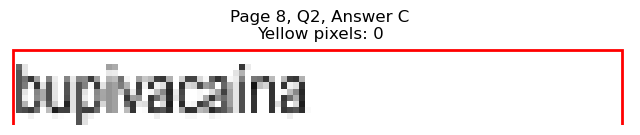

Page 8, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=365.2, y1=177.8
Page 8, Q2, D: Yellow pixels: 1031
Page 8, Q2, D: Total non-white pixels: 1157
Page 8, Q2, D: Yellow percentage: 89.1%


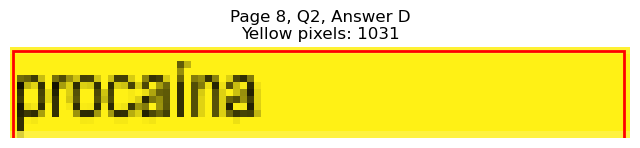

Page 8, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=376.3, y1=190.4
Page 8, Q2, E: Yellow pixels: 100
Page 8, Q2, E: Total non-white pixels: 347
Page 8, Q2, E: Yellow percentage: 28.8%


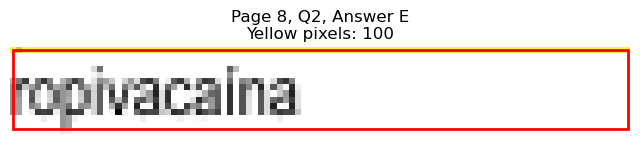


Page 8, Q2 - Selected Answer: D (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=79.3, y1=253.5
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 42
Page 8, Q3, A: Yellow percentage: 0.0%


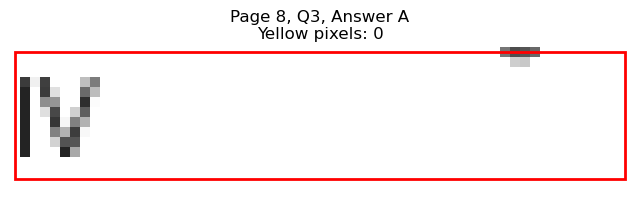

Page 8, Q3 - B: Detected box: x0=56.6, y0=253.5, x1=65.2, y1=266.1
Page 8, Q3, B: Yellow pixels: 0
Page 8, Q3, B: Total non-white pixels: 66
Page 8, Q3, B: Yellow percentage: 0.0%


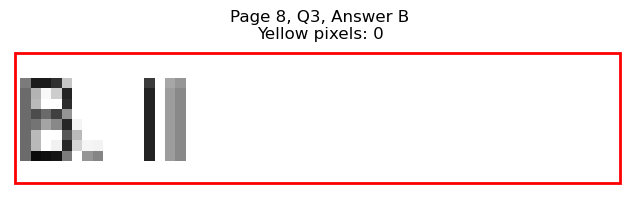

Page 8, Q3 - C: Detected box: x0=56.6, y0=266.1, x1=65.6, y1=278.7
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 53
Page 8, Q3, C: Yellow percentage: 0.0%


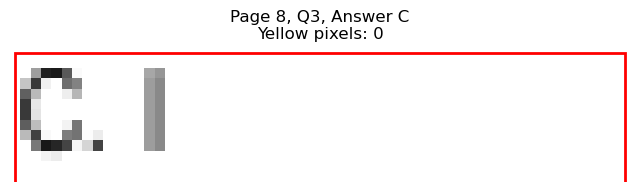

Page 8, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=337.6, y1=253.5
Page 8, Q3, D: Yellow pixels: 753
Page 8, Q3, D: Total non-white pixels: 854
Page 8, Q3, D: Yellow percentage: 88.2%


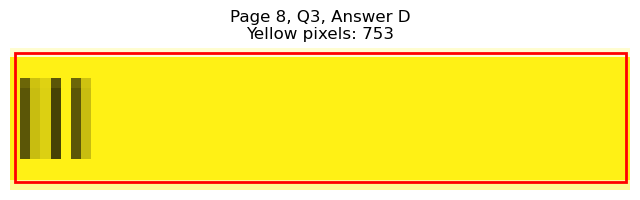

Page 8, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=335.6, y1=266.1
Page 8, Q3, E: Yellow pixels: 59
Page 8, Q3, E: Total non-white pixels: 85
Page 8, Q3, E: Yellow percentage: 69.4%


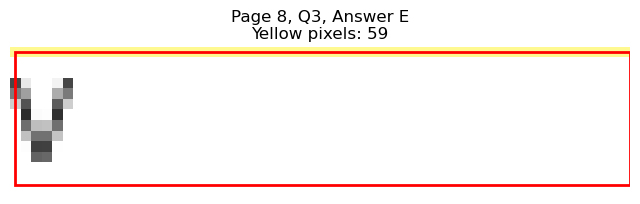


Page 8, Q3 - Selected Answer: D (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=127.5, y1=316.7
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 299
Page 8, Q4, A: Yellow percentage: 0.0%


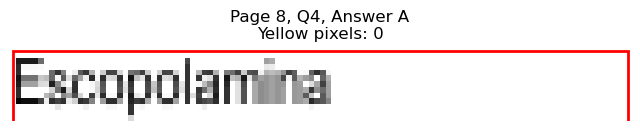

Page 8, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=127.0, y1=329.3
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 313
Page 8, Q4, B: Yellow percentage: 0.0%


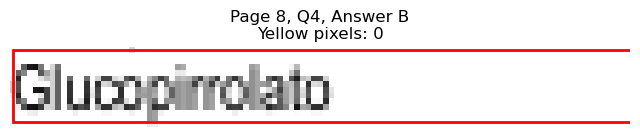

Page 8, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=121.5, y1=341.9
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 280
Page 8, Q4, C: Yellow percentage: 0.0%


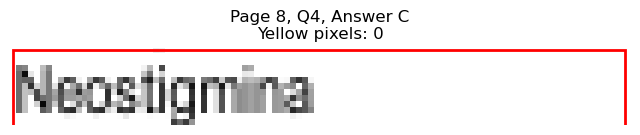

Page 8, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=363.7, y1=316.7
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 282
Page 8, Q4, D: Yellow percentage: 0.0%


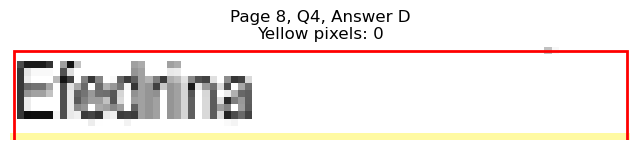

Page 8, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=363.2, y1=329.3
Page 8, Q4, E: Yellow pixels: 913
Page 8, Q4, E: Total non-white pixels: 1218
Page 8, Q4, E: Yellow percentage: 75.0%


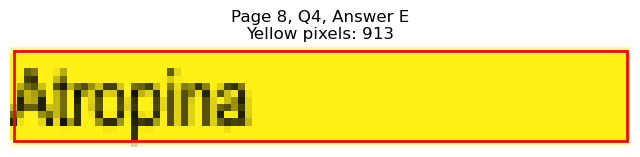


Page 8, Q4 - Selected Answer: E (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=76.8, y1=392.4
Page 8, Q5, A: Yellow pixels: 685
Page 8, Q5, A: Total non-white pixels: 826
Page 8, Q5, A: Yellow percentage: 82.9%


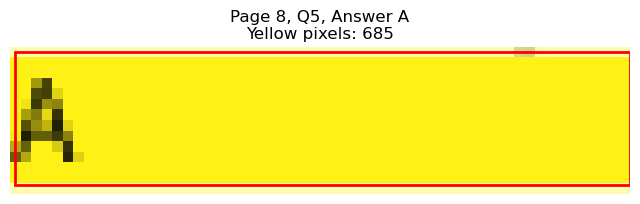

Page 8, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=76.8, y1=405.0
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 100
Page 8, Q5, B: Yellow percentage: 0.0%


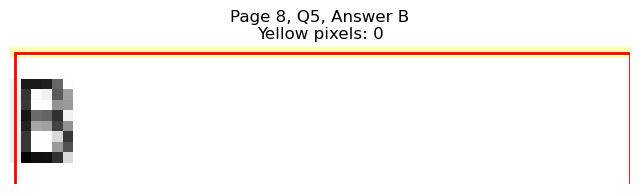

Page 8, Q5 - C: Detected box: x0=56.6, y0=404.9, x1=65.6, y1=417.6
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 65
Page 8, Q5, C: Yellow percentage: 0.0%


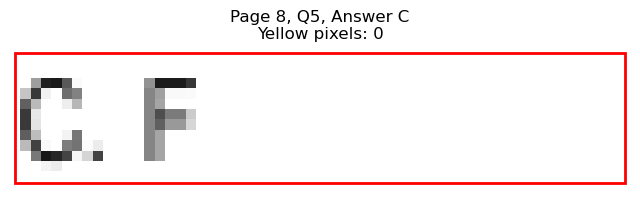

Page 8, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=336.5, y1=392.4
Page 8, Q5, D: Yellow pixels: 0
Page 8, Q5, D: Total non-white pixels: 37
Page 8, Q5, D: Yellow percentage: 0.0%


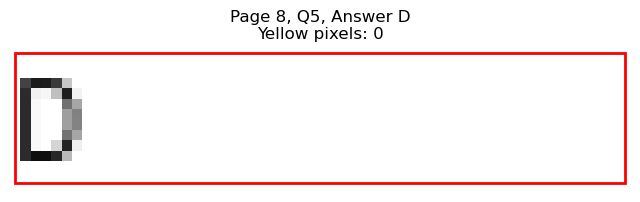

Page 8, Q5 - E: Detected box: x0=327.0, y0=392.3, x1=336.1, y1=405.0
Page 8, Q5, E: Yellow pixels: 0
Page 8, Q5, E: Total non-white pixels: 33
Page 8, Q5, E: Yellow percentage: 0.0%


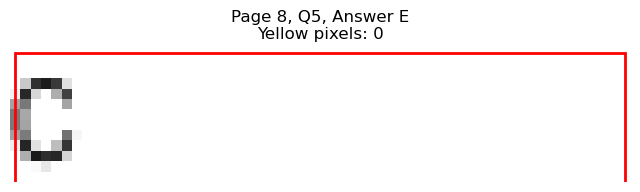


Page 8, Q5 - Selected Answer: A (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=56.6, y0=468.1, x1=65.2, y1=480.7
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 43
Page 8, Q6, A: Yellow percentage: 0.0%


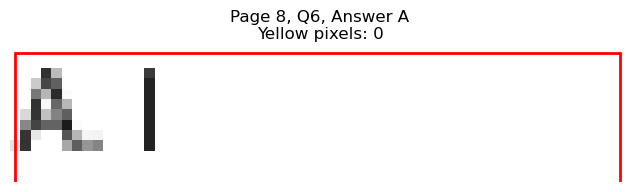

Page 8, Q6 - B: Detected box: x0=56.6, y0=253.5, x1=65.2, y1=266.1
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 66
Page 8, Q6, B: Yellow percentage: 0.0%


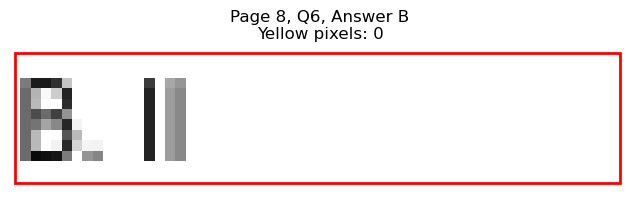

Page 8, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=79.8, y1=506.0
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 44
Page 8, Q6, C: Yellow percentage: 0.0%


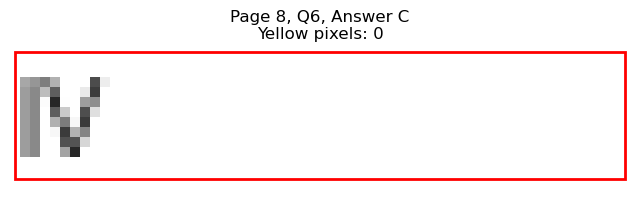

Page 8, Q6 - D: Detected box: x0=315.4, y0=468.1, x1=324.4, y1=480.7
Page 8, Q6, D: Yellow pixels: 0
Page 8, Q6, D: Total non-white pixels: 71
Page 8, Q6, D: Yellow percentage: 0.0%


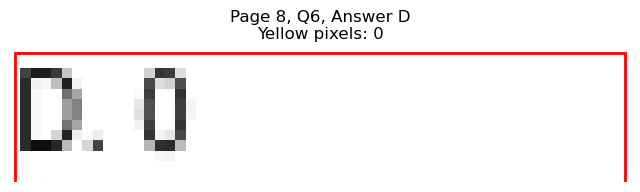

Page 8, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=337.1, y1=493.4
Page 8, Q6, E: Yellow pixels: 700
Page 8, Q6, E: Total non-white pixels: 854
Page 8, Q6, E: Yellow percentage: 82.0%


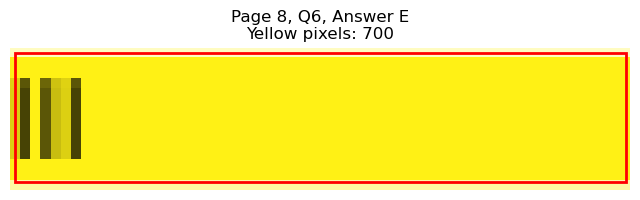


Page 8, Q6 - Selected Answer: E (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=247.8, y1=569.2
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 946
Page 8, Q7, A: Yellow percentage: 0.0%


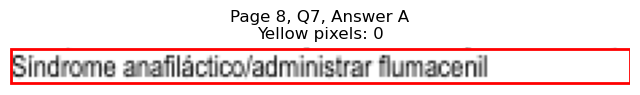

Page 8, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=245.0, y1=581.8
Page 8, Q7, B: Yellow pixels: 1
Page 8, Q7, B: Total non-white pixels: 1129
Page 8, Q7, B: Yellow percentage: 0.1%


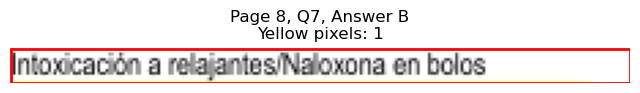

Page 8, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=244.4, y1=594.4
Page 8, Q7, C: Yellow pixels: 1841
Page 8, Q7, C: Total non-white pixels: 2996
Page 8, Q7, C: Yellow percentage: 61.4%


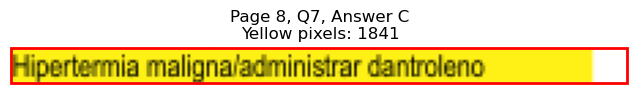

Page 8, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=504.7, y1=569.2
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 922
Page 8, Q7, D: Yellow percentage: 0.0%


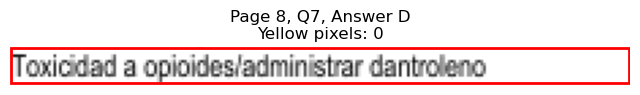

Page 8, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=481.1, y1=581.8
Page 8, Q7, E: Yellow pixels: 0
Page 8, Q7, E: Total non-white pixels: 806
Page 8, Q7, E: Yellow percentage: 0.0%


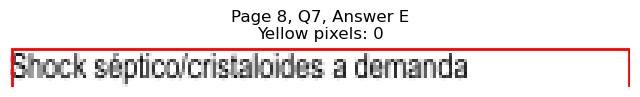


Page 8, Q7 - Selected Answer: C (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=120.5, y1=632.3
Page 8, Q8, A: Yellow pixels: 0
Page 8, Q8, A: Total non-white pixels: 273
Page 8, Q8, A: Yellow percentage: 0.0%


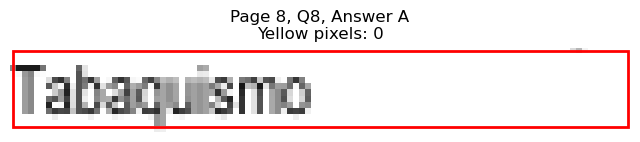

Page 8, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=139.5, y1=644.9
Page 8, Q8, B: Yellow pixels: 0
Page 8, Q8, B: Total non-white pixels: 385
Page 8, Q8, B: Yellow percentage: 0.0%


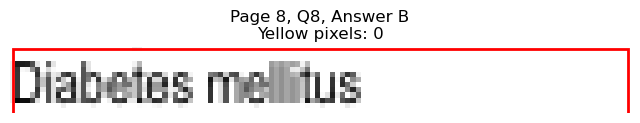

Page 8, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=134.1, y1=657.5
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 318
Page 8, Q8, C: Yellow percentage: 0.0%


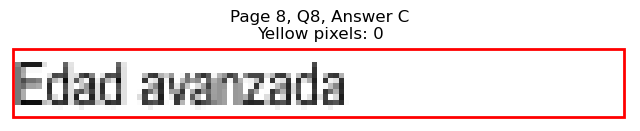

Page 8, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=431.3, y1=632.3
Page 8, Q8, D: Yellow pixels: 1451
Page 8, Q8, D: Total non-white pixels: 2170
Page 8, Q8, D: Yellow percentage: 66.9%


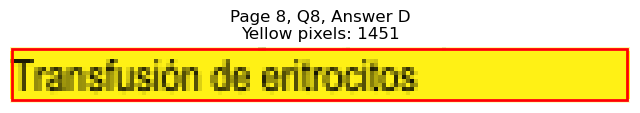

Page 8, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=419.3, y1=644.9
Page 8, Q8, E: Yellow pixels: 0
Page 8, Q8, E: Total non-white pixels: 610
Page 8, Q8, E: Yellow percentage: 0.0%


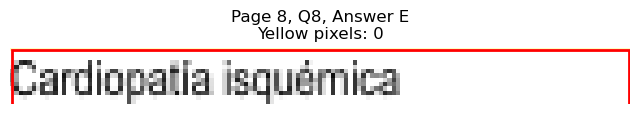


Page 8, Q8 - Selected Answer: D (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=88.3, y1=720.6
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 88
Page 8, Q9, A: Yellow percentage: 0.0%


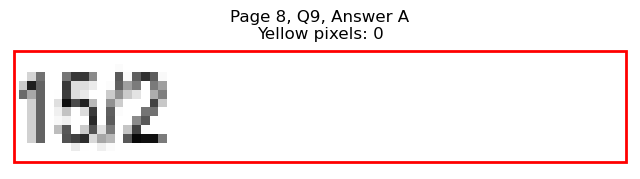

Page 8, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=88.3, y1=733.2
Page 8, Q9, B: Yellow pixels: 71
Page 8, Q9, B: Total non-white pixels: 167
Page 8, Q9, B: Yellow percentage: 42.5%


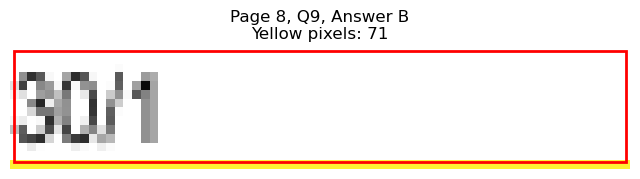

Page 8, Q9 - C: Detected box: x0=68.8, y0=733.2, x1=88.8, y1=745.8
Page 8, Q9, C: Yellow pixels: 850
Page 8, Q9, C: Total non-white pixels: 923
Page 8, Q9, C: Yellow percentage: 92.1%


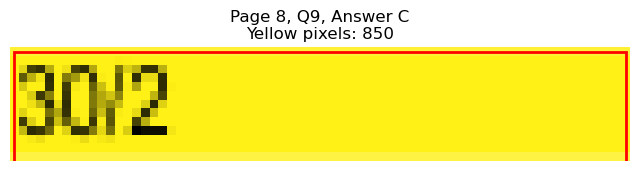

Page 8, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=347.6, y1=720.6
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 75
Page 8, Q9, D: Yellow percentage: 0.0%


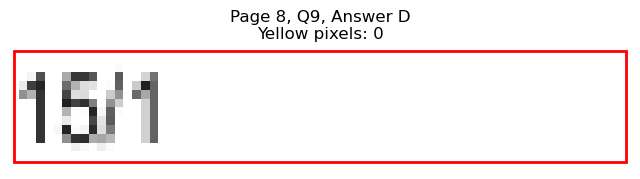

Page 8, Q9 - E: Detected box: x0=327.0, y0=720.6, x1=347.1, y1=733.2
Page 8, Q9, E: Yellow pixels: 0
Page 8, Q9, E: Total non-white pixels: 98
Page 8, Q9, E: Yellow percentage: 0.0%


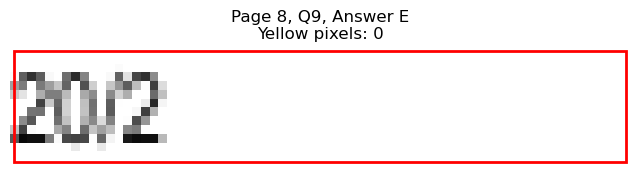


Page 8, Q9 - Selected Answer: C (based on yellow pixel count)





Page 9: Found 8 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=123.0, y1=102.1
Page 9, Q1, A: Yellow pixels: 106
Page 9, Q1, A: Total non-white pixels: 365
Page 9, Q1, A: Yellow percentage: 29.0%


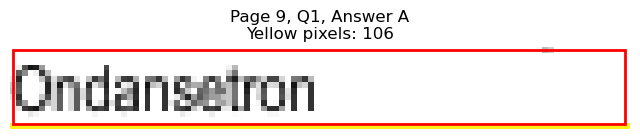

Page 9, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=114.4, y1=114.7
Page 9, Q1, B: Yellow pixels: 1075
Page 9, Q1, B: Total non-white pixels: 1261
Page 9, Q1, B: Yellow percentage: 85.2%


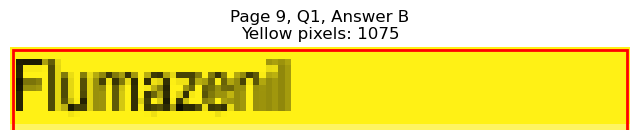

Page 9, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=115.5, y1=127.3
Page 9, Q1, C: Yellow pixels: 98
Page 9, Q1, C: Total non-white pixels: 333
Page 9, Q1, C: Yellow percentage: 29.4%


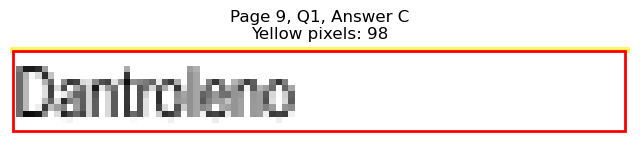

Page 9, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=402.8, y1=102.1
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 394
Page 9, Q1, D: Yellow percentage: 0.0%


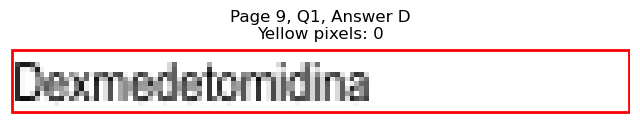

Page 9, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=371.2, y1=114.7
Page 9, Q1, E: Yellow pixels: 0
Page 9, Q1, E: Total non-white pixels: 228
Page 9, Q1, E: Yellow percentage: 0.0%


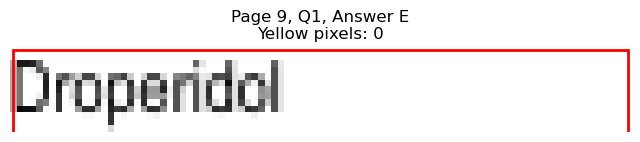


Page 9, Q1 - Selected Answer: B (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=112.9, y1=165.2
Page 9, Q2, A: Yellow pixels: 95
Page 9, Q2, A: Total non-white pixels: 307
Page 9, Q2, A: Yellow percentage: 30.9%


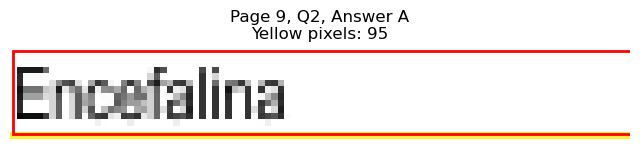

Page 9, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=118.9, y1=177.8
Page 9, Q2, B: Yellow pixels: 1123
Page 9, Q2, B: Total non-white pixels: 1313
Page 9, Q2, B: Yellow percentage: 85.5%


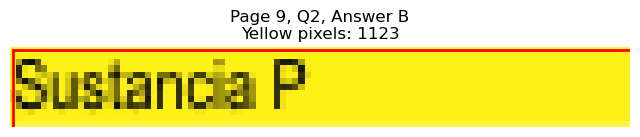

Page 9, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=115.0, y1=190.4
Page 9, Q2, C: Yellow pixels: 97
Page 9, Q2, C: Total non-white pixels: 314
Page 9, Q2, C: Yellow percentage: 30.9%


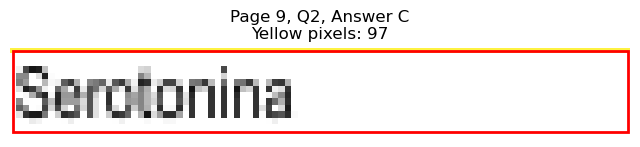

Page 9, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=357.7, y1=165.2
Page 9, Q2, D: Yellow pixels: 0
Page 9, Q2, D: Total non-white pixels: 144
Page 9, Q2, D: Yellow percentage: 0.0%


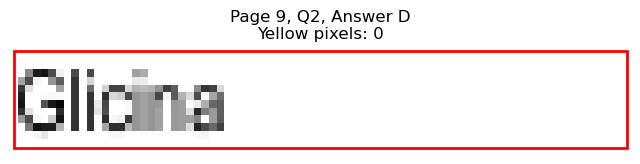

Page 9, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=372.2, y1=177.8
Page 9, Q2, E: Yellow pixels: 0
Page 9, Q2, E: Total non-white pixels: 233
Page 9, Q2, E: Yellow percentage: 0.0%


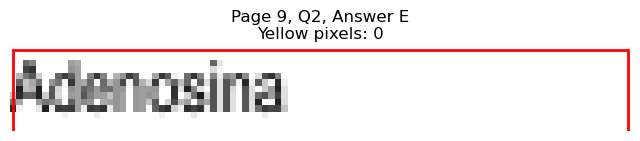


Page 9, Q2 - Selected Answer: B (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=115.6, y1=228.3
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 244
Page 9, Q3, A: Yellow percentage: 0.0%


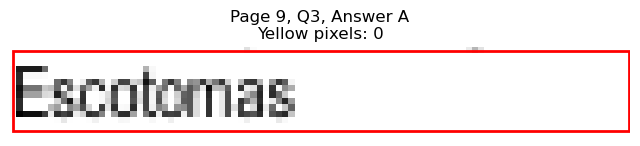

Page 9, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=100.9, y1=240.9
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 159
Page 9, Q3, B: Yellow percentage: 0.0%


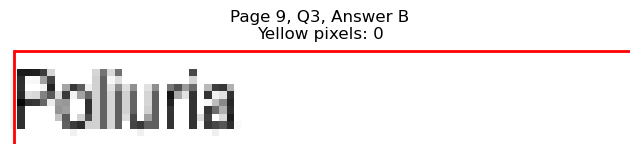

Page 9, Q3 - C: Detected box: x0=68.8, y0=240.9, x1=141.6, y1=253.5
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 380
Page 9, Q3, C: Yellow percentage: 0.0%


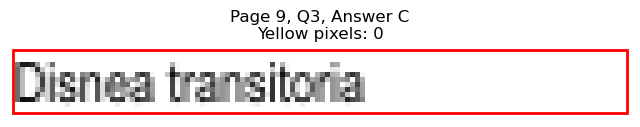

Page 9, Q3 - D: Detected box: x0=327.5, y0=215.7, x1=385.3, y1=228.3
Page 9, Q3, D: Yellow pixels: 109
Page 9, Q3, D: Total non-white pixels: 417
Page 9, Q3, D: Yellow percentage: 26.1%


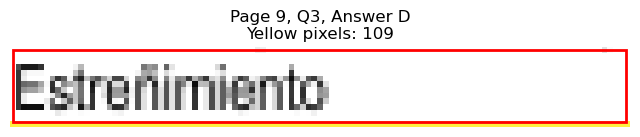

Page 9, Q3 - E: Detected box: x0=327.0, y0=228.3, x1=410.3, y1=240.9
Page 9, Q3, E: Yellow pixels: 1402
Page 9, Q3, E: Total non-white pixels: 1742
Page 9, Q3, E: Yellow percentage: 80.5%


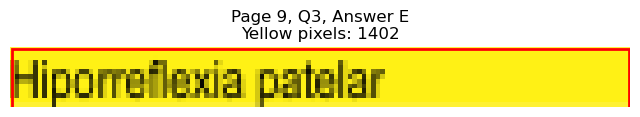


Page 9, Q3 - Selected Answer: E (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=152.2, y1=304.1
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 381
Page 9, Q4, A: Yellow percentage: 0.0%


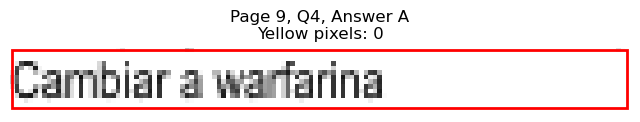

Page 9, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=254.9, y1=316.7
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 942
Page 9, Q4, B: Yellow percentage: 0.0%


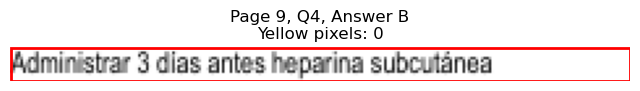

Page 9, Q4 - C: Detected box: x0=68.8, y0=316.6, x1=220.8, y1=329.3
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 751
Page 9, Q4, C: Yellow percentage: 0.0%


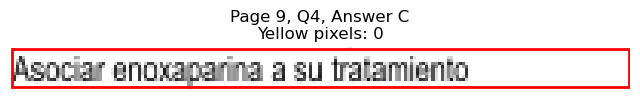

Page 9, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=429.9, y1=304.1
Page 9, Q4, D: Yellow pixels: 1587
Page 9, Q4, D: Total non-white pixels: 2142
Page 9, Q4, D: Yellow percentage: 74.1%


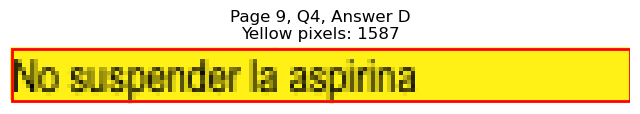

Page 9, Q4 - E: Detected box: x0=327.0, y0=304.0, x1=437.9, y1=316.7
Page 9, Q4, E: Yellow pixels: 0
Page 9, Q4, E: Total non-white pixels: 716
Page 9, Q4, E: Yellow percentage: 0.0%


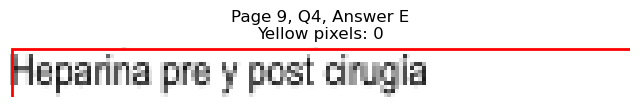


Page 9, Q4 - Selected Answer: D (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=339.3, y1=405.0
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 1665
Page 9, Q5, A: Yellow percentage: 0.0%


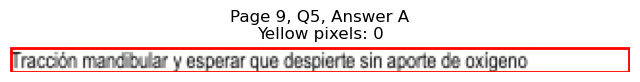

Page 9, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=363.8, y1=417.6
Page 9, Q5, B: Yellow pixels: 3343
Page 9, Q5, B: Total non-white pixels: 4844
Page 9, Q5, B: Yellow percentage: 69.0%


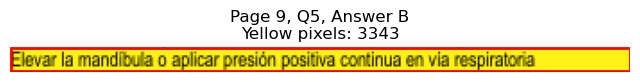

Page 9, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=263.6, y1=430.3
Page 9, Q5, C: Yellow pixels: 246
Page 9, Q5, C: Total non-white pixels: 1219
Page 9, Q5, C: Yellow percentage: 20.2%


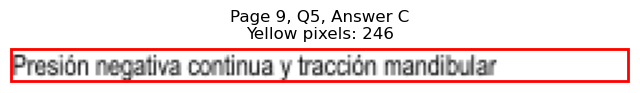

Page 9, Q5 - D: Detected box: x0=68.8, y0=430.2, x1=128.0, y1=442.9
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 323
Page 9, Q5, D: Yellow percentage: 0.0%


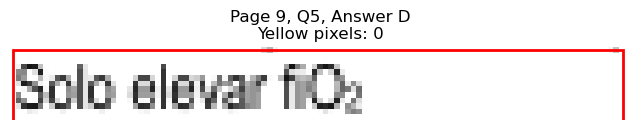

Page 9, Q5 - E: Detected box: x0=68.3, y0=442.8, x1=281.0, y1=455.5
Page 9, Q5, E: Yellow pixels: 0
Page 9, Q5, E: Total non-white pixels: 1048
Page 9, Q5, E: Yellow percentage: 0.0%


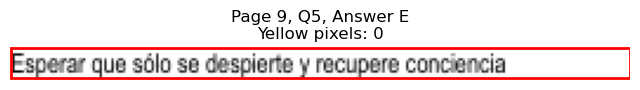


Page 9, Q5 - Selected Answer: B (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=172.6, y1=493.4
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 509
Page 9, Q6, A: Yellow percentage: 0.0%


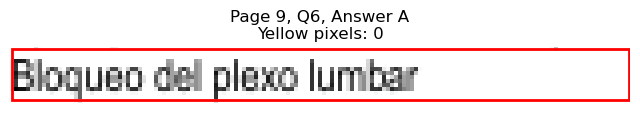

Page 9, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=162.1, y1=506.0
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 485
Page 9, Q6, B: Yellow percentage: 0.0%


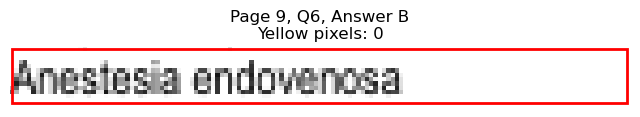

Page 9, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=155.2, y1=518.6
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 445
Page 9, Q6, C: Yellow percentage: 0.0%


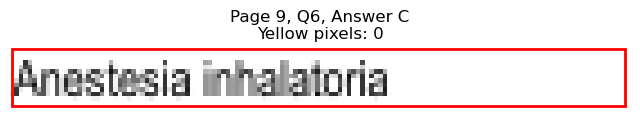

Page 9, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=445.9, y1=493.4
Page 9, Q6, D: Yellow pixels: 169
Page 9, Q6, D: Total non-white pixels: 733
Page 9, Q6, D: Yellow percentage: 23.1%


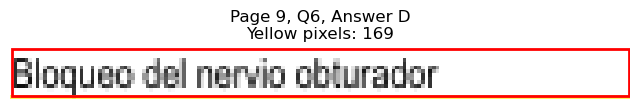

Page 9, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=413.3, y1=506.0
Page 9, Q6, E: Yellow pixels: 1428
Page 9, Q6, E: Total non-white pixels: 1781
Page 9, Q6, E: Yellow percentage: 80.2%


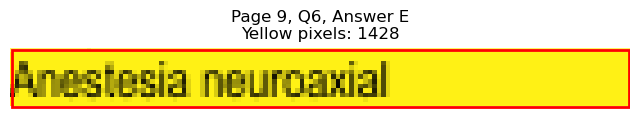


Page 9, Q6 - Selected Answer: E (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=343.7, y1=581.8
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 1381
Page 9, Q7, A: Yellow percentage: 0.0%


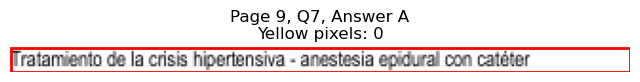

Page 9, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=237.5, y1=594.4
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 851
Page 9, Q7, B: Yellow percentage: 0.0%


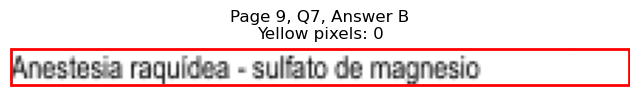

Page 9, Q7 - C: Detected box: x0=68.8, y0=594.3, x1=296.1, y1=607.0
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 1375
Page 9, Q7, C: Yellow percentage: 0.0%


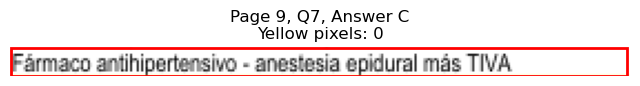

Page 9, Q7 - D: Detected box: x0=68.8, y0=606.9, x1=382.3, y1=619.6
Page 9, Q7, D: Yellow pixels: 3567
Page 9, Q7, D: Total non-white pixels: 5110
Page 9, Q7, D: Yellow percentage: 69.8%


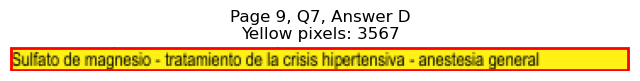

Page 9, Q7 - E: Detected box: x0=68.3, y0=619.6, x1=309.2, y1=632.3
Page 9, Q7, E: Yellow pixels: 288
Page 9, Q7, E: Total non-white pixels: 1483
Page 9, Q7, E: Yellow percentage: 19.4%


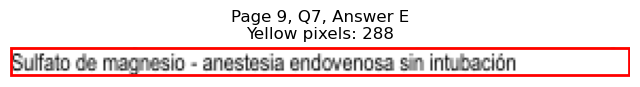


Page 9, Q7 - Selected Answer: D (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=68.3, y0=657.5, x1=161.5, y1=670.1
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 469
Page 9, Q8, A: Yellow percentage: 0.0%


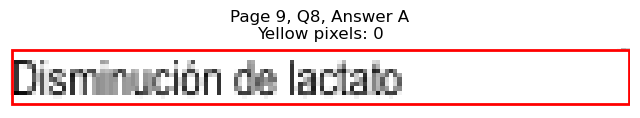

Page 9, Q8 - B: Detected box: x0=68.3, y0=670.1, x1=204.3, y1=682.7
Page 9, Q8, B: Yellow pixels: 0
Page 9, Q8, B: Total non-white pixels: 679
Page 9, Q8, B: Yellow percentage: 0.0%


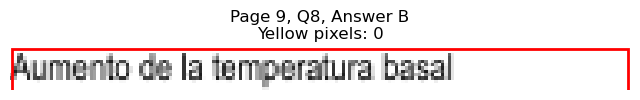

Page 9, Q8 - C: Detected box: x0=68.8, y0=682.7, x1=191.7, y1=695.3
Page 9, Q8, C: Yellow pixels: 0
Page 9, Q8, C: Total non-white pixels: 609
Page 9, Q8, C: Yellow percentage: 0.0%


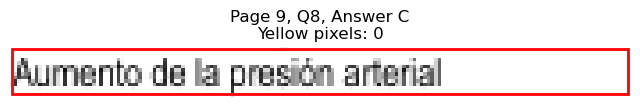

Page 9, Q8 - D: Detected box: x0=327.5, y0=657.5, x1=444.9, y1=670.1
Page 9, Q8, D: Yellow pixels: 1726
Page 9, Q8, D: Total non-white pixels: 2352
Page 9, Q8, D: Yellow percentage: 73.4%


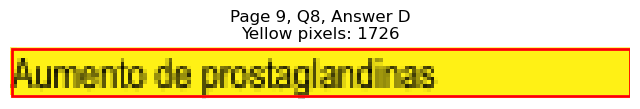

Page 9, Q8 - E: Detected box: x0=327.0, y0=670.1, x1=443.0, y1=682.7
Page 9, Q8, E: Yellow pixels: 0
Page 9, Q8, E: Total non-white pixels: 723
Page 9, Q8, E: Yellow percentage: 0.0%


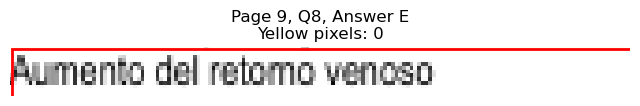


Page 9, Q8 - Selected Answer: D (based on yellow pixel count)





Page 10: Found 9 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=298.6, y1=102.1
Page 10, Q1, A: Yellow pixels: 0
Page 10, Q1, A: Total non-white pixels: 1189
Page 10, Q1, A: Yellow percentage: 0.0%


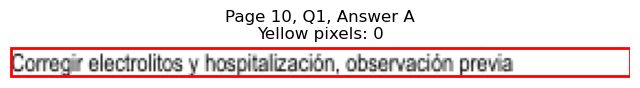

Page 10, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=296.0, y1=114.7
Page 10, Q1, B: Yellow pixels: 7
Page 10, Q1, B: Total non-white pixels: 1371
Page 10, Q1, B: Yellow percentage: 0.5%


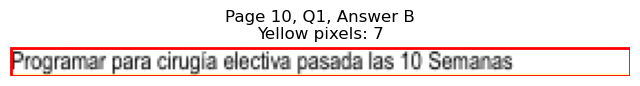

Page 10, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=374.7, y1=127.3
Page 10, Q1, C: Yellow pixels: 3037
Page 10, Q1, C: Total non-white pixels: 4998
Page 10, Q1, C: Yellow percentage: 60.8%


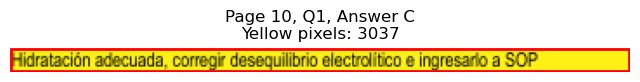

Page 10, Q1 - D: Detected box: x0=68.8, y0=127.2, x1=207.2, y1=139.9
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 869
Page 10, Q1, D: Yellow percentage: 0.0%


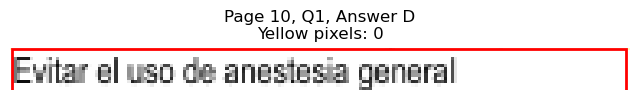

Page 10, Q1 - E: Detected box: x0=68.3, y0=139.9, x1=245.0, y1=152.6
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 882
Page 10, Q1, E: Yellow percentage: 0.0%


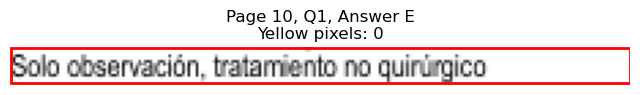


Page 10, Q1 - Selected Answer: C (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=132.0, y1=190.4
Page 10, Q2, A: Yellow pixels: 115
Page 10, Q2, A: Total non-white pixels: 438
Page 10, Q2, A: Yellow percentage: 26.3%


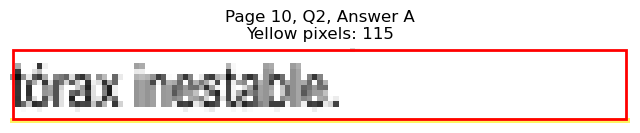

Page 10, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=164.7, y1=203.0
Page 10, Q2, B: Yellow pixels: 1529
Page 10, Q2, B: Total non-white pixels: 1911
Page 10, Q2, B: Yellow percentage: 80.0%


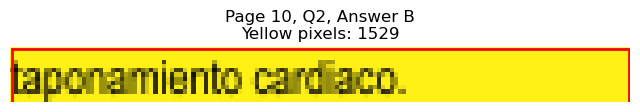

Page 10, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=127.0, y1=215.6
Page 10, Q2, C: Yellow pixels: 108
Page 10, Q2, C: Total non-white pixels: 390
Page 10, Q2, C: Yellow percentage: 27.7%


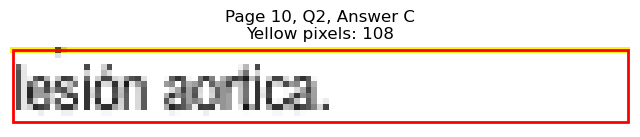

Page 10, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=417.3, y1=190.4
Page 10, Q2, D: Yellow pixels: 0
Page 10, Q2, D: Total non-white pixels: 454
Page 10, Q2, D: Yellow percentage: 0.0%


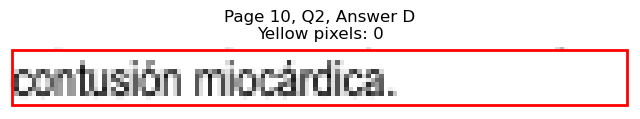

Page 10, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=412.4, y1=203.0
Page 10, Q2, E: Yellow pixels: 0
Page 10, Q2, E: Total non-white pixels: 440
Page 10, Q2, E: Yellow percentage: 0.0%


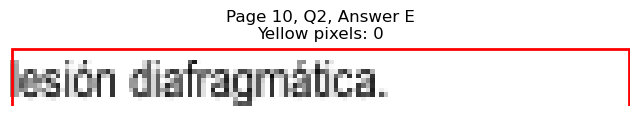


Page 10, Q2 - Selected Answer: B (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=103.5, y1=253.5
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 161
Page 10, Q3, A: Yellow percentage: 0.0%


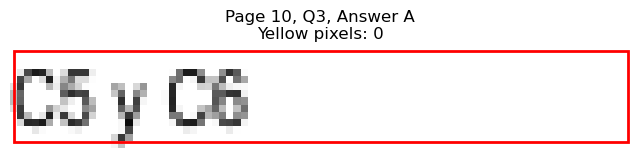

Page 10, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=103.5, y1=266.1
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 151
Page 10, Q3, B: Yellow percentage: 0.0%


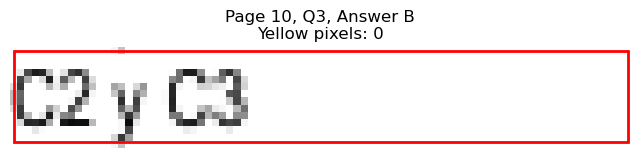

Page 10, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=103.9, y1=278.7
Page 10, Q3, C: Yellow pixels: 0
Page 10, Q3, C: Total non-white pixels: 149
Page 10, Q3, C: Yellow percentage: 0.0%


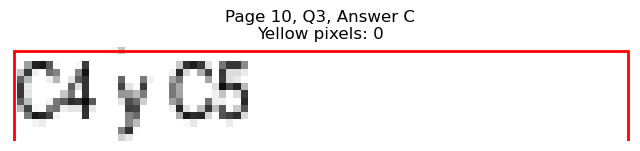

Page 10, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=362.7, y1=253.5
Page 10, Q3, D: Yellow pixels: 86
Page 10, Q3, D: Total non-white pixels: 240
Page 10, Q3, D: Yellow percentage: 35.8%


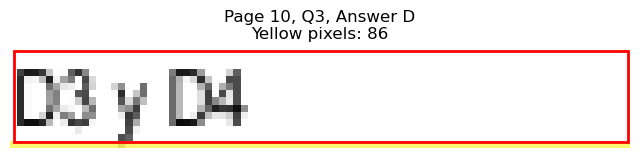

Page 10, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=362.2, y1=266.1
Page 10, Q3, E: Yellow pixels: 1024
Page 10, Q3, E: Total non-white pixels: 1204
Page 10, Q3, E: Yellow percentage: 85.0%


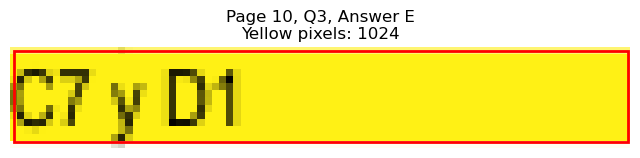


Page 10, Q3 - Selected Answer: E (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=207.3, y1=341.9
Page 10, Q4, A: Yellow pixels: 1908
Page 10, Q4, A: Total non-white pixels: 2470
Page 10, Q4, A: Yellow percentage: 77.2%


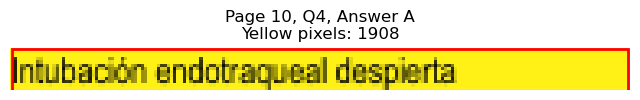

Page 10, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=251.9, y1=354.6
Page 10, Q4, B: Yellow pixels: 209
Page 10, Q4, B: Total non-white pixels: 1125
Page 10, Q4, B: Yellow percentage: 18.6%


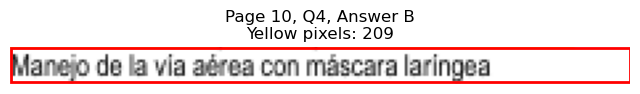

Page 10, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=169.6, y1=367.2
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 514
Page 10, Q4, C: Yellow percentage: 0.0%


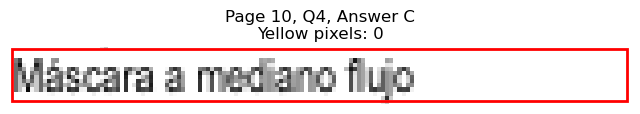

Page 10, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=421.3, y1=341.9
Page 10, Q4, D: Yellow pixels: 0
Page 10, Q4, D: Total non-white pixels: 454
Page 10, Q4, D: Yellow percentage: 0.0%


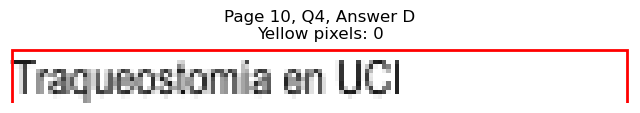

Page 10, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=479.1, y1=354.6
Page 10, Q4, E: Yellow pixels: 0
Page 10, Q4, E: Total non-white pixels: 704
Page 10, Q4, E: Yellow percentage: 0.0%


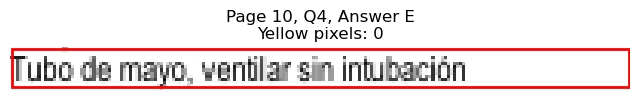


Page 10, Q4 - Selected Answer: A (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=78.4, y1=417.6
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 32
Page 10, Q5, A: Yellow percentage: 0.0%


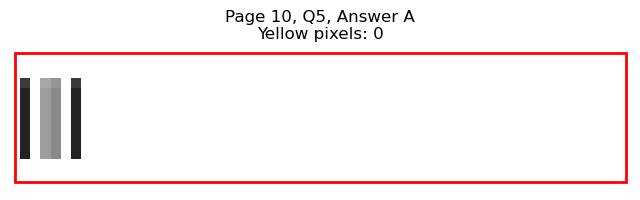

Page 10, Q5 - B: Detected box: x0=56.6, y0=417.6, x1=65.2, y1=430.3
Page 10, Q5, B: Yellow pixels: 0
Page 10, Q5, B: Total non-white pixels: 50
Page 10, Q5, B: Yellow percentage: 0.0%


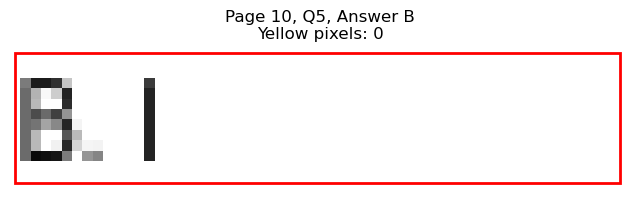

Page 10, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=79.8, y1=442.9
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 44
Page 10, Q5, C: Yellow percentage: 0.0%


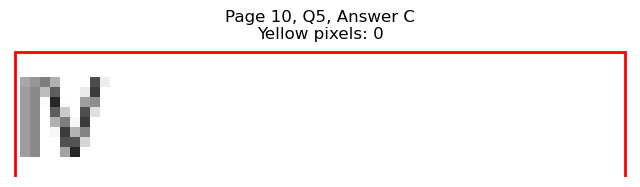

Page 10, Q5 - D: Detected box: x0=315.4, y0=404.9, x1=324.4, y1=417.6
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 69
Page 10, Q5, D: Yellow percentage: 0.0%


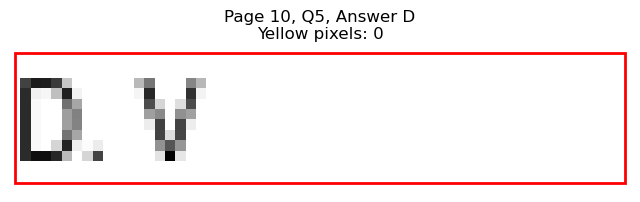

Page 10, Q5 - E: Detected box: x0=315.4, y0=417.6, x1=323.9, y1=430.3
Page 10, Q5, E: Yellow pixels: 658
Page 10, Q5, E: Total non-white pixels: 826
Page 10, Q5, E: Yellow percentage: 79.7%


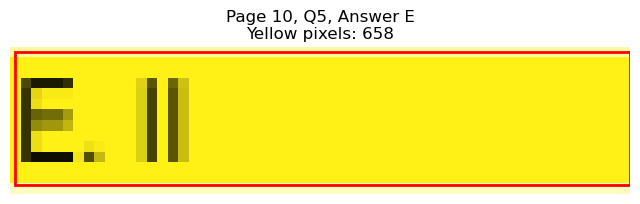


Page 10, Q5 - Selected Answer: E (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=109.9, y1=480.7
Page 10, Q6, A: Yellow pixels: 0
Page 10, Q6, A: Total non-white pixels: 201
Page 10, Q6, A: Yellow percentage: 0.0%


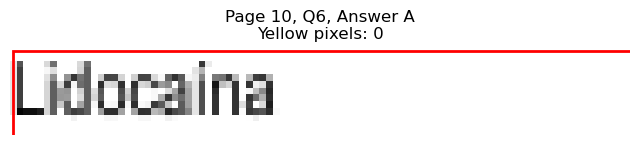

Page 10, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=113.4, y1=493.4
Page 10, Q6, B: Yellow pixels: 0
Page 10, Q6, B: Total non-white pixels: 236
Page 10, Q6, B: Yellow percentage: 0.0%


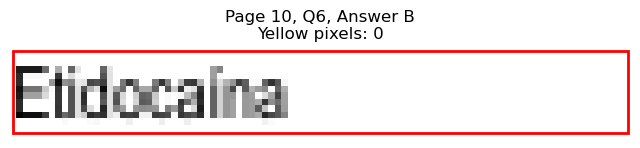

Page 10, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=122.4, y1=506.0
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 282
Page 10, Q6, C: Yellow percentage: 0.0%


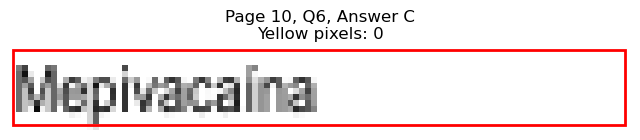

Page 10, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=379.7, y1=480.7
Page 10, Q6, D: Yellow pixels: 1142
Page 10, Q6, D: Total non-white pixels: 1339
Page 10, Q6, D: Yellow percentage: 85.3%


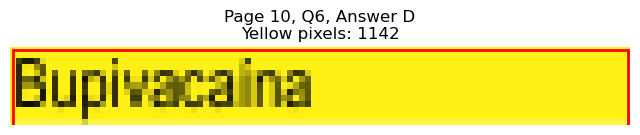

Page 10, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=370.1, y1=493.4
Page 10, Q6, E: Yellow pixels: 94
Page 10, Q6, E: Total non-white pixels: 290
Page 10, Q6, E: Yellow percentage: 32.4%


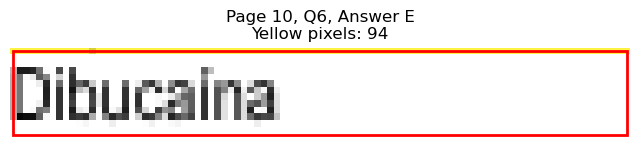


Page 10, Q6 - Selected Answer: D (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=358.3, y1=543.8
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 1394
Page 10, Q7, A: Yellow percentage: 0.0%


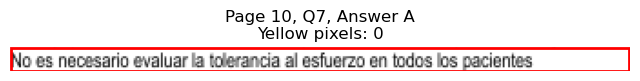

Page 10, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=350.3, y1=556.4
Page 10, Q7, B: Yellow pixels: 0
Page 10, Q7, B: Total non-white pixels: 1362
Page 10, Q7, B: Yellow percentage: 0.0%


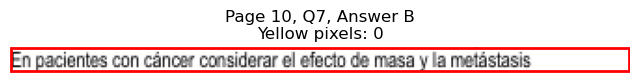

Page 10, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=409.4, y1=569.2
Page 10, Q7, C: Yellow pixels: 3734
Page 10, Q7, C: Total non-white pixels: 5488
Page 10, Q7, C: Yellow percentage: 68.0%


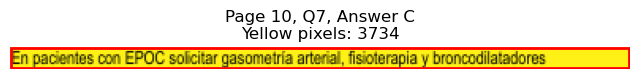

Page 10, Q7 - D: Detected box: x0=68.8, y0=569.1, x1=308.1, y1=581.8
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 1441
Page 10, Q7, D: Yellow percentage: 0.0%


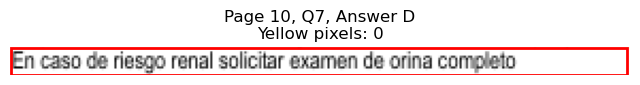

Page 10, Q7 - E: Detected box: x0=68.3, y0=581.7, x1=328.6, y1=594.4
Page 10, Q7, E: Yellow pixels: 0
Page 10, Q7, E: Total non-white pixels: 1254
Page 10, Q7, E: Yellow percentage: 0.0%


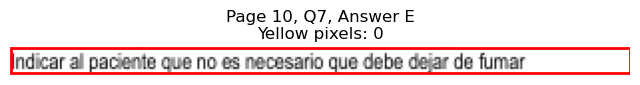


Page 10, Q7 - Selected Answer: C (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=147.6, y1=632.3
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 427
Page 10, Q8, A: Yellow percentage: 0.0%


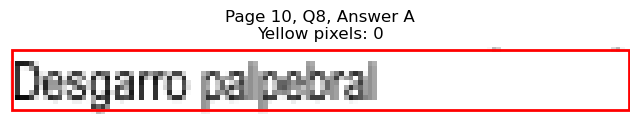

Page 10, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=140.5, y1=644.9
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 370
Page 10, Q8, B: Yellow percentage: 0.0%


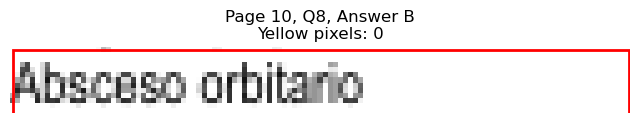

Page 10, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=116.4, y1=657.5
Page 10, Q8, C: Yellow pixels: 0
Page 10, Q8, C: Total non-white pixels: 244
Page 10, Q8, C: Yellow percentage: 0.0%


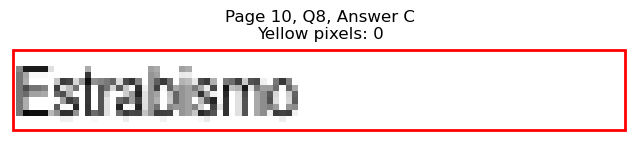

Page 10, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=397.7, y1=632.3
Page 10, Q8, D: Yellow pixels: 1182
Page 10, Q8, D: Total non-white pixels: 1694
Page 10, Q8, D: Yellow percentage: 69.8%


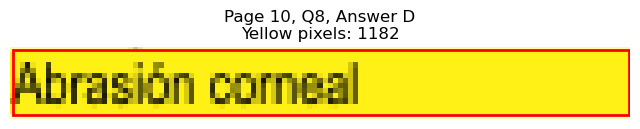

Page 10, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=374.2, y1=644.9
Page 10, Q8, E: Yellow pixels: 0
Page 10, Q8, E: Total non-white pixels: 341
Page 10, Q8, E: Yellow percentage: 0.0%


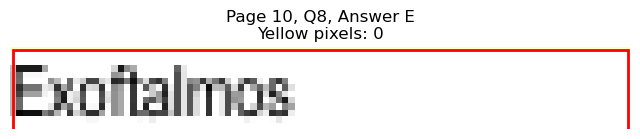


Page 10, Q8 - Selected Answer: D (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=56.6, y0=708.0, x1=65.2, y1=720.6
Page 10, Q9, A: Yellow pixels: 60
Page 10, Q9, A: Total non-white pixels: 122
Page 10, Q9, A: Yellow percentage: 49.2%


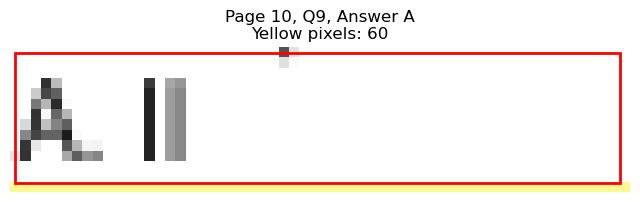

Page 10, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=78.4, y1=733.2
Page 10, Q9, B: Yellow pixels: 761
Page 10, Q9, B: Total non-white pixels: 854
Page 10, Q9, B: Yellow percentage: 89.1%


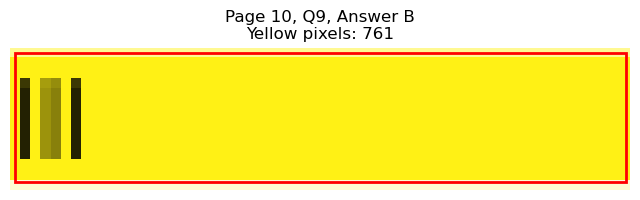

Page 10, Q9 - C: Detected box: x0=56.6, y0=733.2, x1=65.6, y1=745.8
Page 10, Q9, C: Yellow pixels: 0
Page 10, Q9, C: Total non-white pixels: 113
Page 10, Q9, C: Yellow percentage: 0.0%


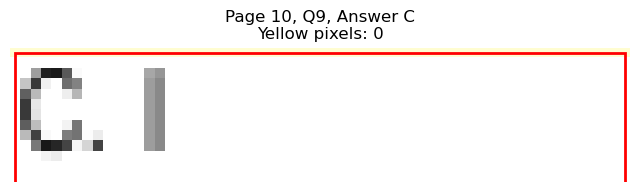

Page 10, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=338.6, y1=720.6
Page 10, Q9, D: Yellow pixels: 0
Page 10, Q9, D: Total non-white pixels: 42
Page 10, Q9, D: Yellow percentage: 0.0%


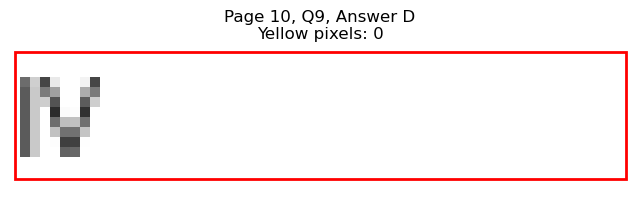

Page 10, Q9 - E: Detected box: x0=315.4, y0=720.6, x1=323.9, y1=733.2
Page 10, Q9, E: Yellow pixels: 0
Page 10, Q9, E: Total non-white pixels: 62
Page 10, Q9, E: Yellow percentage: 0.0%


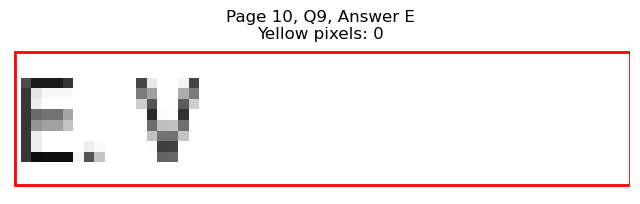


Page 10, Q9 - Selected Answer: B (based on yellow pixel count)





Page 11: Found 9 questions
Page 11, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=195.7, y1=102.1
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 619
Page 11, Q1, A: Yellow percentage: 0.0%


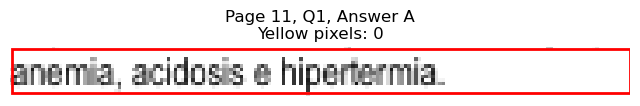

Page 11, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=183.6, y1=114.7
Page 11, Q1, B: Yellow pixels: 0
Page 11, Q1, B: Total non-white pixels: 543
Page 11, Q1, B: Yellow percentage: 0.0%


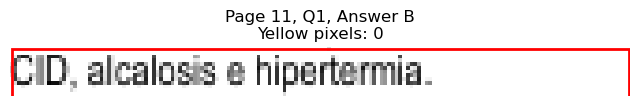

Page 11, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=231.3, y1=127.3
Page 11, Q1, C: Yellow pixels: 0
Page 11, Q1, C: Total non-white pixels: 849
Page 11, Q1, C: Yellow percentage: 0.0%


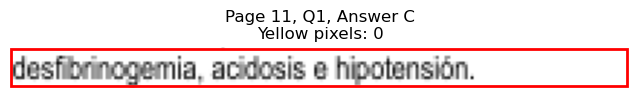

Page 11, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=514.1, y1=102.1
Page 11, Q1, D: Yellow pixels: 2034
Page 11, Q1, D: Total non-white pixels: 2995
Page 11, Q1, D: Yellow percentage: 67.9%


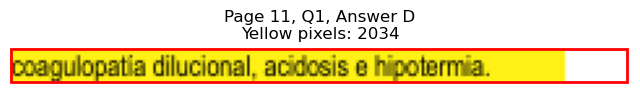

Page 11, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=477.5, y1=114.7
Page 11, Q1, E: Yellow pixels: 0
Page 11, Q1, E: Total non-white pixels: 935
Page 11, Q1, E: Yellow percentage: 0.0%


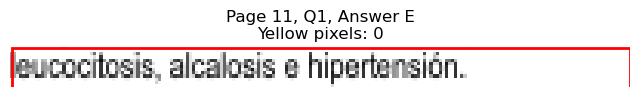


Page 11, Q1 - Selected Answer: D (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=67.7, y0=165.1, x1=282.4, y1=177.8
Page 11, Q2, A: Yellow pixels: 0
Page 11, Q2, A: Total non-white pixels: 1230
Page 11, Q2, A: Yellow percentage: 0.0%


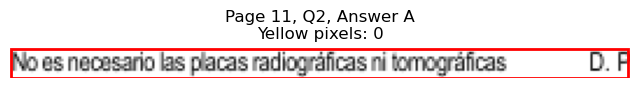

Page 11, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=262.4, y1=190.4
Page 11, Q2, B: Yellow pixels: 213
Page 11, Q2, B: Total non-white pixels: 1168
Page 11, Q2, B: Yellow percentage: 18.2%


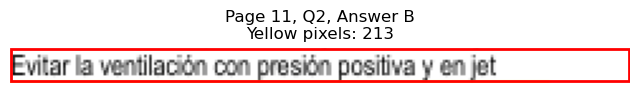

Page 11, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=275.9, y1=203.0
Page 11, Q2, C: Yellow pixels: 1938
Page 11, Q2, C: Total non-white pixels: 2818
Page 11, Q2, C: Yellow percentage: 68.8%


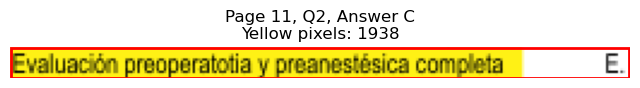

Page 11, Q2 - D: Detected box: x0=496.5, y0=165.1, x1=541.0, y1=177.8
Page 11, Q2, D: Yellow pixels: 0
Page 11, Q2, D: Total non-white pixels: 212
Page 11, Q2, D: Yellow percentage: 0.0%


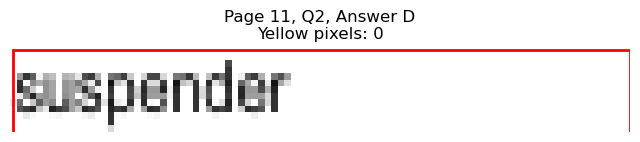

Page 11, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=513.7, y1=203.0
Page 11, Q2, E: Yellow pixels: 0
Page 11, Q2, E: Total non-white pixels: 913
Page 11, Q2, E: Yellow percentage: 0.0%


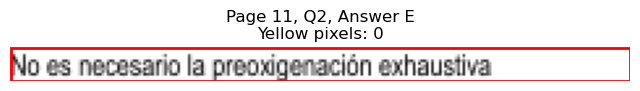


Page 11, Q2 - Selected Answer: C (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=308.6, y1=253.5
Page 11, Q3, A: Yellow pixels: 0
Page 11, Q3, A: Total non-white pixels: 1180
Page 11, Q3, A: Yellow percentage: 0.0%


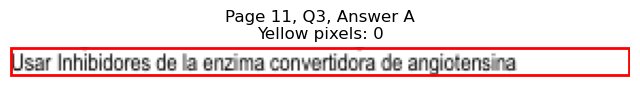

Page 11, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=183.1, y1=266.1
Page 11, Q3, B: Yellow pixels: 166
Page 11, Q3, B: Total non-white pixels: 708
Page 11, Q3, B: Yellow percentage: 23.4%


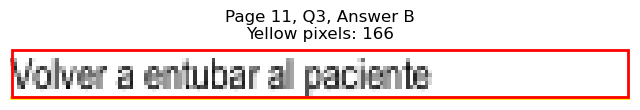

Page 11, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=344.0, y1=278.7
Page 11, Q3, C: Yellow pixels: 3140
Page 11, Q3, C: Total non-white pixels: 4238
Page 11, Q3, C: Yellow percentage: 74.1%


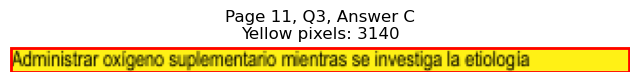

Page 11, Q3 - D: Detected box: x0=68.8, y0=278.8, x1=187.1, y1=291.5
Page 11, Q3, D: Yellow pixels: 169
Page 11, Q3, D: Total non-white pixels: 768
Page 11, Q3, D: Yellow percentage: 22.0%


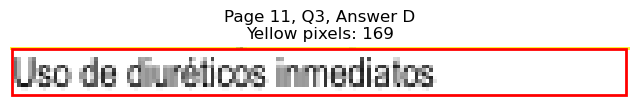

Page 11, Q3 - E: Detected box: x0=68.3, y0=291.4, x1=229.4, y1=304.1
Page 11, Q3, E: Yellow pixels: 0
Page 11, Q3, E: Total non-white pixels: 786
Page 11, Q3, E: Yellow percentage: 0.0%


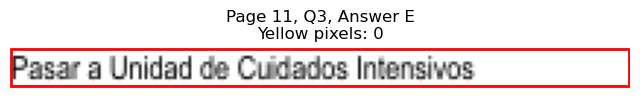


Page 11, Q3 - Selected Answer: C (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=157.6, y1=341.9
Page 11, Q4, A: Yellow pixels: 0
Page 11, Q4, A: Total non-white pixels: 464
Page 11, Q4, A: Yellow percentage: 0.0%


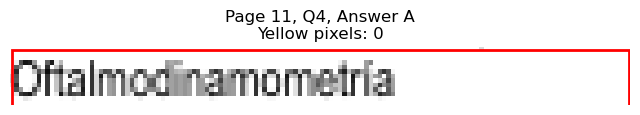

Page 11, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=236.8, y1=354.6
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 883
Page 11, Q4, B: Yellow percentage: 0.0%


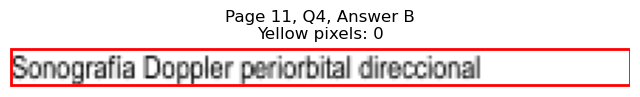

Page 11, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=195.7, y1=367.2
Page 11, Q4, C: Yellow pixels: 0
Page 11, Q4, C: Total non-white pixels: 673
Page 11, Q4, C: Yellow percentage: 0.0%


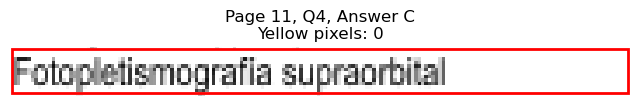

Page 11, Q4 - D: Detected box: x0=379.7, y0=329.2, x1=441.5, y1=341.9
Page 11, Q4, D: Yellow pixels: 1060
Page 11, Q4, D: Total non-white pixels: 1469
Page 11, Q4, D: Yellow percentage: 72.2%


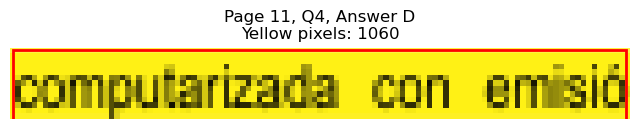

Page 11, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=480.6, y1=367.2
Page 11, Q4, E: Yellow pixels: 204
Page 11, Q4, E: Total non-white pixels: 979
Page 11, Q4, E: Yellow percentage: 20.8%


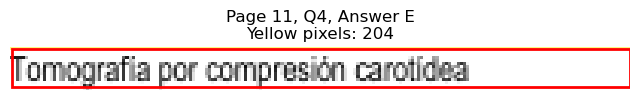


Page 11, Q4 - Selected Answer: D (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=107.9, y1=417.6
Page 11, Q5, A: Yellow pixels: 0
Page 11, Q5, A: Total non-white pixels: 178
Page 11, Q5, A: Yellow percentage: 0.0%


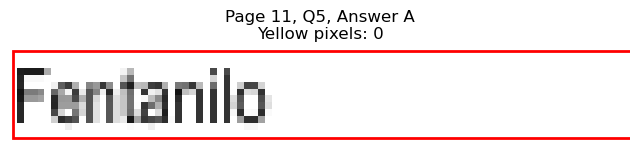

Page 11, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=104.4, y1=430.3
Page 11, Q5, B: Yellow pixels: 0
Page 11, Q5, B: Total non-white pixels: 193
Page 11, Q5, B: Yellow percentage: 0.0%


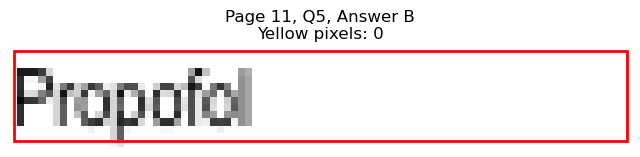

Page 11, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=110.4, y1=442.9
Page 11, Q5, C: Yellow pixels: 0
Page 11, Q5, C: Total non-white pixels: 210
Page 11, Q5, C: Yellow percentage: 0.0%


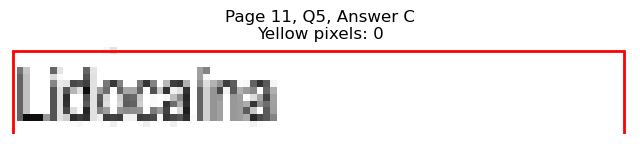

Page 11, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=368.2, y1=417.6
Page 11, Q5, D: Yellow pixels: 1045
Page 11, Q5, D: Total non-white pixels: 1288
Page 11, Q5, D: Yellow percentage: 81.1%


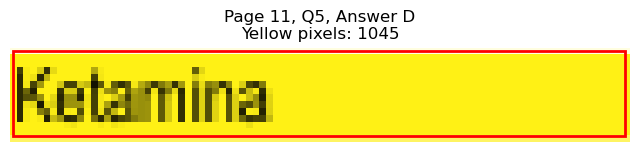

Page 11, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=379.3, y1=430.3
Page 11, Q5, E: Yellow pixels: 103
Page 11, Q5, E: Total non-white pixels: 376
Page 11, Q5, E: Yellow percentage: 27.4%


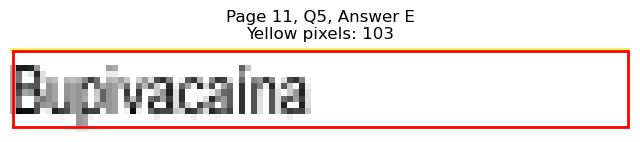


Page 11, Q5 - Selected Answer: D (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=173.2, y1=506.0
Page 11, Q6, A: Yellow pixels: 0
Page 11, Q6, A: Total non-white pixels: 502
Page 11, Q6, A: Yellow percentage: 0.0%


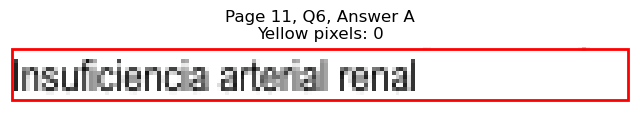

Page 11, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=168.6, y1=518.6
Page 11, Q6, B: Yellow pixels: 151
Page 11, Q6, B: Total non-white pixels: 662
Page 11, Q6, B: Yellow percentage: 22.8%


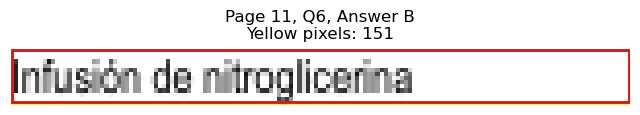

Page 11, Q6 - C: Detected box: x0=68.8, y0=518.6, x1=150.5, y1=531.2
Page 11, Q6, C: Yellow pixels: 1411
Page 11, Q6, C: Total non-white pixels: 1862
Page 11, Q6, C: Yellow percentage: 75.8%


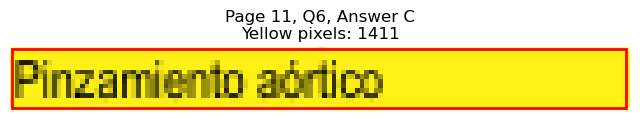

Page 11, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=437.3, y1=506.0
Page 11, Q6, D: Yellow pixels: 0
Page 11, Q6, D: Total non-white pixels: 559
Page 11, Q6, D: Yellow percentage: 0.0%


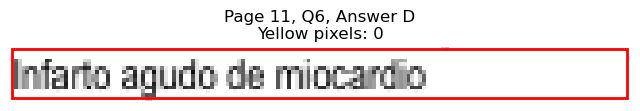

Page 11, Q6 - E: Detected box: x0=327.0, y0=506.0, x1=436.0, y1=518.6
Page 11, Q6, E: Yellow pixels: 0
Page 11, Q6, E: Total non-white pixels: 557
Page 11, Q6, E: Yellow percentage: 0.0%


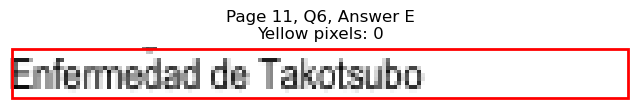


Page 11, Q6 - Selected Answer: C (based on yellow pixel count)




Page 11, Q7 - A: Detected box: x0=68.3, y0=581.7, x1=233.4, y1=594.4
Page 11, Q7, A: Yellow pixels: 0
Page 11, Q7, A: Total non-white pixels: 864
Page 11, Q7, A: Yellow percentage: 0.0%


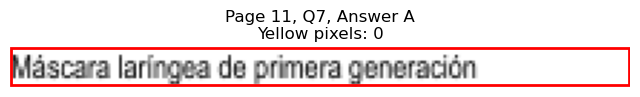

Page 11, Q7 - B: Detected box: x0=68.3, y0=594.3, x1=189.7, y1=607.0
Page 11, Q7, B: Yellow pixels: 0
Page 11, Q7, B: Total non-white pixels: 638
Page 11, Q7, B: Yellow percentage: 0.0%


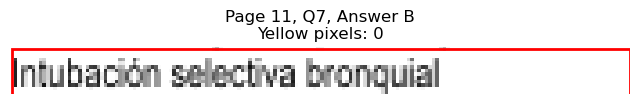

Page 11, Q7 - C: Detected box: x0=68.8, y0=606.9, x1=179.8, y1=619.6
Page 11, Q7, C: Yellow pixels: 0
Page 11, Q7, C: Total non-white pixels: 560
Page 11, Q7, C: Yellow percentage: 0.0%


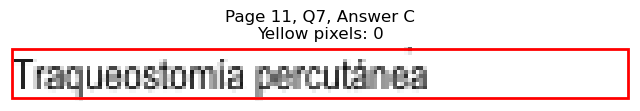

Page 11, Q7 - D: Detected box: x0=68.8, y0=619.6, x1=144.0, y1=632.3
Page 11, Q7, D: Yellow pixels: 127
Page 11, Q7, D: Total non-white pixels: 513
Page 11, Q7, D: Yellow percentage: 24.8%


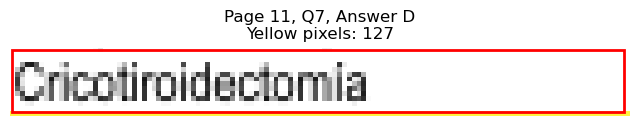

Page 11, Q7 - E: Detected box: x0=68.3, y0=632.2, x1=299.1, y1=644.9
Page 11, Q7, E: Yellow pixels: 2781
Page 11, Q7, E: Total non-white pixels: 3666
Page 11, Q7, E: Yellow percentage: 75.9%


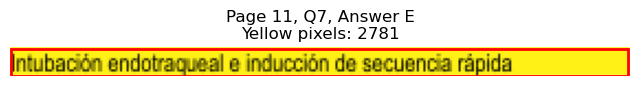


Page 11, Q7 - Selected Answer: E (based on yellow pixel count)




Page 11, Q8 - A: Detected box: x0=68.3, y0=670.1, x1=102.4, y1=682.7
Page 11, Q8, A: Yellow pixels: 0
Page 11, Q8, A: Total non-white pixels: 176
Page 11, Q8, A: Yellow percentage: 0.0%


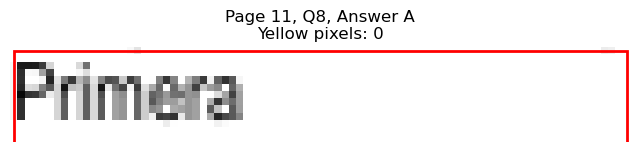

Page 11, Q8 - B: Detected box: x0=68.3, y0=682.7, x1=101.9, y1=695.3
Page 11, Q8, B: Yellow pixels: 0
Page 11, Q8, B: Total non-white pixels: 151
Page 11, Q8, B: Yellow percentage: 0.0%


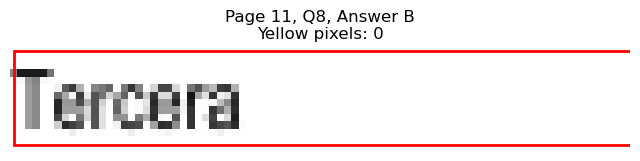

Page 11, Q8 - C: Detected box: x0=68.8, y0=695.4, x1=123.0, y1=708.0
Page 11, Q8, C: Yellow pixels: 0
Page 11, Q8, C: Total non-white pixels: 263
Page 11, Q8, C: Yellow percentage: 0.0%


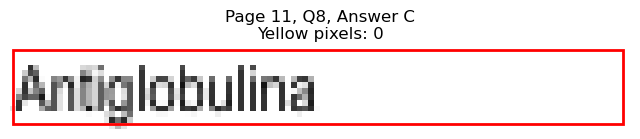

Page 11, Q8 - D: Detected box: x0=327.5, y0=670.1, x1=366.2, y1=682.7
Page 11, Q8, D: Yellow pixels: 1029
Page 11, Q8, D: Total non-white pixels: 1170
Page 11, Q8, D: Yellow percentage: 87.9%


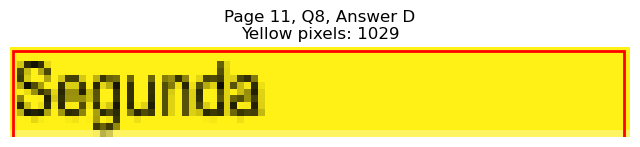

Page 11, Q8 - E: Detected box: x0=327.0, y0=682.7, x1=369.2, y1=695.3
Page 11, Q8, E: Yellow pixels: 91
Page 11, Q8, E: Total non-white pixels: 302
Page 11, Q8, E: Yellow percentage: 30.1%


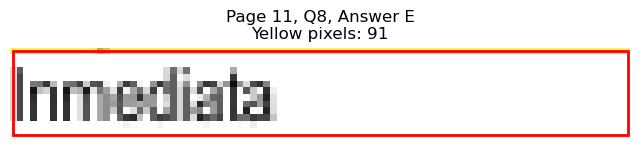


Page 11, Q8 - Selected Answer: D (based on yellow pixel count)




Page 11, Q9 - A: Detected box: x0=68.3, y0=733.2, x1=237.3, y1=745.8
Page 11, Q9, A: Yellow pixels: 0
Page 11, Q9, A: Total non-white pixels: 839
Page 11, Q9, A: Yellow percentage: 0.0%


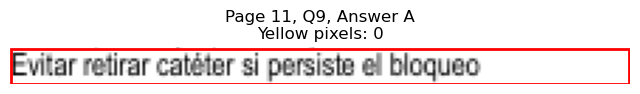

Page 11, Q9 - B: Detected box: x0=68.3, y0=745.8, x1=240.4, y1=758.4
Page 11, Q9, B: Yellow pixels: 0
Page 11, Q9, B: Total non-white pixels: 852
Page 11, Q9, B: Yellow percentage: 0.0%


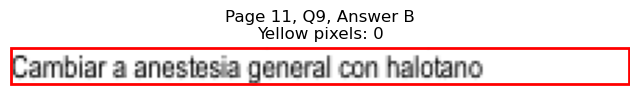

Page 11, Q9 - C: Detected box: x0=68.8, y0=758.5, x1=228.8, y1=771.2
Page 11, Q9, C: Yellow pixels: 0
Page 11, Q9, C: Total non-white pixels: 804
Page 11, Q9, C: Yellow percentage: 0.0%


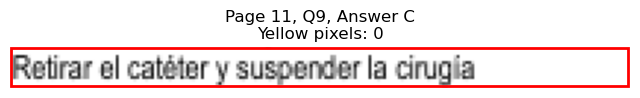

Page 11, Q9 - D: Detected box: x0=327.5, y0=733.2, x1=530.1, y1=745.8
Page 11, Q9, D: Yellow pixels: 0
Page 11, Q9, D: Total non-white pixels: 1198
Page 11, Q9, D: Yellow percentage: 0.0%


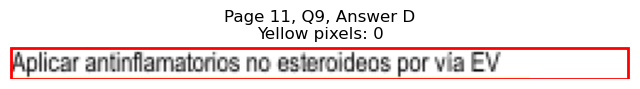

Page 11, Q9 - E: Detected box: x0=327.0, y0=745.8, x1=375.3, y1=758.4
Page 11, Q9, E: Yellow pixels: 955
Page 11, Q9, E: Total non-white pixels: 1386
Page 11, Q9, E: Yellow percentage: 68.9%


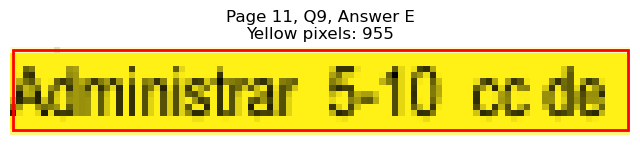


Page 11, Q9 - Selected Answer: E (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,"Mujer de 70 años, con dolor en región postolat..."
1,"Niño de 5 años, sometido a cirugía traumatológ..."
2,¿Cuál es la causa de la alcalosis metabólica q...
3,¿Cuál es un factor neurógeno que influye en el...
4,"Gestante de 36 semanas, tiene accidente automo..."
...,...
95,¿Cuál es el anestésico de acción corta que tie...
96,Varón de 55 años que es sometido a una cirugía...
97,Varón de 25 años que es sometido a una colecis...
98,En las pruebas de compatibilidad cruzada. ¿En ...


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,L5-S1,L3-L4,L4-L5,L1-L2,S1-S2
1,Ayuda de presión laríngea,Mayor dificultad para intubación traumática,Difícil intubación,Peligrosa intubación,Normal y fácil intubación
2,Hipoventilación,Aspiración nasogástrica,Narcosis,Supresión incompleta del bloqueo neuromuscular,Hiperproteinemia
3,Anestésicos,PaCO2,Temperatura,Viscosidad sanguínea,Vía extracraneal simpática
4,36,32,30,25,45
...,...,...,...,...,...
95,Fentanilo,Propofol,Lidocaína,Ketamina,Bupivacaína
96,Insuficiencia arterial renal,Infusión de nitroglicerina,Pinzamiento aórtico,Infarto agudo de miocardio,Enfermedad de Takotsubo
97,Máscara laríngea de primera generación,Intubación selectiva bronquial,Traqueostomía percutánea,Cricotiroidectomía,Intubación endotraqueal e inducción de secuenc...
98,Primera,Tercera,Antiglobulina,Segunda,Inmediata


In [9]:
correct_answers_df

,correct_answer
0,C
1,E
2,B
3,E
4,A
...,...
95,D
96,C
97,E
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,"Mujer de 70 años, con dolor en región postolat...",L5-S1,L3-L4,L4-L5,L1-L2,S1-S2,C
1,"Niño de 5 años, sometido a cirugía traumatológ...",Ayuda de presión laríngea,Mayor dificultad para intubación traumática,Difícil intubación,Peligrosa intubación,Normal y fácil intubación,E
2,¿Cuál es la causa de la alcalosis metabólica q...,Hipoventilación,Aspiración nasogástrica,Narcosis,Supresión incompleta del bloqueo neuromuscular,Hiperproteinemia,B
3,¿Cuál es un factor neurógeno que influye en el...,Anestésicos,PaCO2,Temperatura,Viscosidad sanguínea,Vía extracraneal simpática,E
4,"Gestante de 36 semanas, tiene accidente automo...",36,32,30,25,45,A
...,...,...,...,...,...,...,...
95,¿Cuál es el anestésico de acción corta que tie...,Fentanilo,Propofol,Lidocaína,Ketamina,Bupivacaína,D
96,Varón de 55 años que es sometido a una cirugía...,Insuficiencia arterial renal,Infusión de nitroglicerina,Pinzamiento aórtico,Infarto agudo de miocardio,Enfermedad de Takotsubo,C
97,Varón de 25 años que es sometido a una colecis...,Máscara laríngea de primera generación,Intubación selectiva bronquial,Traqueostomía percutánea,Cricotiroidectomía,Intubación endotraqueal e inducción de secuenc...,E
98,En las pruebas de compatibilidad cruzada. ¿En ...,Primera,Tercera,Antiglobulina,Segunda,Inmediata,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Anestesiología.csv
